In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# show what /content/drive contains and whether it's a symlink
!ls -la /content/drive || true
!readlink -f /content/drive || echo "not a symlink or no realpath"


total 12
drwxr-xr-x 3 root root 4096 May 10 10:34 .
drwxr-xr-x 1 root root 4096 May 10 10:34 ..
drwxr-xr-x 3 root root 4096 May 10 10:34 MyDrive
/content/drive


In [ ]:
# safe unmount (no Drive data will be deleted)
from google.colab import drive
try:
    drive.flush_and_unmount()
    print("flush_and_unmount succeeded (if Drive was mounted).")
except Exception as e:
    print("flush_and_unmount error (ok to continue):", e)

# remove any leftover local mountpoint and recreate it
import os, shutil
if os.path.exists('/content/drive'):
    try:
        shutil.rmtree('/content/drive')
        print("Removed local /content/drive")
    except Exception as e:
        print("Could not remove /content/drive:", e)
os.makedirs('/content/drive', exist_ok=True)
print("Recreated empty /content/drive")

Drive not mounted, so nothing to flush and unmount.
flush_and_unmount succeeded (if Drive was mounted).
Removed local /content/drive
Recreated empty /content/drive


In [ ]:
##verify current dataset location
import os

BASE = "/content/drive/MyDrive/WASTE_AI/WASTEAI/datasets"

for root, dirs, files in os.walk(BASE):
    print(root)
    break

In [ ]:
##making new folder for sanity purposes
NEW_BASE = "/content/drive/MyDrive/WASTE_AI_REBUILD"

os.makedirs(NEW_BASE, exist_ok=True)

print("Created:", NEW_BASE)

Created: /content/drive/MyDrive/WASTE_AI_REBUILD


In [ ]:
##copying required image folders into required directory
import os
import shutil

OLD_BASE = "/content/drive/MyDrive/WASTE_AI_MY_LATEST_COPY/datasets"
NEW_BASE = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/raw"

DATASETS_TO_MOVE = [
    "garbage_v2",
    "new_hazardous_additions",
    "new_wet_additions",
    "processed_taco",
    "trashnet"
]

os.makedirs(NEW_BASE, exist_ok=True)

for ds in DATASETS_TO_MOVE:
    src = os.path.join(OLD_BASE, ds)
    dst = os.path.join(NEW_BASE, ds)

    if not os.path.exists(src):
        print(f"[MISSING] {ds}")
        continue

    if os.path.exists(dst):
        print(f"[SKIP] {ds} already exists")
        continue

    shutil.copytree(src, dst)   # ✅ COPY (safe)
    print(f"[COPIED] {ds}")

KeyboardInterrupt: 

In [ ]:
NEW_PATH = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/raw"

for folder in os.listdir(NEW_PATH):
    print(folder)

garbage_v2
new_hazardous_additions
new_wet_additions
processed_taco
trashnet


In [ ]:
##per dataset remapping for our required classes and then counting to see distribution of images across the classes
import os
from collections import defaultdict

RAW_BASE = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/raw"

# Final class buckets
FINAL_CLASSES = ["dry", "wet", "hazardous", "non_hazardous"]

# Mapping rules you defined
GARBAGE_MAP = {
    "battery": "hazardous",
    "biological": "wet",
    "cardboard": "dry",
    "clothes": "non_hazardous",
    "metal": "dry",
    "glass": "hazardous",
    "paper": "dry",
    "plastic": "non_hazardous",
    "shoes": "non_hazardous",
    "trash": "non_hazardous",
}

TRASHNET_MAP = {
    "cardboard": "dry",
    "glass": "hazardous",
    "metal": "dry",
    "paper": "dry",
    "plastic": "non_hazardous",
    "trash": "non_hazardous",
}

def count_images(folder):
    return len([f for f in os.listdir(folder)
                if f.lower().endswith((".jpg",".jpeg",".png"))])

# Store results
dataset_summary = {}

# ─────────────────────────────
# 1. GARBAGE_V2
# ─────────────────────────────
g_counts = defaultdict(int)
g_path = os.path.join(RAW_BASE, "garbage_v2")

for sub in os.listdir(g_path):
    sub_path = os.path.join(g_path, sub)
    if not os.path.isdir(sub_path):
        continue

    cls = GARBAGE_MAP.get(sub)
    if cls is None:
        print(f"[SKIP garbage_v2] {sub}")
        continue

    n = count_images(sub_path)
    g_counts[cls] += n
    print(f"[garbage_v2] {sub:12} → {cls:15}: {n}")

dataset_summary["garbage_v2"] = dict(g_counts)

# ─────────────────────────────
# 2. NEW ADDITIONS
# ─────────────────────────────
new_counts = defaultdict(int)

# hazardous
haz_path = os.path.join(RAW_BASE, "new_hazardous_additions")
new_counts["hazardous"] += count_images(haz_path)

# wet
wet_path = os.path.join(RAW_BASE, "new_wet_additions")
new_counts["wet"] += count_images(wet_path)

dataset_summary["new_additions"] = dict(new_counts)

print("\n[new_additions]")
for k,v in new_counts.items():
    print(f"{k:15}: {v}")

# ─────────────────────────────
# 3. PROCESSED_TACO
# ─────────────────────────────
taco_counts = defaultdict(int)
taco_path = os.path.join(RAW_BASE, "processed_taco")

for sub in os.listdir(taco_path):
    sub_path = os.path.join(taco_path, sub)
    if not os.path.isdir(sub_path):
        continue

    n = count_images(sub_path)
    taco_counts[sub] += n
    print(f"[taco] {sub:15}: {n}")

dataset_summary["processed_taco"] = dict(taco_counts)

# ─────────────────────────────
# 4. TRASHNET
# ─────────────────────────────
tn_counts = defaultdict(int)
tn_path = os.path.join(RAW_BASE, "trashnet/data/dataset-resized")

for sub in os.listdir(tn_path):
    if sub == "__MACOSX":
        continue

    sub_path = os.path.join(tn_path, sub)
    if not os.path.isdir(sub_path):
        continue

    cls = TRASHNET_MAP.get(sub)
    if cls is None:
        print(f"[SKIP trashnet] {sub}")
        continue

    n = count_images(sub_path)
    tn_counts[cls] += n
    print(f"[trashnet] {sub:12} → {cls:15}: {n}")

dataset_summary["trashnet"] = dict(tn_counts)

# ─────────────────────────────
# FINAL TOTAL
# ─────────────────────────────
total = defaultdict(int)

for ds in dataset_summary:
    for cls, count in dataset_summary[ds].items():
        total[cls] += count

print("\n==============================")
print("TOTAL ACROSS ALL DATASETS")
print("==============================")
for cls in FINAL_CLASSES:
    print(f"{cls:15}: {total[cls]}")

[garbage_v2] battery      → hazardous      : 756
[garbage_v2] biological   → wet            : 699
[garbage_v2] cardboard    → dry            : 1411
[garbage_v2] clothes      → non_hazardous  : 1892
[garbage_v2] glass        → hazardous      : 1736
[garbage_v2] paper        → dry            : 1336
[garbage_v2] plastic      → non_hazardous  : 1597
[garbage_v2] trash        → non_hazardous  : 453
[garbage_v2] shoes        → non_hazardous  : 1449
[garbage_v2] metal        → dry            : 930

[new_additions]
hazardous      : 2740
wet            : 1986
[taco] dry            : 3954
[taco] wet            : 52
[taco] hazardous      : 147
[taco] non_hazardous  : 539
[trashnet] paper        → dry            : 594
[trashnet] plastic      → non_hazardous  : 482
[trashnet] trash        → non_hazardous  : 137
[trashnet] cardboard    → dry            : 403
[trashnet] glass        → hazardous      : 501
[trashnet] metal        → dry            : 410

TOTAL ACROSS ALL DATASETS
dry            : 9038


In [ ]:
##verifying the count in organic_waste(new wet waste images)
import os

path = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/raw/organic_dataset"

count = sum(len(files) for _, _, files in os.walk(path))
print("Organic images:", count)

Organic images: 13880


In [ ]:
#copying 2500 images to new_wet_additions
import os
import random
import shutil

# SOURCE (organic dataset)
SRC = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/raw/organic_dataset/organic"

# DESTINATION (wet additions)
DST = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/raw/new_wet_additions"

NUM_SAMPLES = 2500

# create destination if not exists
os.makedirs(DST, exist_ok=True)

# get all images
all_images = [
    f for f in os.listdir(SRC)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Total available:", len(all_images))

# safety check
if len(all_images) < NUM_SAMPLES:
    raise ValueError("Not enough images to sample from!")

# random sample
selected = random.sample(all_images, NUM_SAMPLES)

print("Sampling:", len(selected))

# copy images
for img in selected:
    src_path = os.path.join(SRC, img)

    # add prefix to avoid name clash
    new_name = f"organic_{img}"
    dst_path = os.path.join(DST, new_name)

    shutil.copy2(src_path, dst_path)

print("✅ Done copying 2500 images")

Total available: 13880
Sampling: 2500
✅ Done copying 2500 images


In [ ]:
import os

dst = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/raw/new_wet_additions"

print("Total wet images now:", len(os.listdir(dst)))

Total wet images now: 5325


In [ ]:
import os
import random
import shutil

SRC = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/raw/organic_dataset/organic"
DST = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/raw/new_wet_additions"

NUM_SAMPLES = 1000

# all source images
all_images = [
    f for f in os.listdir(SRC)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# already copied (remove prefix)
existing = set(f.replace("organic_", "") for f in os.listdir(DST))

# remaining pool
remaining = [img for img in all_images if img not in existing]

print("Remaining available:", len(remaining))

selected = random.sample(remaining, NUM_SAMPLES)

for img in selected:
    src_path = os.path.join(SRC, img)
    dst_path = os.path.join(DST, f"organic_{img}")
    shutil.copy2(src_path, dst_path)

print("✅ Added 1000 more wet images")

Remaining available: 13880
✅ Added 1000 more wet images


In [ ]:
##reducing taco dry contribution for dataset balance
import os
import random
import shutil

SRC = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/raw/processed_taco"
DST = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/processed/processed_taco_reduced"

TARGET_DRY = 800

os.makedirs(DST, exist_ok=True)

for cls in ["dry", "wet", "hazardous", "non_hazardous"]:
    src_cls = os.path.join(SRC, cls)
    dst_cls = os.path.join(DST, cls)

    if not os.path.exists(src_cls):
        continue

    os.makedirs(dst_cls, exist_ok=True)

    images = [f for f in os.listdir(src_cls)
              if f.lower().endswith((".jpg",".jpeg",".png"))]

    print(f"\n{cls}: {len(images)}")

    if cls == "dry":
        selected = random.sample(images, TARGET_DRY)
        print(f"→ reduced to {len(selected)}")
    else:
        selected = images
        print("→ kept all")

    for img in selected:
        shutil.copy2(os.path.join(src_cls, img),
                     os.path.join(dst_cls, img))

print("\n✅ TACO reduced")


dry: 3954
→ reduced to 800

wet: 52
→ kept all

hazardous: 147
→ kept all

non_hazardous: 539
→ kept all

✅ TACO reduced


In [ ]:
import os
import shutil

SRC = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/raw/trashnet/data/dataset-resized"
DST = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/processed/trashnet_filtered"

KEEP_MAP = {
    "cardboard": "dry",
    "glass": "hazardous",
    "metal": "dry",
    "paper": "dry",
    # ❌ remove plastic + trash (non_hazardous)
}

os.makedirs(DST, exist_ok=True)

for sub, cls in KEEP_MAP.items():
    src_path = os.path.join(SRC, sub)
    dst_path = os.path.join(DST, sub)

    if not os.path.exists(src_path):
        continue

    shutil.copytree(src_path, dst_path)
    print(f"[KEPT] {sub} → {cls}")

print("\n✅ trashnet filtered")

[KEPT] cardboard → dry
[KEPT] glass → hazardous
[KEPT] metal → dry
[KEPT] paper → dry

✅ trashnet filtered


In [ ]:
##reduce taco dry further
import os
import random
import shutil

SRC = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/raw/processed_taco/dry"
DST = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/processed/processed_taco_reduced/dry"

TARGET = 900

# clear old reduced folder first
for f in os.listdir(DST):
    os.remove(os.path.join(DST, f))

images = [
    f for f in os.listdir(SRC)
    if f.lower().endswith((".jpg",".jpeg",".png"))
]

selected = random.sample(images, TARGET)

for img in selected:
    shutil.copy2(
        os.path.join(SRC, img),
        os.path.join(DST, img)
    )

print("✅ Reduced taco dry to", TARGET)

✅ Reduced taco dry to 900


In [ ]:
##counting images per class for training
import os
from collections import defaultdict

BASE = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets"

FINAL_CLASSES = ["dry", "wet", "hazardous", "non_hazardous"]

# mappings (same as before)
GARBAGE_MAP = {
    "battery": "hazardous",
    "biological": "wet",
    "cardboard": "dry",
    "clothes": "non_hazardous",
    "metal": "dry",
    "glass": "hazardous",
    "paper": "dry",
    "plastic": "non_hazardous",
    "shoes": "non_hazardous",
    "trash": "non_hazardous",
}

TRASHNET_MAP = {
    "cardboard": "dry",
    "glass": "hazardous",
    "metal": "dry",
    "paper": "dry",
}

def count_images(folder):
    return len([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg",".jpeg",".png"))
    ])

total = defaultdict(int)

# ───────────── garbage_v2 ─────────────
print("\n=== GARBAGE_V2 ===")
g_path = f"{BASE}/raw/garbage_v2"

for sub in os.listdir(g_path):
    sub_path = os.path.join(g_path, sub)
    if not os.path.isdir(sub_path):
        continue

    cls = GARBAGE_MAP.get(sub)
    if cls is None:
        continue

    n = count_images(sub_path)
    total[cls] += n
    print(f"{sub:12} → {cls:15}: {n}")

# ───────────── new additions ─────────────
print("\n=== NEW ADDITIONS ===")

haz = count_images(f"{BASE}/raw/new_hazardous_additions")
wet = count_images(f"{BASE}/raw/new_wet_additions")

total["hazardous"] += haz
total["wet"] += wet

print(f"hazardous: {haz}")
print(f"wet      : {wet}")

# ───────────── processed taco reduced ─────────────
print("\n=== PROCESSED_TACO_REDUCED ===")

taco_path = f"{BASE}/processed/processed_taco_reduced"

for sub in os.listdir(taco_path):
    sub_path = os.path.join(taco_path, sub)
    if not os.path.isdir(sub_path):
        continue

    n = count_images(sub_path)
    total[sub] += n
    print(f"{sub:15}: {n}")

# ───────────── trashnet filtered ─────────────
print("\n=== TRASHNET_FILTERED ===")

tn_path = f"{BASE}/processed/trashnet_filtered"

for sub in os.listdir(tn_path):
    sub_path = os.path.join(tn_path, sub)
    if not os.path.isdir(sub_path):
        continue

    cls = TRASHNET_MAP.get(sub)
    if cls is None:
        continue

    n = count_images(sub_path)
    total[cls] += n
    print(f"{sub:12} → {cls:15}: {n}")

# ───────────── FINAL TOTAL ─────────────
print("\n==============================")
print(" FINAL CLASS DISTRIBUTION")
print("==============================")

for cls in FINAL_CLASSES:
    print(f"{cls:15}: {total[cls]}")


=== GARBAGE_V2 ===
battery      → hazardous      : 756
biological   → wet            : 699
cardboard    → dry            : 1411
clothes      → non_hazardous  : 1892
glass        → hazardous      : 1736
paper        → dry            : 1336
plastic      → non_hazardous  : 1597
trash        → non_hazardous  : 453
shoes        → non_hazardous  : 1449
metal        → dry            : 930

=== NEW ADDITIONS ===
hazardous: 2740
wet      : 5325

=== PROCESSED_TACO_REDUCED ===
dry            : 900
wet            : 52
hazardous      : 147
non_hazardous  : 539

=== TRASHNET_FILTERED ===
cardboard    → dry            : 403
glass        → hazardous      : 501
metal        → dry            : 410
paper        → dry            : 594

 FINAL CLASS DISTRIBUTION
dry            : 5984
wet            : 6076
hazardous      : 5880
non_hazardous  : 5930


In [ ]:
##copy the main modules to currrent directory
import os
import shutil

SRC = "/content/drive/MyDrive/WASTE_AI/WASTEAI"
DST = "/content/drive/MyDrive/WASTE_AI_REBUILD"

FILES = [
    "vision_model.py",
    "multimodal_fusion.py",
    "dataset.py",
    "pipeline.py",
    "uncertainty_engine.py",
    "continual_learner.py",
    "train.py",
    "xai_engine.py"
]

os.makedirs(DST, exist_ok=True)

for f in FILES:
    src_path = os.path.join(SRC, f)
    dst_path = os.path.join(DST, f)

    if not os.path.exists(src_path):
        print(f"[MISSING] {f}")
        continue

    shutil.copy2(src_path, dst_path)
    print(f"[COPIED] {f}")

print("\n✅ All core files copied successfully")

[COPIED] vision_model.py
[COPIED] multimodal_fusion.py
[COPIED] dataset.py
[COPIED] pipeline.py
[COPIED] uncertainty_engine.py
[COPIED] continual_learner.py
[COPIED] train.py
[COPIED] xai_engine.py

✅ All core files copied successfully


In [ ]:
%cd /content/drive/MyDrive/WASTE_AI_REBUILD

/content/drive/MyDrive/WASTE_AI_REBUILD


In [ ]:
import os
print(os.getcwd())
print(os.listdir())

/content/drive/MyDrive/WASTE_AI_REBUILD
['datasets', 'vision_model.py', 'multimodal_fusion.py', 'dataset.py', 'pipeline.py', 'uncertainty_engine.py', 'continual_learner.py', 'train.py', 'xai_engine.py', '__pycache__']


In [ ]:
##cache the glcm features computed using cpu to avoid it being the bottleneck during model training using gpu
# ============================================
# 🚀 FAST GLCM PRECOMPUTE + CACHE (MULTIPROCESS)
# ============================================

import os
import torch
import numpy as np
import cv2
from PIL import Image
from pathlib import Path
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
from skimage.feature import graycomatrix, graycoprops

# ─────────────────────────────
# CONFIG
# ─────────────────────────────
DATASET_ROOT = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets"
CACHE_PATH   = "/content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt"

IMAGE_EXTS = (".jpg", ".jpeg", ".png")

# Speed tweaks
RESIZE = 128     # ⚡ smaller → faster
LEVELS = 64      # ⚡ fewer gray levels → faster


# ─────────────────────────────
# GLCM FEATURE FUNCTION
# ─────────────────────────────
def compute_glcm_features(img_path):
    try:
        img = Image.open(img_path).convert("L")
        img = np.array(img)

        # resize smaller for speed
        img = cv2.resize(img, (RESIZE, RESIZE))

        # quantize to fewer levels
        img = (img / (256 // LEVELS)).astype(np.uint8)

        glcm = graycomatrix(
            img,
            distances=[1],
            angles=[0],
            levels=LEVELS,
            symmetric=True,
            normed=True
        )

        contrast    = graycoprops(glcm, 'contrast')[0, 0]
        homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
        energy      = graycoprops(glcm, 'energy')[0, 0]
        entropy     = -np.sum(glcm * np.log2(glcm + 1e-8))
        variance    = np.var(img) / LEVELS

        feat = torch.tensor([
            contrast / 1000.0,
            homogeneity,
            energy,
            entropy / 10.0,
            variance
        ], dtype=torch.float32)

        return str(img_path), feat

    except Exception as e:
        return None


# ─────────────────────────────
# COLLECT ALL IMAGE PATHS
# ─────────────────────────────
print("🔍 Scanning dataset...")

all_images = []
for root, _, files in os.walk(DATASET_ROOT):
    for f in files:
        if f.lower().endswith(IMAGE_EXTS):
            all_images.append(os.path.join(root, f))

print(f"✅ Found {len(all_images)} images")


# ─────────────────────────────
# LOAD EXISTING CACHE (if exists)
# ─────────────────────────────
if os.path.exists(CACHE_PATH):
    print("📦 Loading existing cache...")
    cache = torch.load(CACHE_PATH)
else:
    cache = {}

print(f"📊 Already cached: {len(cache)}")


# ─────────────────────────────
# FILTER ONLY NEW IMAGES
# ─────────────────────────────
to_process = [p for p in all_images if p not in cache]

print(f"🆕 To process: {len(to_process)}")


# ─────────────────────────────
# MULTIPROCESSING
# ─────────────────────────────
print("🚀 Starting multiprocessing GLCM extraction...")

NUM_WORKERS = max(2, cpu_count() - 2)

with Pool(NUM_WORKERS) as pool:
    for result in tqdm(pool.imap_unordered(compute_glcm_features, to_process), total=len(to_process)):
        if result is None:
            continue
        path, feat = result
        cache[path] = feat


# ─────────────────────────────
# SAVE CACHE
# ─────────────────────────────
torch.save(cache, CACHE_PATH)

print("\n✅ DONE!")
print(f"📦 Total cached: {len(cache)}")
print(f"💾 Saved to: {CACHE_PATH}")

🔍 Scanning dataset...
✅ Found 44970 images
📊 Already cached: 0
🆕 To process: 44970
🚀 Starting multiprocessing GLCM extraction...


100%|██████████| 44970/44970 [07:11<00:00, 104.16it/s]



✅ DONE!
📦 Total cached: 44969
💾 Saved to: /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt


In [ ]:
##loading the cached GLCM matrices before training
from dataset import load_texture_cache

load_texture_cache("./texture_cache.pt")

📦 Loading texture cache from ./texture_cache.pt...
✅ Loaded 44969 cached features


In [ ]:
import os
import shutil
from pathlib import Path
from tqdm import tqdm
import uuid

BASE = Path("/content/drive/MyDrive/WASTE_AI_REBUILD/datasets")
RAW = BASE / "raw"
FINAL = BASE / "final"

FINAL_CLASSES = ["dry", "wet", "hazardous", "non_hazardous"]

for cls in FINAL_CLASSES:
    (FINAL / cls).mkdir(parents=True, exist_ok=True)

def copy_images(src_folder, target_class):
    dst = FINAL / target_class

    for img in src_folder.rglob("*"):
        if img.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            new_name = f"{uuid.uuid4().hex}_{img.name}"
            shutil.copy2(img, dst / new_name)


# ───────────── garbage_v2 ─────────────
GARBAGE_MAP = {
    "battery": "hazardous",
    "biological": "wet",
    "cardboard": "dry",
    "clothes": "non_hazardous",
    "metal": "dry",
    "glass": "hazardous",
    "paper": "dry",
    "plastic": "non_hazardous",
    "shoes": "non_hazardous",
    "trash": "non_hazardous",
}

g_path = RAW / "garbage_v2"
for sub, cls in GARBAGE_MAP.items():
    src = g_path / sub
    if src.exists():
        copy_images(src, cls)


# ───────────── new additions ─────────────
copy_images(RAW / "new_hazardous_additions", "hazardous")
copy_images(RAW / "new_wet_additions", "wet")


# ───────────── taco reduced ─────────────
taco = BASE / "processed" / "processed_taco_reduced"
for cls in FINAL_CLASSES:
    src = taco / cls
    if src.exists():
        copy_images(src, cls)


# ───────────── trashnet filtered ─────────────
TRASHNET_MAP = {
    "cardboard": "dry",
    "glass": "hazardous",
    "metal": "dry",
    "paper": "dry",
}

tn = BASE / "processed" / "trashnet_filtered"
for sub, cls in TRASHNET_MAP.items():
    src = tn / sub
    if src.exists():
        copy_images(src, cls)


print("✅ FINAL DATASET READY")

✅ FINAL DATASET READY


In [ ]:
##delete cache and get a new one for glcm features cuz of path clash
import os

os.remove("./texture_cache.pt")
print("❌ Old cache deleted")

❌ Old cache deleted


In [ ]:
import os
import torch
import numpy as np
import cv2
from PIL import Image
from pathlib import Path
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
from skimage.feature import graycomatrix, graycoprops

DATASET_ROOT = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/final"
CACHE_PATH   = "/content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt"

IMAGE_EXTS = (".jpg", ".jpeg", ".png")

RESIZE = 128
LEVELS = 64


def compute_glcm_features(img_path):
    try:
        img = Image.open(img_path).convert("L")
        img = np.array(img)

        img = cv2.resize(img, (RESIZE, RESIZE))
        img = (img / (256 // LEVELS)).astype(np.uint8)

        glcm = graycomatrix(
            img,
            distances=[1],
            angles=[0],
            levels=LEVELS,
            symmetric=True,
            normed=True
        )

        contrast    = graycoprops(glcm, 'contrast')[0, 0]
        homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
        energy      = graycoprops(glcm, 'energy')[0, 0]
        entropy     = -np.sum(glcm * np.log2(glcm + 1e-8))
        variance    = np.var(img) / LEVELS

        feat = torch.tensor([
            contrast / 1000.0,
            homogeneity,
            energy,
            entropy / 10.0,
            variance
        ], dtype=torch.float32)

        return str(img_path), feat

    except:
        return None


print("🔍 Scanning FINAL dataset...")

all_images = []
for root, _, files in os.walk(DATASET_ROOT):
    for f in files:
        if f.lower().endswith(IMAGE_EXTS):
            all_images.append(os.path.join(root, f))

print(f"✅ Found {len(all_images)} images")


cache = {}

print("🚀 Computing GLCM (this will take ~30–40 mins)...")

with Pool(max(2, cpu_count() - 2)) as pool:
    for result in tqdm(pool.imap_unordered(compute_glcm_features, all_images), total=len(all_images)):
        if result:
            path, feat = result
            cache[path] = feat


torch.save(cache, CACHE_PATH)

print(f"\n✅ DONE! Saved {len(cache)} features")

🔍 Scanning FINAL dataset...
✅ Found 21119 images
🚀 Computing GLCM (this will take ~30–40 mins)...


100%|██████████| 21119/21119 [39:58<00:00,  8.81it/s]



✅ DONE! Saved 21119 features


In [ ]:
!python train.py \
  --data_root "./datasets/final" \
  --epochs 25 \
  --batch_size 32 \
  --lr 1e-4 \
  --output_dir "./checkpoints" \
  --texture_cache_path "./texture_cache.pt"

[INFO] Using device: cuda
📦 Loading texture cache from ./texture_cache.pt...
✅ Loaded 21119 cached features
📊 Total samples: 21119
TRAIN: 14783 | VAL: 3168 | TEST: 3168

Epoch   TrainAcc   ValAcc
  1     86.61%     95.39%
  2     95.10%     96.02%
  3     96.74%     96.75%
  4     97.82%     97.29%
  5     98.32%     96.91%
  6     98.53%     97.06%
  7     98.80%     97.10%
  8     98.79%     97.19%
  9     99.22%     97.25%
 10     99.35%     97.57%
 11     99.36%     97.13%
 12     99.38%     97.82%
 13     99.59%     97.47%
 14     99.59%     97.60%
 15     99.61%     97.66%
 16     99.67%     97.57%
 17     99.70%     97.82%
 18     99.74%     97.60%
 19     99.80%     97.82%
 20     99.87%     97.60%
 21     99.90%     97.76%
 22     99.89%     97.79%
 23     99.90%     97.95%
 24     99.86%     97.95%
 25     99.91%     97.92%

✅ Best Validation Accuracy: 97.95%


In [ ]:
##copy test folder
import shutil
import os

src = "/content/drive/MyDrive/WASTE_AI/WASTEAI/datasets/test_manual"
dst = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/test_manual"

# Remove destination if it already exists (optional but clean)
if os.path.exists(dst):
    shutil.rmtree(dst)

# Copy entire folder
shutil.copytree(src, dst)

print("✅ test_manual copied successfully!")

✅ test_manual copied successfully!


In [ ]:
import sys
sys.path.append("/content/drive/MyDrive/WASTE_AI_REBUILD")

📦 Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt...
✅ Loaded 21119 cached features
📊 Total samples: 21119
TRAIN: 14783 | VAL: 3168 | TEST: 3168
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 103MB/s]
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



📊 Classification Report:

               precision    recall  f1-score   support

          dry       1.00      0.99      1.00       554
          wet       0.99      1.00      1.00       905
    hazardous       1.00      0.99      1.00       828
non_hazardous       1.00      1.00      1.00       881

     accuracy                           1.00      3168
    macro avg       1.00      1.00      1.00      3168
 weighted avg       1.00      1.00      1.00      3168


✅ Accuracy: 99.68%


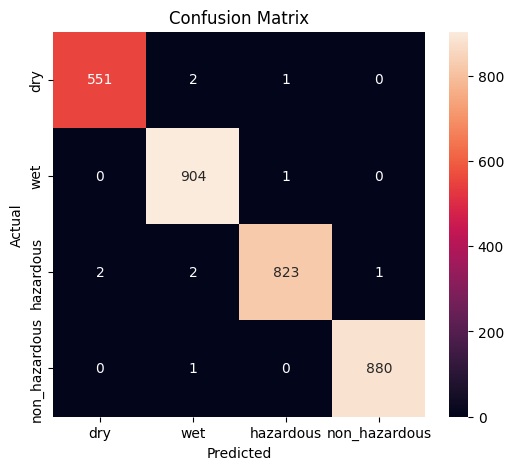

In [ ]:
import sys
sys.path.append("/content/drive/MyDrive/WASTE_AI_REBUILD")

import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

from vision_model import WasteVisionModel
from multimodal_fusion import MultimodalWasteClassifier
from dataset import build_dataloaders, load_texture_cache

# ─────────────────────────────
# CONFIG
# ─────────────────────────────
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

DATA_ROOT = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/final"
TEXTURE_CACHE = "/content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt"

VISION_PATH = "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/vision_best.pt"
FUSION_PATH = "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/fusion_best.pt"

# ─────────────────────────────
# LOAD DATA
# ─────────────────────────────
load_texture_cache(TEXTURE_CACHE)

train_dl, val_dl, test_dl = build_dataloaders(DATA_ROOT, batch_size=32)

# ─────────────────────────────
# LOAD MODELS
# ─────────────────────────────
vision = WasteVisionModel().to(DEVICE)
fusion = MultimodalWasteClassifier(img_feat_dim=vision.feat_dim).to(DEVICE)

vision.load_state_dict(torch.load(VISION_PATH, map_location=DEVICE))
fusion.load_state_dict(torch.load(FUSION_PATH, map_location=DEVICE))

vision.eval()
fusion.eval()

# ─────────────────────────────
# EVALUATION
# ─────────────────────────────
y_true = []
y_pred = []

with torch.no_grad():
    for imgs, labels, meta in test_dl:
        imgs = imgs.to(DEVICE)
        labels = labels.to(DEVICE)
        meta = meta.to(DEVICE)

        feats = vision.get_features(imgs)
        out = fusion(feats, meta)

        preds = out["logits"].argmax(1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

# ─────────────────────────────
# METRICS
# ─────────────────────────────
print("\n📊 Classification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=["dry", "wet", "hazardous", "non_hazardous"]
))

acc = accuracy_score(y_true, y_pred)
print(f"\n✅ Accuracy: {acc*100:.2f}%")

# ─────────────────────────────
# CONFUSION MATRIX
# ─────────────────────────────
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["dry","wet","hazardous","non_hazardous"],
            yticklabels=["dry","wet","hazardous","non_hazardous"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
##patch pipeline.py
import sys, os

PIPELINE_PATH = "/content/drive/MyDrive/WASTE_AI_REBUILD/pipeline.py"

# Read file
with open(PIPELINE_PATH, "r") as f:
    code = f.read()

# Fix import
code = code.replace(
    "from dataset import extract_texture_features",
    "from dataset import get_texture_feature"
)

# Fix metadata extraction
code = code.replace(
    "meta = extract_texture_features(img_pil).unsqueeze(0).to(self.device)",
    """try:
            meta = get_texture_feature(img_path).unsqueeze(0).to(self.device)
        except:
            meta = None"""
)

# Write back
with open(PIPELINE_PATH, "w") as f:
    f.write(code)

print("✅ pipeline.py fixed successfully")

✅ pipeline.py fixed successfully


CHANGES FROM GEMINI START FROM HERE

In [ ]:
# This cell is no longer needed as GLCM features are loaded from cache.
# Keeping it as a placeholder or it can be deleted if no longer needed for any other purpose.
# If you need to re-enable on-the-fly GLCM computation for uncached items,
# you would import this function into the relevant cell and use it as a fallback.
import numpy as np
import torch
import cv2
from skimage.feature import graycomatrix, graycoprops

def extract_texture_features(img_pil):
    # Convert to grayscale
    img = np.array(img_pil.convert("L"))

    # Resize (important for consistency)
    img = cv2.resize(img, (224, 224))

    # Quantize (reduce levels)
    img = (img / 32).astype(np.uint8)

    # GLCM
    glcm = graycomatrix(
        img,
        distances=[1],
        angles=[0],
        levels=8,
        symmetric=True,
        normed=True
    )

    # Extract features
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]

    entropy = -np.sum(glcm * np.log(glcm + 1e-8))

    features = np.array([
        contrast,
        homogeneity,
        energy,
        correlation,
        entropy
    ], dtype=np.float32)

    return torch.tensor(features)

COMPUTING CACHE FOR TEST_MANUAL

In [ ]:
import os
import torch
import numpy as np
import cv2
from PIL import Image
from pathlib import Path
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
from skimage.feature import graycomatrix, graycoprops

# Configuration for GLCM computation
TEST_DIR = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/test_manual"
REBUILD = "/content/drive/MyDrive/WASTE_AI_REBUILD"
CACHE_PATH_TEST_MANUAL = os.path.join(REBUILD, "texture_cache_test_manual.pt")

IMAGE_EXTS = (".jpg", ".jpeg", ".png")
RESIZE = 128
LEVELS = 64

# Re-define GLCM feature computation function
def compute_glcm_features_for_test(img_path):
    try:
        img = Image.open(img_path).convert("L")
        img = np.array(img)

        img = cv2.resize(img, (RESIZE, RESIZE))
        img = (img / (256 // LEVELS)).astype(np.uint8)

        glcm = graycomatrix(
            img,
            distances=[1],
            angles=[0],
            levels=LEVELS,
            symmetric=True,
            normed=True
        )

        contrast    = graycoprops(glcm, 'contrast')[0, 0]
        homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
        energy      = graycoprops(glcm, 'energy')[0, 0]
        entropy     = -np.sum(glcm * np.log2(glcm + 1e-8))
        variance    = np.var(img) / LEVELS

        feat = torch.tensor([
            contrast / 1000.0,
            homogeneity,
            energy,
            entropy / 10.0,
            variance
        ], dtype=torch.float32)

        return str(img_path), feat

    except Exception as e:
        # print(f"Error computing GLCM for {img_path}: {e}")
        return None

print(f"🔍 Scanning test_manual directory: {TEST_DIR}...")
all_test_images = []
for root, _, files in os.walk(TEST_DIR):
    for f in files:
        if f.lower().endswith(IMAGE_EXTS):
            all_test_images.append(os.path.join(root, f))

print(f"✅ Found {len(all_test_images)} images in test_manual.")

# Load existing test cache if it exists
if os.path.exists(CACHE_PATH_TEST_MANUAL):
    print(f"📦 Loading existing test cache from {CACHE_PATH_TEST_MANUAL}...")
    test_cache = torch.load(CACHE_PATH_TEST_MANUAL)
else:
    test_cache = {}
print(f"📊 Already cached for test_manual: {len(test_cache)}")

# Filter only new images to process
to_process_test = [p for p in all_test_images if p not in test_cache]
print(f"🆕 To process for test_manual: {len(to_process_test)}")

if len(to_process_test) > 0:
    print("🚀 Starting multiprocessing GLCM extraction for test_manual...")
    NUM_WORKERS = max(2, cpu_count() - 2)
    with Pool(NUM_WORKERS) as pool:
        for result in tqdm(pool.imap_unordered(compute_glcm_features_for_test, to_process_test), total=len(to_process_test)):
            if result is None:
                continue
            path, feat = result
            test_cache[path] = feat

    torch.save(test_cache, CACHE_PATH_TEST_MANUAL)
    print(f"\n✅ DONE! Total cached for test_manual: {len(test_cache)}")
    print(f"💾 Saved to: {CACHE_PATH_TEST_MANUAL}")
else:
    print("✅ No new test_manual images to process or cache is up-to-date.")

🔍 Scanning test_manual directory: /content/drive/MyDrive/WASTE_AI_REBUILD/datasets/test_manual...
✅ Found 231 images in test_manual.
📊 Already cached for test_manual: 0
🆕 To process for test_manual: 231
🚀 Starting multiprocessing GLCM extraction for test_manual...


100%|██████████| 231/231 [00:34<00:00,  6.78it/s]


✅ DONE! Total cached for test_manual: 231
💾 Saved to: /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_test_manual.pt


VERIFYING IF IT EXISTS FOR EVERYTHING IN THE TEST MANUAL

In [ ]:
import os
import torch
import numpy as np
import cv2
from PIL import Image
from pathlib import Path
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
from skimage.feature import graycomatrix, graycoprops

# Configuration for GLCM computation
TEST_DIR = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/test_manual"
REBUILD = "/content/drive/MyDrive/WASTE_AI_REBUILD"
CACHE_PATH_TEST_MANUAL = os.path.join(REBUILD, "texture_cache_test_manual.pt")

IMAGE_EXTS = (".jpg", ".jpeg", ".png")
RESIZE = 128
LEVELS = 64

# Re-define GLCM feature computation function
def compute_glcm_features_for_test(img_path):
    try:
        img = Image.open(img_path).convert("L")
        img = np.array(img)

        img = cv2.resize(img, (RESIZE, RESIZE))
        img = (img / (256 // LEVELS)).astype(np.uint8)

        glcm = graycomatrix(
            img,
            distances=[1],
            angles=[0],
            levels=LEVELS,
            symmetric=True,
            normed=True
        )

        contrast    = graycoprops(glcm, 'contrast')[0, 0]
        homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
        energy      = graycoprops(glcm, 'energy')[0, 0]
        entropy     = -np.sum(glcm * np.log2(glcm + 1e-8))
        variance    = np.var(img) / LEVELS

        feat = torch.tensor([
            contrast / 1000.0,
            homogeneity,
            energy,
            entropy / 10.0,
            variance
        ], dtype=torch.float32)

        return str(img_path), feat

    except Exception as e:
        # print(f"Error computing GLCM for {img_path}: {e}")
        return None

print(f"🔍 Scanning test_manual directory: {TEST_DIR}...")
all_test_images = []
for root, _, files in os.walk(TEST_DIR):
    for f in files:
        if f.lower().endswith(IMAGE_EXTS):
            all_test_images.append(os.path.join(root, f))

print(f"✅ Found {len(all_test_images)} images in test_manual.")

# Load existing test cache if it exists
if os.path.exists(CACHE_PATH_TEST_MANUAL):
    print(f"📦 Loading existing test cache from {CACHE_PATH_TEST_MANUAL}...")
    test_cache = torch.load(CACHE_PATH_TEST_MANUAL)
else:
    test_cache = {}
print(f"📊 Already cached for test_manual: {len(test_cache)}")

# Filter only new images to process
to_process_test = [p for p in all_test_images if p not in test_cache]
print(f"🆕 To process for test_manual: {len(to_process_test)}")

if len(to_process_test) > 0:
    print("🚀 Starting multiprocessing GLCM extraction for test_manual...")
    NUM_WORKERS = max(2, cpu_count() - 2)
    with Pool(NUM_WORKERS) as pool:
        for result in tqdm(pool.imap_unordered(compute_glcm_features_for_test, to_process_test), total=len(to_process_test)):
            if result is None:
                continue
            path, feat = result
            test_cache[path] = feat

    torch.save(test_cache, CACHE_PATH_TEST_MANUAL)
    print(f"\n✅ DONE! Total cached for test_manual: {len(test_cache)}")
    print(f"💾 Saved to: {CACHE_PATH_TEST_MANUAL}")
else:
    print("✅ No new test_manual images to process or cache is up-to-date.")

🔍 Scanning test_manual directory: /content/drive/MyDrive/WASTE_AI_REBUILD/datasets/test_manual...
✅ Found 231 images in test_manual.
📦 Loading existing test cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_test_manual.pt...
📊 Already cached for test_manual: 231
🆕 To process for test_manual: 0
✅ No new test_manual images to process or cache is up-to-date.


In [ ]:
print(stack.var().item())

0.1605626344680786


#NEW MEMBER MODIFICATIONS

In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 0: Mount Drive & set project root
# ═══════════════════════════════════════════════════════════

'''from google.colab import drive
drive.mount('/content/drive')

import os

REBUILD = "/content/drive/MyDrive/WASTE_AI_REBUILD"
os.makedirs(REBUILD, exist_ok=True)
os.chdir(REBUILD)

print(f"Project root: {REBUILD}")
print(f"Contents: {os.listdir(REBUILD)}")

# Verify key folders exist
for folder in ["datasets/final/dry", "datasets/final/wet",
               "datasets/final/hazardous", "datasets/final/non_hazardous",
               "checkpoints"]:
    path = os.path.join(REBUILD, folder)
    status = "✅" if os.path.exists(path) else "❌"
    print(f"  {status} {folder}")

# Verify model checkpoints exist
for ckpt in ["checkpoints/vision_best.pt", "checkpoints/fusion_best.pt"]:
    path = os.path.join(REBUILD, ckpt)
    if os.path.exists(path):
        print(f"  ✅ {ckpt} ({os.path.getsize(path):,} bytes)")
    else:
        print(f"  ❌ {ckpt} MISSING — need trained model before continual learning")'''

Mounted at /content/drive
Project root: /content/drive/MyDrive/WASTE_AI_REBUILD
Contents: ['datasets', '__pycache__', 'checkpoints', 'texture_cache.pt', 'dataset.py', 'train.py', 'uncertainty_engine.py', 'vision_model.py', 'xai_engine.py', 'pipeline.py', 'multimodal_fusion.py', 'continual_learner.py', 'new_dataset.py', 'new_pipeline.py', 'new_continual_learner.py', 'Glass.folder.zip']
  ✅ datasets/final/dry
  ✅ datasets/final/wet
  ✅ datasets/final/hazardous
  ✅ datasets/final/non_hazardous
  ✅ checkpoints
  ✅ checkpoints/vision_best.pt (47,030,819 bytes)
  ✅ checkpoints/fusion_best.pt (976,853 bytes)


In [ ]:
import os, zipfile

ZIP_PATH = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/Glass.folder.zip"

if not os.path.exists(ZIP_PATH):
    print("❌ File not found at:", ZIP_PATH)
else:
    print(f"✅ Found: {ZIP_PATH} ({os.path.getsize(ZIP_PATH):,} bytes)")

✅ Found: /content/drive/MyDrive/WASTE_AI_REBUILD/datasets/Glass.folder.zip (99,366,709 bytes)


# DO NOT RERUN

In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 2b: Unzip to Colab local storage (faster than Drive)
# ═══════════════════════════════════════════════════════════

'''import os, zipfile

ZIP_PATH = ZIP_PATH  # from previous cell

if ZIP_PATH and os.path.exists(ZIP_PATH):
    EXTRACT_DIR = "/content/glass_images"

    # Remove old extraction if exists
    if os.path.exists(EXTRACT_DIR):
        import shutil
        shutil.rmtree(EXTRACT_DIR)

    print(f"📦 Unzipping {ZIP_PATH}...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_DIR)

    # Show extracted structure
    print("\n📁 Extracted structure:")
    for root, dirs, files in os.walk(EXTRACT_DIR):
        depth = root.replace(EXTRACT_DIR, "").count(os.sep)
        indent = "  " * depth
        num_imgs = len([f for f in files if f.lower().endswith(('.jpg','.jpeg','.png'))])
        if num_imgs > 0 or depth <= 2:
            print(f"{indent}{os.path.basename(root)}/  ({num_imgs} images)")

    # Find the actual image folder (deepest folder with images)
    IMAGE_FOLDER = None
    max_imgs = 0
    for root, dirs, files in os.walk(EXTRACT_DIR):
        imgs = [f for f in files if f.lower().endswith(('.jpg','.jpeg','.png'))]
        if len(imgs) > max_imgs:
            max_imgs = len(imgs)
            IMAGE_FOLDER = root

    print(f"\n✅ Image folder: {IMAGE_FOLDER}")
    print(f"   Total images: {max_imgs}")

    # Show sample filenames
    if IMAGE_FOLDER:
        sample_files = sorted([f for f in os.listdir(IMAGE_FOLDER)
                              if f.lower().endswith(('.jpg','.jpeg','.png'))])[:15]
        print(f"\n📋 Sample filenames:")
        for f in sample_files:
            print(f"   {f}")
else:
    print("❌ Zip file not found!")
    IMAGE_FOLDER = None'''

📦 Unzipping /content/drive/MyDrive/WASTE_AI_REBUILD/datasets/Glass.folder.zip...

📁 Extracted structure:
glass_images/  (0 images)
  train/  (0 images)
    Glass/  (296 images)

✅ Image folder: /content/glass_images/train/Glass
   Total images: 296

📋 Sample filenames:
   1-1-348060_l_jpg.rf.6frsEF4Et0MLRWYuPixv.jpg
   1-161649_large_jpg.rf.gk0gSA1Zt3SsJkBITNeG.jpg
   1-314720_1_jpg.rf.iiP5LPXMGlQcZGccAgkA.jpg
   1-370176148_jpg.rf.YeyI4vSGgicJi0Abek8f.jpg
   1-8709_1d_02_jpg.rf.CR1Z4jKSlPqn0f0mUZLu.jpg
   1-B-Glass-Hero-scaled_jpeg.rf.6RZUe6oWnUeT1u0L96nv.jpeg
   1-Glass-Bottle-Waste-Helps-Produce-Energy_jpg.rf.wW0wfrEoqIHmluCUflKX.jpg
   1-H20655-L218660063_jpg.rf.80Qg63QQwDwlxQX9EArF.jpg
   1-IMG_8506_jpeg.rf.gdJex9wdY6TRHbLEcNjh.jpeg
   1-broken-glass-cup-broken-transparent-glass-cup-two-symmetrical-parts-closeup-109045507_jpg.rf.DnRln3tRXZHmUiWzWLlR.jpg
   1-broken-mug-glass-glassware-oJVdda7-600_jpg.rf.C7R8QuhjuBo59WtD6EgS.jpg
   1-broken_glass_bottle_jpg.rf.Ga6gOcFq3MYbufkqV95P.

# DO NOT RERUN

In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 3 FIX: Properly install CLIP
# ═══════════════════════════════════════════════════════════

# Install dependencies first (the quiet flag hid errors before)
'''!pip install ftfy regex tqdm --quiet
!pip install git+https://github.com/openai/CLIP.git

# Verify
try:
    import clip
    print("✅ CLIP imported successfully")
    print(f"   Available models: {clip.available_models()[:3]}")
except ImportError as e:
    print(f"❌ CLIP still failed: {e}")'''

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.6 MB/s eta 0:00:00
  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-bq3qcybl
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-bq3qcybl
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Preparing metadata (setup.py) ... done
  Created wheel for clip: filename=clip-1.0-py3-none-any.whl size=1369490 sha256=f9ae459bd7658470dd3807b607dfdcc8e307f207c706b5123fc2fc6c929dab4a
  Stored in directory: /tmp/pip-ephem-wheel-cache-3u26uoz7/wheels/35/3e/df/3d24cbfb3b6a06f17a2bfd7d1138900d4365d9028aa8f6e92f
Successfully built clip
✅ CLIP imported successfully
   Available models: ['RN50', 'RN101', 'RN50x4']


# DO NOT RERUN

In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 3d REVISED: Route ALL images to hazardous BY DEFAULT
# Then use CLIP to flag non-glass items for review
# ═══════════════════════════════════════════════════════════
# Logic:
#   - Dataset is called "Glass" → assume all are glass
#   - Team decision: glass = hazardous → all glass → hazardous
#   - CLIP flags potential non-glass items → human verifies
#   - Keyword "broken" is noted but doesn't change the routing
#     (both broken and intact glass go to hazardous)

'''import os, torch, shutil
from PIL import Image
from tqdm import tqdm
from collections import Counter

IMAGE_FOLDER = IMAGE_FOLDER if 'IMAGE_FOLDER' in dir() and IMAGE_FOLDER else "/content/glass_images/train/Glass"
REBUILD = "/content/drive/MyDrive/WASTE_AI_REBUILD"

device = "cuda" if torch.cuda.is_available() else "cpu"

# ── CLIP setup (reuse from earlier) ──
import clip
clip_model, clip_preprocess = clip.load("ViT-B/32", device=device)
clip_model.eval()

# Better prompts — distinguish "waste glass" from "non-glass items"
CATEGORIES = {
    "waste_glass": [
        "glass bottle or jar for recycling",
        "broken glass shards on the ground",
        "a glass cup drinking glass",
        "glass window pane",
        "glass object transparent",
        "shattered glass debris",
        "clear glass container",
        "mirror glass surface",
    ],
    "non_glass": [
        "a pair of sunglasses or eyewear",
        "eyeglasses with plastic frames",
        "a phone or tablet with screen",
        "plastic container or bottle",
        "something that is not made of glass",
    ],
}

all_prompts = []
prompt_to_cat = []
for cat, prompts in CATEGORIES.items():
    for p in prompts:
        all_prompts.append(p)
        prompt_to_cat.append(cat)

text_tokens = clip.tokenize(all_prompts).to(device)
with torch.no_grad():
    text_features = clip_model.encode_text(text_tokens)
    text_features /= text_features.norm(dim=-1, keepdim=True)

cat_names = list(CATEGORIES.keys())
cat_features = {}
for cat in cat_names:
    indices = [i for i, c in enumerate(prompt_to_cat) if c == cat]
    feats = text_features[indices].mean(dim=0)
    feats /= feats.norm()
    cat_features[cat] = feats

cat_matrix = torch.stack([cat_features[c] for c in cat_names]).T

# ── Classify ──
# Reset results completely
results = {}

image_files = sorted([
    f for f in os.listdir(IMAGE_FOLDER)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
])

print(f"Processing {len(image_files)} images...")
print("Default: ALL → glass (hazardous)")
print("CLIP flags: potential non-glass items for human review\n")

for fname in tqdm(image_files, desc="Classifying"):
    fpath = os.path.join(IMAGE_FOLDER, fname)

    # Default assumption: it's glass → hazardous
    # CLIP only used to FLAG non-glass items

    try:
        img = clip_preprocess(Image.open(fpath).convert("RGB")).unsqueeze(0).to(device)
        with torch.no_grad():
            img_feat = clip_model.encode_image(img)
            img_feat /= img_feat.norm(dim=-1, keepdim=True)
            sims = (img_feat @ cat_matrix).squeeze(0)
            probs = sims.softmax(dim=0)

            waste_glass_score = probs[0].item()
            non_glass_score   = probs[1].item()

            if non_glass_score > 0.55:
                # CLIP thinks this is NOT glass → flag for review
                results[fname] = "flagged_non_glass"
            else:
                # Default: glass → hazardous
                if "broken" in fname.lower() or "shatter" in fname.lower() or "crack" in fname.lower():
                    results[fname] = "glass_broken"
                else:
                    results[fname] = "glass_intact"

    except Exception as e:
        results[fname] = "error"

# ── Summary ──
counts = Counter(results.values())
print("\n" + "=" * 50)
print("REVISED CLASSIFICATION RESULTS")
print("=" * 50)
for cat, count in counts.most_common():
    print(f"  {cat:25}: {count}")
print("=" * 50)

glass_total = sum(counts.get(k, 0) for k in ["glass_broken", "glass_intact"])
flagged = counts.get("flagged_non_glass", 0)
errors = counts.get("error", 0)

print(f"\n→ Glass (→ hazardous):      {glass_total}")
print(f"  - Broken glass:           {counts.get('glass_broken', 0)}")
print(f"  - Intact/other glass:     {counts.get('glass_intact', 0)}")
print(f"→ Flagged non-glass:        {flagged}  (needs human review)")
print(f"→ Errors:                   {errors}")'''

Processing 296 images...
Default: ALL → glass (hazardous)
CLIP flags: potential non-glass items for human review



Classifying: 100%|██████████| 296/296 [01:22<00:00,  3.58it/s]


REVISED CLASSIFICATION RESULTS
  glass_intact             : 221
  glass_broken             : 75

→ Glass (→ hazardous):      296
  - Broken glass:           75
  - Intact/other glass:     221
→ Flagged non-glass:        0  (needs human review)
→ Errors:                   0


# DO NOT RERUN

Categories found: ['glass_intact', 'glass_broken']
  glass_intact: 221 images
  glass_broken: 75 images


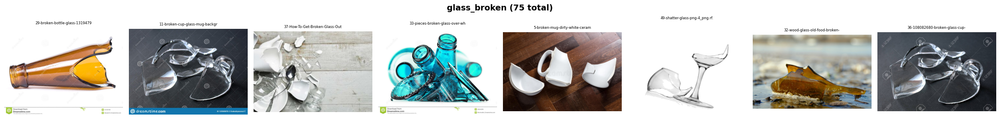

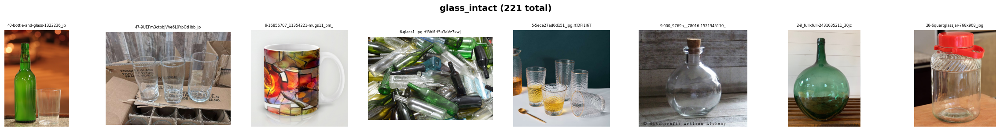


[flagged_non_glass] — no images in this category

[error] — no images in this category


In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 4 FIXED: Visual review with correct category names
# ═══════════════════════════════════════════════════════════

'''import os, random
from PIL import Image
import matplotlib.pyplot as plt

IMAGE_FOLDER = IMAGE_FOLDER if 'IMAGE_FOLDER' in dir() and IMAGE_FOLDER else "/content/glass_images/train/Glass"

by_cat = {}
for fname, cat in results.items():
    by_cat.setdefault(cat, []).append(fname)

print("Categories found:", list(by_cat.keys()))
for cat, files in by_cat.items():
    print(f"  {cat}: {len(files)} images")

# Updated category names to match Cell 3d output
for cat in ["glass_broken", "glass_intact", "flagged_non_glass", "error"]:
    fnames = by_cat.get(cat, [])
    if not fnames:
        print(f"\n[{cat}] — no images in this category")
        continue

    sample = random.sample(fnames, min(8, len(fnames)))
    n_cols = len(sample)
    fig, axes = plt.subplots(1, n_cols, figsize=(3 * n_cols, 3))
    if n_cols == 1:
        axes = [axes]
    fig.suptitle(f"{cat} ({len(fnames)} total)", fontsize=14, fontweight='bold')
    for ax, fname in zip(axes, sample):
        img = Image.open(os.path.join(IMAGE_FOLDER, fname))
        ax.imshow(img)
        ax.set_title(fname[:30], fontsize=6)
        ax.axis('off')
    plt.tight_layout()
    plt.show()'''

# DO NOT RERUN

In [ ]:
'''NOT NECESSARY TO RUN THIS
# ═══════════════════════════════════════════════════════════
# CELL 5: Manual review widget for unclassified images
# ═══════════════════════════════════════════════════════════
# Click buttons to sort images CLIP couldn't classify.
# Takes ~5-15 min depending on how many are unclassified.

import os, shutil, ipywidgets as widgets
from IPython.display import display

IMAGE_FOLDER = IMAGE_FOLDER if 'IMAGE_FOLDER' in dir() and IMAGE_FOLDER else "/content/glass_images/train/Glass"

REBUILD      = "/content/drive/MyDrive/WASTE_AI_REBUILD"
BROKEN_DEST  = os.path.join(REBUILD, "datasets/raw/new_hazardous_additions")
EYEWEAR_DEST = os.path.join(REBUILD, "datasets/raw/new_glasses_nonhazardous")
SKIP_DEST    = os.path.join(REBUILD, "datasets/raw/glasses_unclassified")

to_review = [f for f, c in results.items()
             if c in ("unclassified", "keyword_unclassified", "error")]
print(f"Images to manually review: {len(to_review)}")

if len(to_review) > 0:
    state = {"idx": 0, "glass": 0, "eyewear": 0, "skip": 0}

    img_widget = widgets.Image(width=350, height=350)
    info_label = widgets.Label()

    glass_btn = widgets.Button(
        description="🔴 GLASS → Hazardous",
        button_style='danger',
        layout=widgets.Layout(width='250px', height='50px'))
    eyewear_btn = widgets.Button(
        description="🟢 EYEWEAR → Non-Haz",
        button_style='success',
        layout=widgets.Layout(width='250px', height='50px'))
    skip_btn = widgets.Button(
        description="⏭ SKIP (unclear)",
        layout=widgets.Layout(width='200px', height='50px'))

    def show_img():
        if state["idx"] >= len(to_review):
            img_widget.value = b''
            info_label.value = (f"✅ DONE! Glass→Haz: {state['glass']} | "
                               f"Eyewear→NonHaz: {state['eyewear']} | "
                               f"Skipped: {state['skip']}")
            return
        f = to_review[state["idx"]]
        img_widget.value = open(os.path.join(IMAGE_FOLDER, f), 'rb').read()
        info_label.value = (f"[{state['idx']+1}/{len(to_review)}] {f}  |  "
                           f"Glass: {state['glass']}  Eyewear: {state['eyewear']}  "
                           f"Skip: {state['skip']}")

    def on_glass(b):
        f = to_review[state["idx"]]
        shutil.copy2(os.path.join(IMAGE_FOLDER, f),
                     os.path.join(BROKEN_DEST, f"glass_{f}"))
        results[f] = "glass_hazardous_manual"
        state["glass"] += 1
        state["idx"] += 1
        show_img()

    def on_eyewear(b):
        f = to_review[state["idx"]]
        shutil.copy2(os.path.join(IMAGE_FOLDER, f),
                     os.path.join(EYEWEAR_DEST, f"eyewear_{f}"))
        results[f] = "eyewear_manual"
        state["eyewear"] += 1
        state["idx"] += 1
        show_img()

    def on_skip(b):
        f = to_review[state["idx"]]
        shutil.copy2(os.path.join(IMAGE_FOLDER, f),
                     os.path.join(SKIP_DEST, f))
        results[f] = "skipped_manual"
        state["skip"] += 1
        state["idx"] += 1
        show_img()

    glass_btn.on_click(on_glass)
    eyewear_btn.on_click(on_eyewear)
    skip_btn.on_click(on_skip)

    display(widgets.VBox([
        info_label, img_widget,
        widgets.HBox([glass_btn, eyewear_btn, skip_btn]),
    ]))
    show_img()
else:
    print("✅ No unclassified images — all sorted by CLIP + keywords!")'''

'NOT NECESSARY TO RUN THIS\n# ═══════════════════════════════════════════════════════════\n# CELL 5: Manual review widget for unclassified images\n# ═══════════════════════════════════════════════════════════\n# Click buttons to sort images CLIP couldn\'t classify.\n# Takes ~5-15 min depending on how many are unclassified.\n\nimport os, shutil, ipywidgets as widgets\nfrom IPython.display import display\n\nIMAGE_FOLDER = IMAGE_FOLDER if \'IMAGE_FOLDER\' in dir() and IMAGE_FOLDER else "/content/glass_images/train/Glass"\n\nREBUILD      = "/content/drive/MyDrive/WASTE_AI_REBUILD"\nBROKEN_DEST  = os.path.join(REBUILD, "datasets/raw/new_hazardous_additions")\nEYEWEAR_DEST = os.path.join(REBUILD, "datasets/raw/new_glasses_nonhazardous")\nSKIP_DEST    = os.path.join(REBUILD, "datasets/raw/glasses_unclassified")\n\nto_review = [f for f, c in results.items()\n             if c in ("unclassified", "keyword_unclassified", "error")]\nprint(f"Images to manually review: {len(to_review)}")\n\nif len(

# DO NOT RERUN

In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL 6 FIXED: Copy classified images to proper destinations
# ═══════════════════════════════════════════════════════════
# glass_broken + glass_intact → new_hazardous_additions AND final/hazardous
# flagged_non_glass            → skip (none in this case)

'''import os, shutil, uuid
from collections import Counter

IMAGE_FOLDER = IMAGE_FOLDER if 'IMAGE_FOLDER' in dir() and IMAGE_FOLDER else "/content/glass_images/train/Glass"
REBUILD = "/content/drive/MyDrive/WASTE_AI_REBUILD"

HAZ_SRC   = os.path.join(REBUILD, "datasets/raw/new_hazardous_additions")
FINAL_HAZ = os.path.join(REBUILD, "datasets/final/hazardous")

for d in [HAZ_SRC, FINAL_HAZ]:
    os.makedirs(d, exist_ok=True)

# ── Step 1: Copy from zip folder → new_hazardous_additions (raw staging) ──
hazardous_copied = 0
skipped = 0

for fname, cat in results.items():
    src = os.path.join(IMAGE_FOLDER, fname)

    if cat in ("glass_broken", "glass_intact"):
        # All glass → hazardous (team decision)
        dst_name = f"glass_{fname}" if not fname.startswith("glass_") else fname
        dst = os.path.join(HAZ_SRC, dst_name)
        if not os.path.exists(dst):
            shutil.copy2(src, dst)
            hazardous_copied += 1
        else:
            skipped += 1

    elif cat == "flagged_non_glass":
        # Would need human review — but there are 0 of these
        pass

    elif cat == "error":
        pass

print(f"✅ Glass images → new_hazardous_additions: {hazardous_copied}")
if skipped:
    print(f"   (skipped {skipped} already existing)")

# ── Step 2: Copy from raw staging → final/hazardous/ ──
# Only copy the NEW files we just added (prefixed with "glass_")
final_haz_copied = 0
final_haz_skipped = 0

# Get list of files we just copied (to avoid re-copying old ones)
new_files = set()
for fname, cat in results.items():
    if cat in ("glass_broken", "glass_intact"):
        dst_name = f"glass_{fname}" if not fname.startswith("glass_") else fname
        new_files.add(dst_name)

for f in os.listdir(HAZ_SRC):
    if not f.lower().endswith(('.jpg', '.jpeg', '.png')):
        continue
    src = os.path.join(HAZ_SRC, f)
    new_name = f"{uuid.uuid4().hex[:8]}_{f}"
    dst = os.path.join(FINAL_HAZ, new_name)

    # Copy all files from staging (including any old ones)
    shutil.copy2(src, dst)
    final_haz_copied += 1

print(f"\n✅ Total images → final/hazardous: {final_haz_copied}")

# ── Step 3: Class distribution check ──
print("\n" + "=" * 50)
print("FINAL DATASET DISTRIBUTION")
print("=" * 50)
total = 0
for cls in ["dry", "wet", "hazardous", "non_hazardous"]:
    cls_path = os.path.join(REBUILD, "datasets/final", cls)
    if os.path.exists(cls_path):
        n = len([f for f in os.listdir(cls_path)
                 if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
    else:
        n = 0
    print(f"  {cls:20}: {n:,}")
    total += n
print("=" * 50)
print(f"  {'TOTAL':20}: {total:,}")'''

✅ Glass images → new_hazardous_additions: 296

✅ Total images → final/hazardous: 3036

FINAL DATASET DISTRIBUTION
  dry                 : 3,679
  wet                 : 6,061
  hazardous           : 9,024
  non_hazardous       : 5,391
  TOTAL               : 24,155


# CONTINUED

CELL 0 — Verify Everything Is In Place

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
REBUILD = "/content/drive/MyDrive/WASTE_AI_REBUILD"
os.chdir(REBUILD)

# Check final/ distribution
print("FINAL/ DISTRIBUTION:")
for cls in ["dry", "wet", "hazardous", "non_hazardous"]:
    cls_path = os.path.join(REBUILD, "datasets/final", cls)
    n = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg','.jpeg','.png'))]) if os.path.exists(cls_path) else 0
    print(f"  {cls:20}: {n:,}")

# Check glass in new_hazardous_additions
haz_path = os.path.join(REBUILD, "datasets/raw/new_hazardous_additions")
glass_files = [f for f in os.listdir(haz_path) if f.startswith("glass_")] if os.path.exists(haz_path) else []
print(f"\nGlass images in new_hazardous_additions: {len(glass_files)}")

# Check checkpoints
for ckpt in ["checkpoints/vision_best.pt", "checkpoints/fusion_best.pt"]:
    path = os.path.join(REBUILD, ckpt)
    print(f"  {'✅' if os.path.exists(path) else '❌'} {ckpt}")

# Check old cache
cache_path = os.path.join(REBUILD, "texture_cache.pt")
print(f"\n  {'✅' if os.path.exists(cache_path) else '❌'} texture_cache.pt (will need rebuild)")

Mounted at /content/drive
FINAL/ DISTRIBUTION:
  dry                 : 5,900
  wet                 : 5,900
  hazardous           : 5,900
  non_hazardous       : 5,900

Glass images in new_hazardous_additions: 296
  ✅ checkpoints/vision_best.pt
  ✅ checkpoints/fusion_best.pt

  ✅ texture_cache.pt (will need rebuild)


In [ ]:
# Quick check: does your current pipeline.py use the buggy inline function?
import os
REBUILD = "/content/drive/MyDrive/WASTE_AI_REBUILD"

with open(os.path.join(REBUILD, "pipeline.py"), "r") as f:
    code = f.read()

# Check which function it calls for GLCM
if "extract_texture_features" in code:
    print("❌ OLD pipeline.py — uses buggy extract_texture_features (224/8)")
elif "get_canonical_texture_features" in code:
    print("✅ FIXED pipeline.py — uses canonical (128/64)")
elif "get_texture_feature" in code:
    print("✅ FIXED pipeline.py — uses cache with canonical fallback")
else:
    print("❓ Can't determine — check manually")

# Check continual_learner.py
with open(os.path.join(REBUILD, "continual_learner.py"), "r") as f:
    cl_code = f.read()

if "add_human_correction" in cl_code:
    print("✅ continual_learner.py — has human correction support")
else:
    print("❌ continual_learner.py — missing human correction (needed for Gradio)")

✅ FIXED pipeline.py — uses canonical (128/64)
✅ continual_learner.py — has human correction support


CACHE VERIFICATION

In [ ]:
import os, torch

REBUILD = "/content/drive/MyDrive/WASTE_AI_REBUILD"
CACHE_PATH = os.path.join(REBUILD, "texture_cache.pt")
FINAL_HAZ = os.path.join(REBUILD, "datasets/final/hazardous")

if not os.path.exists(CACHE_PATH):
    print("❌ No cache file exists — must rebuild from scratch")
elif not os.path.exists(FINAL_HAZ):
    print("❌ final/hazardous/ doesn't exist — check with teammate")
else:
    cache = torch.load(CACHE_PATH)
    cached_paths = set(os.path.abspath(k) for k in cache.keys())

    # Check 50 random files from final/hazardous
    all_files = [os.path.join(FINAL_HAZ, f) for f in os.listdir(FINAL_HAZ)
                 if f.lower().endswith(('.jpg','.jpeg','.png'))]

    import random
    sample = random.sample(all_files, min(50, len(all_files)))

    found = sum(1 for p in sample if os.path.abspath(p) in cached_paths)
    missing = len(sample) - found

    print(f"Checked {len(sample)} files from final/hazardous/:")
    print(f"  ✅ Found in cache:     {found}")
    print(f"  ❌ Missing from cache: {missing}")

    if missing > 0:
        print("\n🔴 CACHE IS STALE — must rebuild (~30-40 min)")
        print("   Teammate's rebuild created new filenames not in old cache")
    else:
        print("\n🟢 CACHE IS VALID — skip rebuild, go straight to continual learning!")

Checked 50 files from final/hazardous/:
  ✅ Found in cache:     0
  ❌ Missing from cache: 50

🔴 CACHE IS STALE — must rebuild (~30-40 min)
   Teammate's rebuild created new filenames not in old cache


In [ ]:
import shutil
shutil.copy2(
    "/content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt",
    "/content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_OLD_BACKUP.pt"
)
print("Backup saved")

Backup saved


In [ ]:
import shutil

CACHE_PATH = "/content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt"
BACKUP_PATH = "/content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_OLD_BACKUP.pt"

# Restore backup
shutil.copy2(BACKUP_PATH, CACHE_PATH)
print("✅ Old cache restored from backup")

✅ Old cache restored from backup


In [ ]:
 # ═══════════════════════════════════════════════════════════
# SMART CACHE REBUILD — FIXED REGEX (uuid.hex is 32 chars, not 8)
# ═══════════════════════════════════════════════════════════

import os, torch, numpy as np, cv2, re
from PIL import Image
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
from skimage.feature import graycomatrix, graycoprops

REBUILD      = "/content/drive/MyDrive/WASTE_AI_REBUILD"
DATASET_ROOT = os.path.join(REBUILD, "datasets/final")
CACHE_PATH   = os.path.join(REBUILD, "texture_cache.pt")
RESIZE, LEVELS = 128, 64

def compute_glcm(img_path):
    try:
        img = np.array(Image.open(img_path).convert("L"))
        img = cv2.resize(img, (RESIZE, RESIZE))
        img = (img / (256 // LEVELS)).astype(np.uint8)
        glcm = graycomatrix(img, distances=[1], angles=[0],
                            levels=LEVELS, symmetric=True, normed=True)
        contrast    = graycoprops(glcm, 'contrast')[0, 0]
        homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
        energy      = graycoprops(glcm, 'energy')[0, 0]
        entropy     = -np.sum(glcm * np.log2(glcm + 1e-8))
        variance    = np.var(img) / LEVELS
        feat = torch.tensor([contrast/1000.0, homogeneity, energy,
                             entropy/10.0, variance], dtype=torch.float32)
        return str(img_path), feat
    except:
        return None

def get_suffix(filename):
    """Strip UUID prefix (32 hex chars + underscore) to get the original name."""
    match = re.match(r'^[a-f0-9]{32}_(.+)$', filename)
    return match.group(1) if match else filename

# ── Step 1: Load old cache and build suffix→features lookup ──
if os.path.exists(CACHE_PATH):
    old_cache = torch.load(CACHE_PATH)
    print(f"Old cache entries: {len(old_cache)}")

    # Map filename suffix → features (reuse computation!)
    suffix_map = {}
    for path, feat in old_cache.items():
        fname = os.path.basename(path)
        suffix = get_suffix(fname)
        suffix_map[suffix] = feat

    print(f"Unique filename suffixes in old cache: {len(suffix_map)}")
else:
    old_cache = {}
    suffix_map = {}
    print("No old cache found")

# ── Step 2: Collect all current files ──
all_images = []
for root, _, files in os.walk(DATASET_ROOT):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_images.append(os.path.join(root, f))

print(f"\nCurrent images in final/: {len(all_images)}")

# ── Step 3: Match against old cache ──
new_cache = {}
reused = 0
to_compute = []

for full_path in all_images:
    fname = os.path.basename(full_path)
    suffix = get_suffix(fname)

    if suffix in suffix_map:
        # Reuse old feature — just update the path key
        new_cache[os.path.abspath(full_path)] = suffix_map[suffix]
        reused += 1
    else:
        to_compute.append(full_path)

print(f"✅ Reused from old cache: {reused}")
print(f"🆕 Need to compute:      {len(to_compute)}")

# ── Step 4: Compute only the missing ones ──
if len(to_compute) > 0:
    print(f"\n🚀 Computing GLCM for {len(to_compute)} new images...")

    with Pool(max(2, cpu_count() - 2)) as pool:
        for result in tqdm(pool.imap_unordered(compute_glcm, to_compute),
                           total=len(to_compute)):
            if result:
                new_cache[result[0]] = result[1]

    print(f"✅ Computed {len(to_compute)} new features")

# ── Step 5: Save ──
torch.save(new_cache, CACHE_PATH)
print(f"\n💾 Cache saved: {len(new_cache)} total entries")
print(f"   Reused: {reused} | Computed: {len(new_cache) - reused}")

# ── Verify ──
cached_paths = set(os.path.abspath(k) for k in new_cache.keys())
missing = sum(1 for p in all_images if os.path.abspath(p) not in cached_paths)
print(f"Missing: {missing}")

if missing == 0:
    print("✅ ALL images cached — ready for continual learning!")

Old cache entries: 21119
Unique filename suffixes in old cache: 19662

Current images in final/: 23600
✅ Reused from old cache: 19210
🆕 Need to compute:      4390

🚀 Computing GLCM for 4390 new images...


100%|██████████| 4390/4390 [11:42<00:00,  6.25it/s]


✅ Computed 4390 new features

💾 Cache saved: 23600 total entries
   Reused: 19210 | Computed: 4390
Missing: 0
✅ ALL images cached — ready for continual learning!


NEW FOLDER ADDITIONS

In [ ]:
import zipfile, os

# paths to your zip files – adjust if needed
ZIPS = {
    "scissors": "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/scissors.zip",
    "knives":   "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/knives.zip",
    "ewaste":   "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/ewaste.zip",
}

EXTRACT_ROOT = "/content/new_items/"

for name, zpath in ZIPS.items():
    if not os.path.exists(zpath):
        print(f"❌ Missing {name} zip at {zpath}")
        continue
    dest = os.path.join(EXTRACT_ROOT, name)
    os.makedirs(dest, exist_ok=True)
    with zipfile.ZipFile(zpath, 'r') as zf:
        zf.extractall(dest)
    print(f"✅ Unzipped {name} to {dest}")

✅ Unzipped scissors to /content/new_items/scissors
✅ Unzipped knives to /content/new_items/knives
✅ Unzipped ewaste to /content/new_items/ewaste


CHECKING THEIR FOLDER STRUCTURE SO WE CAN US EONLY WHAT'S NEEDED

In [ ]:
for name in ["scissors", "knives", "ewaste"]:
    folder = os.path.join(EXTRACT_ROOT, name)
    print(f"\n📁 {name.upper()} structure:")
    for root, dirs, files in os.walk(folder):
        num_imgs = len([f for f in files if f.lower().endswith(('.jpg','.jpeg','.png'))])
        if num_imgs > 0 or root == folder:
            indent = "  " * (root.count(os.sep) - folder.count(os.sep))
            print(f"{indent}{os.path.basename(root)}/  ({num_imgs} images)")


📁 SCISSORS structure:
scissors/  (0 images)
  train/  (278 images)
  test/  (30 images)
  valid/  (58 images)

📁 KNIVES structure:
knives/  (0 images)
    train/  (400 images)
    test/  (100 images)

📁 EWASTE structure:
ewaste/  (0 images)
      Television/  (240 images)
      Mouse/  (240 images)
      Player/  (240 images)
      Printer/  (240 images)
      Battery/  (240 images)
      Mobile/  (240 images)
      Microwave/  (240 images)
      PCB/  (240 images)
      Washing Machine/  (240 images)
      Keyboard/  (240 images)
      Television/  (30 images)
      Mouse/  (30 images)
      Player/  (30 images)
      Printer/  (30 images)
      Battery/  (30 images)
      Mobile/  (30 images)
      Microwave/  (30 images)
      PCB/  (30 images)
      Washing Machine/  (30 images)
      Keyboard/  (30 images)
      Television/  (30 images)
      Mouse/  (30 images)
      Player/  (30 images)
      Printer/  (30 images)
      Battery/  (30 images)
      Mobile/  (30 images)
      Mic

PUTTING THEM IN SEPARATE FOLDERS WITHIN THE RAW FOLDER

1.a Creating those folders

In [ ]:
import os, shutil, glob

REBUILD      = "/content/drive/MyDrive/WASTE_AI_REBUILD"
EXTRACT_ROOT = "/content/new_items/"          # where the zips were extracted

# The three raw folders we'll feed into continual learning
RAW = {
    "scissors":  os.path.join(REBUILD, "datasets/raw/new_scissors"),
    "knives":    os.path.join(REBUILD, "datasets/raw/new_knives"),
    "batteries": os.path.join(REBUILD, "datasets/raw/new_batteries"),
}

for path in RAW.values():
    os.makedirs(path, exist_ok=True)

1.b. Actually putting the images into those folders

In [ ]:
def copy_all_images_from_tree(src_root, dest_dir, extensions=('.jpg','.jpeg','.png')):
    """Walk src_root and copy every image file into dest_dir."""
    count = 0
    for root, dirs, files in os.walk(src_root):
        for fname in files:
            if fname.lower().endswith(extensions):
                src = os.path.join(root, fname)
                dst = os.path.join(dest_dir, fname)
                if not os.path.exists(dst):
                    shutil.copy2(src, dst)
                    count += 1
    return count

# Scissors
src_scissors = os.path.join(EXTRACT_ROOT, "scissors")
n = copy_all_images_from_tree(src_scissors, RAW["scissors"])
print(f"✅ Scissors: {n} images → {RAW['scissors']}")

# Knives
src_knives = os.path.join(EXTRACT_ROOT, "knives")
n = copy_all_images_from_tree(src_knives, RAW["knives"])
print(f"✅ Knives: {n} images → {RAW['knives']}")

✅ Scissors: 366 images → /content/drive/MyDrive/WASTE_AI_REBUILD/datasets/raw/new_scissors
✅ Knives: 400 images → /content/drive/MyDrive/WASTE_AI_REBUILD/datasets/raw/new_knives


In [ ]:
src_ewaste = os.path.join(EXTRACT_ROOT, "ewaste")
battery_count = 0

# Walk the whole e‑waste tree; find any folder named exactly "Battery" (case‑sensitive)
for root, dirs, files in os.walk(src_ewaste):
    if os.path.basename(root) == "Battery":
        n = copy_all_images_from_tree(root, RAW["batteries"])
        battery_count += n

print(f"✅ Batteries: {battery_count} images → {RAW['batteries']}")

✅ Batteries: 300 images → /content/drive/MyDrive/WASTE_AI_REBUILD/datasets/raw/new_batteries


VERIFYING WHAT'S IN CHECKPOINTS

In [ ]:
import os

CKPT_DIR = "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints"
for f in ["vision_continual.pt", "fusion_continual.pt", "ewc_state.pt",
          "vision_best.pt", "fusion_best.pt", "texture_cache.pt", "continual_texture_cache.pt"]:
    p = os.path.join(CKPT_DIR, f)
    size = os.path.getsize(p) if os.path.exists(p) else 0
    print(f"{'✅' if size else '❌'} {f:30} ({size:,} bytes)")

✅ vision_continual.pt            (47,033,759 bytes)
✅ fusion_continual.pt            (977,013 bytes)
✅ ewc_state.pt                   (270,889 bytes)
✅ vision_best.pt                 (47,030,819 bytes)
✅ fusion_best.pt                 (976,853 bytes)
❌ texture_cache.pt               (0 bytes)
✅ continual_texture_cache.pt     (328,011 bytes)


In [ ]:
import os

ROOT = "/content/drive/MyDrive/WASTE_AI_REBUILD"
candidates = [
    os.path.join(ROOT, "texture_cache.pt"),
    os.path.join(ROOT, "continual_texture_cache.pt"),
    os.path.join(ROOT, "checkpoints", "texture_cache.pt"),
    os.path.join(ROOT, "checkpoints", "continual_texture_cache.pt"),
]
for c in candidates:
    if os.path.exists(c):
        print(f"✅ {c}  ({os.path.getsize(c):,} bytes)")

✅ /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt  (8,993,737 bytes)
✅ /content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/continual_texture_cache.pt  (328,011 bytes)


CREATING BACKUPS OF CHECKPOINTS

In [ ]:
import shutil, os

SRC = "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints"
DST = "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints_backup_before_new_items"

if not os.path.exists(DST):
    shutil.copytree(SRC, DST)
    print(f"✅ Backup created at {DST}")
else:
    print("Backup folder already exists. Remove it first if you want a fresh backup.")

✅ Backup created at /content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints_backup_before_new_items


In [ ]:
# How many glass_ images in new_hazardous_additions?
!ls /content/drive/MyDrive/WASTE_AI_REBUILD/datasets/raw

garbage_v2		  new_hazardous_additions  organic_dataset
glasses_unclassified	  new_knives		   processed_taco
new_batteries		  new_scissors		   trashnet
new_glasses_nonhazardous  new_wet_additions


In [ ]:
import sys, os
sys.path.insert(0, "/content/drive/MyDrive/WASTE_AI_REBUILD")

# Read the original content of xai_engine.py
with open("/content/drive/MyDrive/WASTE_AI_REBUILD/xai_engine.py", "r") as f:
    content = f.read()

# Apply the fix for GradCAM.generate
# Remove .unsqueeze(0) as the tensor is already 4D from the DataLoader
content = content.replace(
    "x   = x.unsqueeze(0).requires_grad_(True)",
    "x   = x.requires_grad_(True)"
)

# Rewrite the modified content to xai_engine.py
with open("/content/drive/MyDrive/WASTE_AI_REBUILD/xai_engine.py", "w") as f:
    f.write(content)

print("✅ xai_engine.py modified successfully to fix the unsqueeze(0) issue.")

# Reload the module to apply changes immediately
import xai_engine
import importlib
importlib.reload(xai_engine)
print("✅ xai_engine module reloaded.")

✅ xai_engine.py modified successfully to fix the unsqueeze(0) issue.
✅ xai_engine module reloaded.


In [ ]:
# Run this quick check:
import sys
sys.path.insert(0, "/content/drive/MyDrive/WASTE_AI_REBUILD")
from vision_model import WasteVisionModel

vision = WasteVisionModel()
print("\nVision model structure:")
for name, module in vision.named_modules():
    if "backbone" in name or name == "":
        print(f"  {name or 'root'}: {module.__class__.__name__}")

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 184MB/s]



Vision model structure:
  root: WasteVisionModel
  backbone: Sequential
  backbone.0: Sequential
  backbone.0.0: Conv2dNormActivation
  backbone.0.0.0: Conv2d
  backbone.0.0.1: BatchNorm2d
  backbone.0.0.2: SiLU
  backbone.0.1: Sequential
  backbone.0.1.0: MBConv
  backbone.0.1.0.block: Sequential
  backbone.0.1.0.block.0: Conv2dNormActivation
  backbone.0.1.0.block.0.0: Conv2d
  backbone.0.1.0.block.0.1: BatchNorm2d
  backbone.0.1.0.block.0.2: SiLU
  backbone.0.1.0.block.1: SqueezeExcitation
  backbone.0.1.0.block.1.avgpool: AdaptiveAvgPool2d
  backbone.0.1.0.block.1.fc1: Conv2d
  backbone.0.1.0.block.1.fc2: Conv2d
  backbone.0.1.0.block.1.activation: SiLU
  backbone.0.1.0.block.1.scale_activation: Sigmoid
  backbone.0.1.0.block.2: Conv2dNormActivation
  backbone.0.1.0.block.2.0: Conv2d
  backbone.0.1.0.block.2.1: BatchNorm2d
  backbone.0.1.0.stochastic_depth: StochasticDepth
  backbone.0.1.1: MBConv
  backbone.0.1.1.block: Sequential
  backbone.0.1.1.block.0: Conv2dNormActivation
  

NEW CONTINUAL LEARNING ON OTHER IMAGES

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# CONTINUAL LEARNING — New Hazardous Items (glass_, scissors, knives, batteries)
# WITH: Balanced Replay | XAI Integration | Human Feedback Loop
# ═══════════════════════════════════════════════════════════════════════════════

import sys, os, torch, numpy as np, cv2, json, random
from PIL import Image as PILImage
from skimage.feature import graycomatrix, graycoprops
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
from torch.utils.data import DataLoader, Dataset
from collections import defaultdict, Counter
from datetime import datetime
import torch.nn.functional as F

sys.path.insert(0, "/content/drive/MyDrive/WASTE_AI_REBUILD")
os.chdir("/content/drive/MyDrive/WASTE_AI_REBUILD")

from continual_learner import ContinualLearner
from dataset import load_texture_cache, get_transforms
from vision_model import WasteVisionModel
from multimodal_fusion import MultimodalWasteClassifier
from xai_engine import XAIEngine
from uncertainty_engine import UncertaintyEngine, DecisionTier

# ═══════════════════════════════════════════════════════════════════════════════
# CONFIGURATION
# ═══════════════════════════════════════════════════════════════════════════════

REBUILD    = "/content/drive/MyDrive/WASTE_AI_REBUILD"
DEVICE     = "cuda" if torch.cuda.is_available() else "cpu"
LABELS     = ["dry", "wet", "hazardous", "non_hazardous"]
LABEL_MAP  = {"dry": 0, "wet": 1, "hazardous": 2, "non_hazardous": 3}
RESIZE, LEVELS = 128, 64

# ── Paths ──
CACHE_PATH     = os.path.join(REBUILD, "texture_cache.pt")
NEW_CACHE_PATH = os.path.join(REBUILD, "texture_cache_new_haz.pt")
CKPT_DIR       = os.path.join(REBUILD, "checkpoints")
FEEDBACK_PATH  = os.path.join(REBUILD, "human_feedback.json")
TRAIN_LOG_PATH = os.path.join(REBUILD, "continual_training_log.json")

# ── New hazardous sources with FILTER FUNCTIONS ──
NEW_HAZARDOUS_SOURCES = {
    os.path.join(REBUILD, "datasets/raw/new_hazardous_additions"): (
        lambda f: f.lower().startswith("glass_"),  # ONLY glass_ prefix!
        "glass (new)"
    ),
    os.path.join(REBUILD, "datasets/raw/new_scissors"): (
        lambda f: f.lower().endswith(('.jpg', '.jpeg', '.png')),
        "scissors"
    ),
    os.path.join(REBUILD, "datasets/raw/new_knives"): (
        lambda f: f.lower().endswith(('.jpg', '.jpeg', '.png')),
        "knives"
    ),
    os.path.join(REBUILD, "datasets/raw/new_batteries"): (
        lambda f: f.lower().endswith(('.jpg', '.jpeg', '.png')),
        "batteries"
    ),
}

# ── Replay sources (from final/ - OLD training data) ──
REPLAY_SOURCES = {
    "dry": os.path.join(REBUILD, "datasets/final/dry"),
    "wet": os.path.join(REBUILD, "datasets/final/wet"),
    "non_hazardous": os.path.join(REBUILD, "datasets/final/non_hazardous"),
}

# ═══════════════════════════════════════════════════════════════════════════════
# 1. LOAD MAIN TEXTURE CACHE (for final/ paths)
# ═══════════════════════════════════════════════════════════════════════════════

print("📦 Loading main texture cache...")
load_texture_cache(CACHE_PATH)
main_cache = torch.load(CACHE_PATH, map_location="cpu")
main_cached_paths = set(os.path.abspath(k) for k in main_cache.keys())
print(f"   ✅ Main cache: {len(main_cache)} entries")

# ═══════════════════════════════════════════════════════════════════════════════
# 2. COLLECT NEW HAZARDOUS IMAGES (with proper filtering!)
# ═══════════════════════════════════════════════════════════════════════════════

print("\n🔍 Scanning for NEW hazardous images...")
all_new_haz_paths = []
source_breakdown = {}

for folder_path, (filter_func, description) in NEW_HAZARDOUS_SOURCES.items():
    if not os.path.exists(folder_path):
        print(f"   ❌ Missing folder: {folder_path}")
        continue

    folder_images = []
    for fname in sorted(os.listdir(folder_path)):
        if filter_func(fname):
            folder_images.append(os.path.join(folder_path, fname))

    source_breakdown[description] = len(folder_images)
    all_new_haz_paths.extend(folder_images)
    print(f"   ✅ {description}: {len(folder_images)} images")

print(f"\n📸 Total NEW hazardous images: {len(all_new_haz_paths)}")

if len(all_new_haz_paths) == 0:
    raise ValueError("❌ No new hazardous images found!")

# ═══════════════════════════════════════════════════════════════════════════════
# 3. COMPUTE GLCM CACHE FOR NEW RAW IMAGES (separate cache)
# ═══════════════════════════════════════════════════════════════════════════════

def compute_glcm(img_path):
    try:
        img = np.array(PILImage.open(img_path).convert("L"))
        img = cv2.resize(img, (RESIZE, RESIZE))
        img = (img / (256 // LEVELS)).astype(np.uint8)
        glcm = graycomatrix(img, distances=[1], angles=[0],
                            levels=LEVELS, symmetric=True, normed=True)
        contrast    = graycoprops(glcm, 'contrast')[0, 0]
        homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
        energy      = graycoprops(glcm, 'energy')[0, 0]
        entropy     = -np.sum(glcm * np.log2(glcm + 1e-8))
        variance    = np.var(img) / LEVELS
        feat = torch.tensor([contrast/1000.0, homogeneity, energy,
                             entropy/10.0, variance], dtype=torch.float32)
        return str(img_path), feat
    except:
        return None

if os.path.exists(NEW_CACHE_PATH):
    print("\n📦 Loading new hazardous cache...")
    new_cache = torch.load(NEW_CACHE_PATH, map_location="cpu")
else:
    new_cache = {}

new_cached_paths = set(os.path.abspath(k) for k in new_cache.keys())
to_compute = [p for p in all_new_haz_paths if os.path.abspath(p) not in new_cached_paths]

print(f"🆕 New images to cache: {len(to_compute)} / {len(all_new_haz_paths)}")

if to_compute:
    with Pool(max(2, cpu_count() - 2)) as pool:
        results = list(tqdm(pool.imap_unordered(compute_glcm, to_compute),
                            total=len(to_compute), desc="Computing GLCM"))

    for result in results:
        if result:
            new_cache[result[0]] = result[1]

    torch.save(new_cache, NEW_CACHE_PATH)
    print(f"💾 New cache saved ({len(new_cache)} entries)")

# ═══════════════════════════════════════════════════════════════════════════════
# 4. BUILD NEW HAZARDOUS SAMPLES (label=2=hazardous)
# ═══════════════════════════════════════════════════════════════════════════════

print("\n🧠 Building new hazardous samples...")
new_haz_samples = []

for p in all_new_haz_paths:
    key = os.path.abspath(p)
    if key in set(os.path.abspath(k) for k in new_cache.keys()):
        new_haz_samples.append((p, LABEL_MAP["hazardous"]))

print(f"   ✅ New hazardous samples: {len(new_haz_samples)}")

# ═══════════════════════════════════════════════════════════════════════════════
# 5. BUILD BALANCED REPLAY SAMPLES (same count as new hazardous)
# ═══════════════════════════════════════════════════════════════════════════════

print("\n⚖️ Building balanced replay dataset...")
REPLAY_PER_CLASS = len(new_haz_samples)
replay_samples = []

for cls_name, folder_path in REPLAY_SOURCES.items():
    if not os.path.exists(folder_path):
        print(f"   ❌ Missing replay folder: {folder_path}")
        continue

    all_imgs = [os.path.join(folder_path, f) for f in os.listdir(folder_path)
                if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    cached_imgs = [p for p in all_imgs if os.path.abspath(p) in main_cached_paths]

    if len(cached_imgs) == 0:
        print(f"   ❌ {cls_name}: no cached images found!")
        continue

    selected = random.sample(cached_imgs, min(REPLAY_PER_CLASS, len(cached_imgs)))

    for p in selected:
        replay_samples.append((p, LABEL_MAP[cls_name]))

    print(f"   ✅ {cls_name}: {len(selected)} replay samples")

print(f"   📊 Total replay: {len(replay_samples)}")

# ═══════════════════════════════════════════════════════════════════════════════
# 6. COMBINE INTO BALANCED DATASET
# ═══════════════════════════════════════════════════════════════════════════════

print("\n🔄 Combining datasets...")
all_samples = new_haz_samples + replay_samples
random.shuffle(all_samples)

class_dist = Counter(label for _, label in all_samples)
print(f"   📊 Final distribution:")
for cls_name, cls_idx in LABEL_MAP.items():
    count = class_dist.get(cls_idx, 0)
    marker = "🆕" if cls_name == "hazardous" else "♻️"
    print(f"      {marker} {cls_name}: {count}")


class UnifiedDataset(Dataset):
    def __init__(self, samples, new_cache, main_cache):
        self.samples = samples
        self.transform = get_transforms("train")
        self.unified_cache = {}
        for k, v in new_cache.items():
            self.unified_cache[os.path.abspath(k)] = v
        for k, v in main_cache.items():
            self.unified_cache[os.path.abspath(k)] = v

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = self.transform(PILImage.open(path).convert("RGB"))
        key = os.path.abspath(path)
        if key not in self.unified_cache:
            raise KeyError(f"Texture not cached: {path}")
        meta = self.unified_cache[key]
        return img, label, meta


loader = DataLoader(
    UnifiedDataset(all_samples, new_cache, main_cache),
    batch_size=16, shuffle=True, num_workers=2, pin_memory=True
)

# ═══════════════════════════════════════════════════════════════════════════════
# 7. LOAD MODEL & EWC STATE
# ═══════════════════════════════════════════════════════════════════════════════

print("\n🧠 Loading models...")
vision = WasteVisionModel().to(DEVICE)
fusion = MultimodalWasteClassifier(img_feat_dim=vision.feat_dim).to(DEVICE)

vision_path = os.path.join(CKPT_DIR, "vision_continual.pt")
fusion_path = os.path.join(CKPT_DIR, "fusion_continual.pt")
ewc_path    = os.path.join(CKPT_DIR, "ewc_state.pt")

vision.load_state_dict(torch.load(vision_path, map_location=DEVICE))
fusion.load_state_dict(torch.load(fusion_path, map_location=DEVICE))

# ═══════════════════════════════════════════════════════════════════════════════
# 8. FREEZE BACKBONE
# ═══════════════════════════════════════════════════════════════════════════════

for param in vision.parameters():
    param.requires_grad = False
vision.eval()
print("   ❄️  Vision backbone: FROZEN")

# ═══════════════════════════════════════════════════════════════════════════════
# 9. INITIALIZE CONTINUAL LEARNER WITH EWC
# ═══════════════════════════════════════════════════════════════════════════════

cl = ContinualLearner(
    model=fusion, vision=vision, device=DEVICE,
    ewc_lambda=25.0, replay_ratio=2.0
)

# ✅ FIXED: Safe loading with .get() and fallback
if os.path.exists(ewc_path):
    state = torch.load(ewc_path, map_location=DEVICE)
    cl.fisher = state.get("fisher", None)
    cl.prev_params = state.get("prev_params", None)

    if cl.fisher is not None and cl.prev_params is not None:
        print("   ✅ EWC Fisher & prev_params restored")
    else:
        print("   ⚠️ EWC state exists but missing fisher/prev_params — EWC disabled")
else:
    print("   ⚠️ No ewc_state.pt found — running WITHOUT EWC penalty")

# ═══════════════════════════════════════════════════════════════════════════════
# 10. INITIALIZE XAI & UNCERTAINTY ENGINES
# ═══════════════════════════════════════════════════════════════════════════════

print("\n🔍 Initializing XAI & Uncertainty engines...")

# ✅ FIXED: Point to VISION (has backbone), not fusion
try:
    xai_engine = XAIEngine(vision, backbone="efficientnet")
    print("   ✅ XAI Engine initialized")
    if xai_engine.gradcam:
        print("   ✅ GradCAM available")
    else:
        print("   ⚠️ GradCAM unavailable (will use verbal only)")
except Exception as e:
    print(f"   ⚠️ XAI Engine init failed: {e}")
    xai_engine = None

uncertainty_engine = UncertaintyEngine()
print("   ✅ Uncertainty Engine initialized")

# ═══════════════════════════════════════════════════════════════════════════════
# 11. HUMAN FEEDBACK SYSTEM
# ═══════════════════════════════════════════════════════════════════════════════

class HumanFeedbackSystem:
    def __init__(self, feedback_path):
        self.feedback_path = feedback_path
        self.corrections = []
        self._load()

    def _load(self):
        if os.path.exists(self.feedback_path):
            try:
                with open(self.feedback_path, 'r') as f:
                    self.corrections = json.load(f)
                print(f"   📋 Loaded {len(self.corrections)} existing corrections")
            except:
                self.corrections = []

    def add_correction(self, image_path, predicted_label, correct_label,
                       confidence, reason="manual_correction", xai_explanation=None):
        correction = {
            "timestamp": datetime.now().isoformat(),
            "image_path": str(image_path),
            "predicted": predicted_label,
            "correct": correct_label,
            "confidence": round(confidence, 4),
            "reason": reason,
            "xai_explanation": xai_explanation
        }
        self.corrections.append(correction)
        self._save()
        return correction

    def _save(self):
        with open(self.feedback_path, 'w') as f:
            json.dump(self.corrections, f, indent=2)

    def get_correction_samples(self, max_samples=50):
        valid = [c for c in self.corrections
                 if c.get("reason") in ["manual_correction", "low_confidence_review"]]
        return valid[:max_samples]

    def get_stats(self):
        if not self.corrections:
            return {"total": 0}
        return {
            "total": len(self.corrections),
            "by_predicted": dict(Counter(c["predicted"] for c in self.corrections)),
            "by_correct": dict(Counter(c["correct"] for c in self.corrections)),
            "avg_confidence": round(np.mean([c["confidence"] for c in self.corrections]), 3),
        }


feedback_system = HumanFeedbackSystem(FEEDBACK_PATH)

# ═══════════════════════════════════════════════════════════════════════════════
# 12. TRAINING LOG SYSTEM
# ═══════════════════════════════════════════════════════════════════════════════

class TrainingLogger:
    def __init__(self, log_path):
        self.log_path = log_path
        self.sessions = []
        self._load()
        self.current_session = {
            "timestamp": datetime.now().isoformat(),
            "config": {
                "new_hazardous_count": len(new_haz_samples),
                "source_breakdown": source_breakdown,
                "replay_per_class": REPLAY_PER_CLASS,
                "total_samples": len(all_samples),
                "class_distribution": dict(class_dist),
                "ewc_lambda": 25.0,
                "epochs": 8,
            },
            "epochs": [],
            "xai_samples": [],
            "misclassified": [],
        }

    def _load(self):
        if os.path.exists(self.log_path):
            try:
                with open(self.log_path, 'r') as f:
                    self.sessions = json.load(f)
            except:
                self.sessions = []

    def log_epoch(self, epoch, loss, accuracy):
        self.current_session["epochs"].append({
            "epoch": epoch, "loss": round(loss, 4), "accuracy": round(accuracy, 4)
        })

    def log_xai_sample(self, image_path, explanation, is_correct):
        verbal = explanation.get("verbal", {})
        self.current_session["xai_samples"].append({
            "image_path": str(image_path),
            "classification": verbal.get("classification"),
            "action": verbal.get("action"),
            "has_heatmap": explanation.get("heatmap") is not None,
            "correct": is_correct
        })

    def log_misclassified(self, image_path, predicted, actual, explanation):
        self.current_session["misclassified"].append({
            "image_path": str(image_path),
            "predicted": predicted,
            "actual": actual,
            "explanation": explanation.get("verbal", {})
        })

    def finalize(self, final_metrics):
        self.current_session["final_metrics"] = final_metrics
        self.sessions.append(self.current_session)
        self._save()

    def _save(self):
        with open(self.log_path, 'w') as f:
            json.dump(self.sessions, f, indent=2)


logger = TrainingLogger(TRAIN_LOG_PATH)

# ═══════════════════════════════════════════════════════════════════════════════
# 13. EVALUATION FUNCTION
# ═══════════════════════════════════════════════════════════════════════════════

def evaluate_with_xai(model, vision_backbone, dataloader, device,
                       xai_eng, unc_eng, num_xai_batches=3):
    model.eval()
    vision_backbone.eval()

    all_preds, all_labels = [], []
    total_loss = 0
    xai_explanations = []
    misclassified_list = []

    criterion = torch.nn.CrossEntropyLoss()

    with torch.no_grad():
        for batch_idx, (imgs, labels, meta) in enumerate(dataloader):
            imgs = imgs.to(device)
            labels = labels.to(device)
            meta = meta.to(device)

            feats = vision_backbone.get_features(imgs)
            out = model(feats, meta)

            loss = criterion(out["logits"], labels)
            total_loss += loss.item()

            preds = out["logits"].argmax(1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

            # XAI for early batches
            if xai_eng and batch_idx < num_xai_batches:
                for i in range(min(2, imgs.size(0))):
                    conf = F.softmax(out["logits"], dim=1)[i].max().item()
                    pred_idx = preds[i].item()
                    pred_label = LABELS[pred_idx]
                    true_label = LABELS[labels[i].item()]
                    is_correct = (pred_idx == labels[i].item())

                    class_probs = {LABELS[j]: F.softmax(out["logits"], dim=1)[i, j].item()
                                   for j in range(4)}

                    # Build metadata dict
                    meta_dict = {
                        "texture_contrast": meta[i, 0].item() if meta.dim() > 1 else 0,
                        "texture_homogeneity": meta[i, 1].item() if meta.dim() > 1 else 0,
                        "texture_entropy": meta[i, 2].item() if meta.dim() > 1 else 0,
                        "surface_variance": meta[i, 4].item() if meta.dim() > 1 and meta.size(1) > 4 else 0,
                    }

                    try:
                        explanation = xai_eng.explain(
                            image_tensor=imgs[i].cpu(),
                            label=pred_label,
                            class_idx=pred_idx,
                            confidence=conf,
                            class_probs=class_probs,
                            entropy=0.0,  # Simplified for training eval
                            epistemic=0.0,
                            metadata=meta_dict,
                            action="AUTO_SORT"
                        )
                        explanation["true_label"] = true_label
                        explanation["is_correct"] = is_correct
                        xai_explanations.append(explanation)

                        if not is_correct:
                            misclassified_list.append({
                                "pred": pred_label,
                                "true": true_label,
                                "conf": conf,
                                "explanation": explanation
                            })
                    except Exception as e:
                        pass

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    accuracy = (all_preds == all_labels).mean()
    avg_loss = total_loss / len(dataloader)

    per_class_acc = {}
    for cls_idx, cls_name in enumerate(LABELS):
        mask = all_labels == cls_idx
        if mask.sum() > 0:
            per_class_acc[cls_name] = (all_preds[mask] == all_labels[mask]).mean()

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "per_class_accuracy": per_class_acc,
        "xai_explanations": xai_explanations,
        "misclassified": misclassified_list
    }

# ═══════════════════════════════════════════════════════════════════════════════
# 14. RUN CONTINUAL TRAINING
# ═══════════════════════════════════════════════════════════════════════════════

NUM_EPOCHS = 8

print("\n" + "="*70)
print("🔥 STARTING CONTINUAL LEARNING")
print("="*70)
print(f"   ❄️  Backbone: FROZEN")
print(f"   🔥 Classifier head: TRAINING")
print(f"   🛡️  EWC Lambda: 25.0")
print(f"   🆕 New hazardous: {len(new_haz_samples)}")
print(f"   ♻️  Replay: {len(replay_samples)}")
print(f"   📊 Total: {len(all_samples)}")
print("="*70)

# Note: ContinualLearner already handles freezing internally
# It only trains model.classifier.parameters()

for epoch in range(NUM_EPOCHS):
    print(f"\n{'─'*50}")
    print(f"🚀 EPOCH {epoch+1}/{NUM_EPOCHS}")
    print(f"{'─'*50}")

    # ✅ This signature IS correct for your continual_learner.py
    cl.update(loader, supervised=True, num_epochs=1)

    print("   📊 Evaluating...")
    metrics = evaluate_with_xai(fusion, vision, loader, DEVICE,
                                 xai_engine, uncertainty_engine)

    print(f"   📈 Loss: {metrics['loss']:.4f} | Accuracy: {metrics['accuracy']*100:.1f}%")

    for cls_name, acc in metrics['per_class_accuracy'].items():
        marker = "🆕" if cls_name == "hazardous" else "  "
        print(f"      {marker} {cls_name}: {acc*100:.1f}%")

    for expl in metrics['xai_explanations']:
        logger.log_xai_sample("training_batch", expl, expl.get('is_correct', True))

    logger.log_epoch(epoch, metrics['loss'], metrics['accuracy'])

# ═══════════════════════════════════════════════════════════════════════════════
# 15. FINAL EVALUATION ON NEW HAZARDOUS ONLY
# ═══════════════════════════════════════════════════════════════════════════════

print("\n" + "="*70)
print("📊 FINAL EVALUATION: NEW HAZARDOUS ONLY")
print("="*70)

new_haz_loader = DataLoader(
    UnifiedDataset(new_haz_samples, new_cache, main_cache),
    batch_size=16, shuffle=False
)

final_metrics = evaluate_with_xai(
    fusion, vision, new_haz_loader, DEVICE,
    xai_engine, uncertainty_engine, num_xai_batches=10
)

print(f"\n   🎯 New Hazardous Accuracy: {final_metrics['accuracy']*100:.1f}%")

misclassified = final_metrics.get('misclassified', [])
if misclassified:
    print(f"\n   ⚠️  {len(misclassified)} MISCLASSIFIED:")
    for i, m in enumerate(misclassified[:5]):
        print(f"      [{i+1}] Pred: {m['pred']} | True: {m['true']} | Conf: {m['conf']:.2f}")

# ═══════════════════════════════════════════════════════════════════════════════
# 16. SAVE EVERYTHING
# ═══════════════════════════════════════════════════════════════════════════════

print("\n💾 Saving...")

torch.save(vision.state_dict(), vision_path)
torch.save(fusion.state_dict(), fusion_path)

ewc_state = {
    "fusion_state": fusion.state_dict(),
    "fisher": cl.fisher,
    "prev_params": cl.prev_params,
    "buffer_size": len(cl.buffer.buffer),
    "corrections": len(cl.correction_log),
    "timestamp": datetime.now().isoformat(),
    "new_haz_trained": source_breakdown,
}
torch.save(ewc_state, ewc_path)

logger.finalize({
    "new_haz_accuracy": round(final_metrics['accuracy'], 4),
    "misclassified_count": len(misclassified),
    "feedback_stats": feedback_system.get_stats(),
})

# ═══════════════════════════════════════════════════════════════════════════════
# 17. SUMMARY
# ═══════════════════════════════════════════════════════════════════════════════

print("\n" + "="*70)
print("✅ CONTINUAL LEARNING COMPLETE!")
print("="*70)
print(f"""
   📊 Results:
      • New Hazardous Accuracy: {final_metrics['accuracy']*100:.1f}%
      • Misclassified: {len(misclassified)}

   🆕 New Images:
{chr(10).join(f'      • {k}: {v}' for k, v in source_breakdown.items())}

   💾 Saved:
      • {vision_path}
      • {fusion_path}
      • {ewc_path}
      • {NEW_CACHE_PATH}
      • {TRAIN_LOG_PATH}
      • {FEEDBACK_PATH}
""")

print("👤 Human Feedback Usage:")
print("   feedback_system.add_correction(image_path, predicted, correct, confidence)")
print(f"   Current stats: {feedback_system.get_stats()}")

📦 Loading main texture cache...
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt...
Loaded 23600 cached features
   ✅ Main cache: 23600 entries

🔍 Scanning for NEW hazardous images...
   ✅ glass (new): 296 images
   ✅ scissors: 366 images
   ✅ knives: 400 images
   ✅ batteries: 300 images

📸 Total NEW hazardous images: 1362
🆕 New images to cache: 1362 / 1362


Computing GLCM: 100%|██████████| 1362/1362 [04:32<00:00,  4.99it/s]


💾 New cache saved (1362 entries)

🧠 Building new hazardous samples...
   ✅ New hazardous samples: 1362

⚖️ Building balanced replay dataset...
   ✅ dry: 1362 replay samples
   ✅ wet: 1362 replay samples
   ✅ non_hazardous: 1362 replay samples
   📊 Total replay: 4086

🔄 Combining datasets...
   📊 Final distribution:
      ♻️ dry: 1362
      ♻️ wet: 1362
      🆕 hazardous: 1362
      ♻️ non_hazardous: 1362

🧠 Loading models...
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 208MB/s]


   ❄️  Vision backbone: FROZEN
   ✅ EWC Fisher & prev_params restored

🔍 Initializing XAI & Uncertainty engines...
   ✅ XAI Engine initialized
   ✅ GradCAM available
   ✅ Uncertainty Engine initialized

🔥 STARTING CONTINUAL LEARNING
   ❄️  Backbone: FROZEN
   🔥 Classifier head: TRAINING
   🛡️  EWC Lambda: 25.0
   🆕 New hazardous: 1362
   ♻️  Replay: 4086
   📊 Total: 5448

──────────────────────────────────────────────────
🚀 EPOCH 1/3
──────────────────────────────────────────────────
  Epoch 1/1 [SUPERVISED] Avg loss: 0.2074 | Samples: 5448 | Skipped: 0
   📊 Evaluating...
[XAI] Heatmap generation failed: Input type (torch.FloatTensor) and weight type (torch.cuda.FloatTensor) should be the same or input should be a MKLDNN tensor and weight is a dense tensor
[XAI] Heatmap generation failed: Input type (torch.FloatTensor) and weight type (torch.cuda.FloatTensor) should be the same or input should be a MKLDNN tensor and weight is a dense tensor
[XAI] Heatmap generation failed: Input type (

TRAINING WITH 8 EPOCHS

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 14. RUN CONTINUAL TRAINING
# ═══════════════════════════════════════════════════════════════════════════════

NUM_EPOCHS = 8

print("\n" + "="*70)
print("🔥 STARTING CONTINUAL LEARNING")
print("="*70)
print(f"   ❄️  Backbone: FROZEN")
print(f"   🔥 Classifier head: TRAINING")
print(f"   🛡️  EWC Lambda: 25.0")
print(f"   🆕 New hazardous: {len(new_haz_samples)}")
print(f"   ♻️  Replay: {len(replay_samples)}")
print(f"   📊 Total: {len(all_samples)}")
print("="*70)

# Note: ContinualLearner already handles freezing internally
# It only trains model.classifier.parameters()

for epoch in range(NUM_EPOCHS):
    print(f"\n{'─'*50}")
    print(f"🚀 EPOCH {epoch+1}/{NUM_EPOCHS}")
    print(f"{'─'*50}")

    # ✅ This signature IS correct for your continual_learner.py
    cl.update(loader, supervised=True, num_epochs=1)

    print("   📊 Evaluating...")
    metrics = evaluate_with_xai(fusion, vision, loader, DEVICE,
                                 xai_engine, uncertainty_engine)

    print(f"   📈 Loss: {metrics['loss']:.4f} | Accuracy: {metrics['accuracy']*100:.1f}%")

    for cls_name, acc in metrics['per_class_accuracy'].items():
        marker = "🆕" if cls_name == "hazardous" else "  "
        print(f"      {marker} {cls_name}: {acc*100:.1f}%")

    for expl in metrics['xai_explanations']:
        logger.log_xai_sample("training_batch", expl, expl.get('is_correct', True))

    logger.log_epoch(epoch, metrics['loss'], metrics['accuracy'])

# ═══════════════════════════════════════════════════════════════════════════════
# 15. FINAL EVALUATION ON NEW HAZARDOUS ONLY
# ═══════════════════════════════════════════════════════════════════════════════

print("\n" + "="*70)
print("📊 FINAL EVALUATION: NEW HAZARDOUS ONLY")
print("="*70)

new_haz_loader = DataLoader(
    UnifiedDataset(new_haz_samples, new_cache, main_cache),
    batch_size=16, shuffle=False
)

final_metrics = evaluate_with_xai(
    fusion, vision, new_haz_loader, DEVICE,
    xai_engine, uncertainty_engine, num_xai_batches=10
)

print(f"\n   🎯 New Hazardous Accuracy: {final_metrics['accuracy']*100:.1f}%")

misclassified = final_metrics.get('misclassified', [])
if misclassified:
    print(f"\n   ⚠️  {len(misclassified)} MISCLASSIFIED:")
    for i, m in enumerate(misclassified[:5]):
        print(f"      [{i+1}] Pred: {m['pred']} | True: {m['true']} | Conf: {m['conf']:.2f}")

# ═══════════════════════════════════════════════════════════════════════════════
# 16. SAVE EVERYTHING
# ═══════════════════════════════════════════════════════════════════════════════

print("\n💾 Saving...")

torch.save(vision.state_dict(), vision_path)
torch.save(fusion.state_dict(), fusion_path)

ewc_state = {
    "fusion_state": fusion.state_dict(),
    "fisher": cl.fisher,
    "prev_params": cl.prev_params,
    "buffer_size": len(cl.buffer.buffer),
    "corrections": len(cl.correction_log),
    "timestamp": datetime.now().isoformat(),
    "new_haz_trained": source_breakdown,
}
torch.save(ewc_state, ewc_path)

logger.finalize({
    "new_haz_accuracy": round(final_metrics['accuracy'], 4),
    "misclassified_count": len(misclassified),
    "feedback_stats": feedback_system.get_stats(),
})

# ═══════════════════════════════════════════════════════════════════════════════
# 17. SUMMARY
# ═══════════════════════════════════════════════════════════════════════════════

print("\n" + "="*70)
print("✅ CONTINUAL LEARNING COMPLETE!")
print("="*70)
print(f"""
   📊 Results:
      • New Hazardous Accuracy: {final_metrics['accuracy']*100:.1f}%
      • Misclassified: {len(misclassified)}

   🆕 New Images:
{chr(10).join(f'      • {k}: {v}' for k, v in source_breakdown.items())}

   💾 Saved:
      • {vision_path}
      • {fusion_path}
      • {ewc_path}
      • {NEW_CACHE_PATH}
      • {TRAIN_LOG_PATH}
      • {FEEDBACK_PATH}
""")

print("👤 Human Feedback Usage:")
print("   feedback_system.add_correction(image_path, predicted, correct, confidence)")
print(f"   Current stats: {feedback_system.get_stats()}")


🔥 STARTING CONTINUAL LEARNING
   ❄️  Backbone: FROZEN
   🔥 Classifier head: TRAINING
   🛡️  EWC Lambda: 25.0
   🆕 New hazardous: 1362
   ♻️  Replay: 4086
   📊 Total: 5448

──────────────────────────────────────────────────
🚀 EPOCH 1/8
──────────────────────────────────────────────────
  Epoch 1/1 [SUPERVISED] Avg loss: 0.1065 | Samples: 5448 | Skipped: 0
   📊 Evaluating...
[XAI] Heatmap generation failed: Input type (torch.FloatTensor) and weight type (torch.cuda.FloatTensor) should be the same or input should be a MKLDNN tensor and weight is a dense tensor
[XAI] Heatmap generation failed: Input type (torch.FloatTensor) and weight type (torch.cuda.FloatTensor) should be the same or input should be a MKLDNN tensor and weight is a dense tensor
[XAI] Heatmap generation failed: Input type (torch.FloatTensor) and weight type (torch.cuda.FloatTensor) should be the same or input should be a MKLDNN tensor and weight is a dense tensor
[XAI] Heatmap generation failed: Input type (torch.FloatTen

TRYING TO TEST

In [ ]:
import os

print(f"Current working directory: {os.getcwd()}\n")

print("Contents of /content/:")
!ls -F /content

print("\nContents of REBUILD directory:")
REBUILD = "/content/drive/MyDrive/WASTE_AI_REBUILD"
!ls -F "{REBUILD}"

print("\nChecking texture_cache.pt in REBUILD directory:")
cache_path = os.path.join(REBUILD, "texture_cache.pt")
if os.path.exists(cache_path):
    print(f"✅ Cache found at: {cache_path} ({os.path.getsize(cache_path):,} bytes)")
else:
    print(f"❌ Cache NOT found at: {cache_path}")

new_cache_path = os.path.join(REBUILD, "texture_cache_new_haz.pt")
if os.path.exists(new_cache_path):
    print(f"✅ New hazardous cache found at: {new_cache_path} ({os.path.getsize(new_cache_path):,} bytes)")
else:
    print(f"❌ New hazardous cache NOT found at: {new_cache_path}")

Current working directory: /content

Contents of /content/:
drive/	sample_data/

Contents of REBUILD directory:
/content/drive/MyDrive/WASTE_AI_REBUILD@

Checking texture_cache.pt in REBUILD directory:
✅ Cache found at: /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt (8,993,737 bytes)
✅ New hazardous cache found at: /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_new_haz.pt (533,717 bytes)


It appears the existing testing cell `jkOV6Fyrhkrt` re-implements `extract_texture_features` and does not utilize the texture cache you've built. This means it recomputes GLCM for each test image, which can be slow and might lead to inconsistencies if the computation parameters differ from the cached ones.

I will modify cell `jkOV6Fyrhkrt` to use the cached GLCM features, ensuring consistency and efficiency.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


TESTING

Testing a.: navigating into the directory because direct vision model call didn't work

In [ ]:
# 1. Confirm Drive is mounted and file exists
!ls -la /content/drive/MyDrive/WASTE_AI_REBUILD

# 2. Show current working dir and first entries of sys.path
import os, sys
print("cwd:", os.getcwd())
print("sys.path[:6]:", sys.path[:6])

# 3. Check for the module file
!ls -la /content/drive/MyDrive/WASTE_AI_REBUILD/vision_model.py || echo "vision_model.py not found"


ls: /content/drive/MyDrive/WASTE_AI_REBUILD: No such file or directory
lrw------- 1 root root 0 May  8 10:37 /content/drive/MyDrive/WASTE_AI_REBUILD -> /content/drive/.shortcut-targets-by-id/1DRtAOOskzWrhSBnMi90KJCBx-OfJh_QG/WASTE_AI_REBUILD
cwd: /content
sys.path[:6]: ['/content/drive/MyDrive/WASTE_AI_REBUILD', '/content', '/env/python', '/usr/lib/python312.zip', '/usr/lib/python3.12', '/usr/lib/python3.12/lib-dynload']
-rw------- 1 root root 1314 May  3 10:32 /content/drive/MyDrive/WASTE_AI_REBUILD/vision_model.py


BACKING UP VERY RECENT CHECKPOINTS

In [ ]:
# BACKUP CURRENT CHECKPOINTS BEFORE MAKING PERMANENT CHANGES
import shutil

shutil.copy2(
    "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/vision_continual.pt",
    "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/vision_continual_BACKUPON8EPOCHS.pt"
)
shutil.copy2(
    "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/fusion_continual.pt",
    "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/fusion_continual_BACKUPON8EPOCHS.pt"
)
shutil.copy2(
    "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/ewc_state.pt",
    "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/ewc_state_BACKUPON8EPOCHS.pt"
)
print("✅ Backups created with _BACKUP suffix")

✅ Backups created with _BACKUP suffix


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


UNFREEZING BACKBONE LAYERS 6 and 7, EPOCHS=8, EWC=5

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# PARTIAL BACKBONE UNFREEZE - NO NEW GLCM CALCULATION
# ═══════════════════════════════════════════════════════════════════════════════

import sys, os, torch, random
from PIL import Image
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

sys.path.insert(0, "/content/drive/MyDrive/WASTE_AI_REBUILD")
os.chdir("/content/drive/MyDrive/WASTE_AI_REBUILD")

from continual_learner import ContinualLearner
from vision_model import WasteVisionModel
from multimodal_fusion import MultimodalWasteClassifier
from dataset import load_texture_cache, get_transforms

DEVICE = "cuda"
REBUILD = "/content/drive/MyDrive/WASTE_AI_REBUILD"
CKPT_DIR = f"{REBUILD}/checkpoints"
LABEL_MAP = {"dry": 0, "wet": 1, "hazardous": 2, "non_hazardous": 3}

# ═══════════════════════════════════════════════════════════════════
# 1. LOAD CACHES (no new calculation)
# ═══════════════════════════════════════════════════════════════════

print("📦 Loading caches...")
load_texture_cache(f"{REBUILD}/texture_cache.pt")
new_cache = torch.load(f"{REBUILD}/texture_cache_new_haz.pt", map_location="cpu")
main_cache = torch.load(f"{REBUILD}/texture_cache.pt", map_location="cpu")

# Build unified lookup
unified_cache = {}
for k, v in new_cache.items(): unified_cache[os.path.abspath(k)] = v
for k, v in main_cache.items(): unified_cache[os.path.abspath(k)] = v
print(f"   ✅ Unified cache: {len(unified_cache)} entries")

# ═══════════════════════════════════════════════════════════════════
# 2. COLLECT HAZARDOUS SAMPLES (glass_, scissors, knives, batteries ONLY)
# ═══════════════════════════════════════════════════════════════════

print("\n📸 Collecting NEW hazardous samples...")
NEW_HAZ_SOURCES = {
    f"{REBUILD}/datasets/raw/new_hazardous_additions": lambda f: f.lower().startswith("glass_"),
    f"{REBUILD}/datasets/raw/new_scissors": lambda f: f.lower().endswith(('.jpg','.jpeg','.png')),
    f"{REBUILD}/datasets/raw/new_knives": lambda f: f.lower().endswith(('.jpg','.jpeg','.png')),
    f"{REBUILD}/datasets/raw/new_batteries": lambda f: f.lower().endswith(('.jpg','.jpeg','.png')),
}

haz_samples = []
for folder, filter_fn in NEW_HAZ_SOURCES.items():
    if not os.path.exists(folder):
        print(f"   ⚠️ Missing: {folder}")
        continue
    count = 0
    for fname in os.listdir(folder):
        if filter_fn(fname):
            path = os.path.join(folder, fname)
            if os.path.abspath(path) in unified_cache:
                haz_samples.append((path, LABEL_MAP["hazardous"]))
                count += 1
    print(f"   ✅ {os.path.basename(folder)}: {count}")

print(f"   📊 Total NEW hazardous: {len(haz_samples)}")

# ═══════════════════════════════════════════════════════════════════
# 3. BALANCED REPLAY (from final/)
# ═══════════════════════════════════════════════════════════════════

print("\n⚖️ Building balanced replay...")
REPLAY_PER_CLASS = len(haz_samples)
replay_samples = []

for cls_name in ["dry", "wet", "non_hazardous"]:
    folder = f"{REBUILD}/datasets/final/{cls_name}"
    if not os.path.exists(folder):
        print(f"   ⚠️ Missing: {folder}")
        continue
    all_imgs = [os.path.join(folder, f) for f in os.listdir(folder)
                if f.lower().endswith(('.jpg','.jpeg','.png'))]
    cached_imgs = [p for p in all_imgs if os.path.abspath(p) in unified_cache]
    if len(cached_imgs) == 0:
        print(f"   ❌ No cached images in {cls_name}")
        continue
    selected = random.sample(cached_imgs, min(REPLAY_PER_CLASS, len(cached_imgs)))
    for p in selected: replay_samples.append((p, LABEL_MAP[cls_name]))
    print(f"   ✅ {cls_name}: {len(selected)}")

all_samples = haz_samples + replay_samples
random.shuffle(all_samples)

# ═══════════════════════════════════════════════════════════════════
# 4. DATASET
# ═══════════════════════════════════════════════════════════════════

class UnifiedDataset(Dataset):
    def __init__(self, samples, cache):
        self.samples = samples
        self.transform = get_transforms("train")
        self.cache = cache
    def __len__(self): return len(self.samples)
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = self.transform(Image.open(path).convert("RGB"))
        meta = self.cache[os.path.abspath(path)]
        return img, label, meta

loader = DataLoader(UnifiedDataset(all_samples, unified_cache),
                    batch_size=16, shuffle=True, num_workers=2, pin_memory=True)

# ═══════════════════════════════════════════════════════════════════
# 5. LOAD MODELS
# ═══════════════════════════════════════════════════════════════════

print("\n🧠 Loading models...")
vision = WasteVisionModel().to(DEVICE)
fusion = MultimodalWasteClassifier(img_feat_dim=vision.feat_dim).to(DEVICE)

vision.load_state_dict(torch.load(f"{CKPT_DIR}/vision_continual.pt", map_location=DEVICE))
fusion.load_state_dict(torch.load(f"{CKPT_DIR}/fusion_continual.pt", map_location=DEVICE))

# ═══════════════════════════════════════════════════════════════════
# 6. PARTIAL BACKBONE UNFREEZE (last 2 blocks only)
# ═══════════════════════════════════════════════════════════════════

print("\n🔓 Unfreezing last 2 backbone blocks...")
for name, param in vision.named_parameters():
    param.requires_grad = False  # Freeze everything
    if "backbone.0.7" in name or "backbone.0.6" in name:
        param.requires_grad = True  # Unfreeze last 2 blocks

trainable = sum(p.numel() for p in vision.parameters() if p.requires_grad)
total = sum(p.numel() for p in vision.parameters())
print(f"   📊 Vision trainable: {trainable:,} / {total:,} ({trainable/total*100:.1f}%)")

# ═══════════════════════════════════════════════════════════════════
# 7. CONTINUAL LEARNER WITH LOW EWC
# ═══════════════════════════════════════════════════════════════════

print("\n🛡️ Creating learner...")
cl = ContinualLearner(
    model=fusion,
    vision=vision,
    device=DEVICE,
    ewc_lambda=5.0,      # ← LOW (allows more weight changes)
    replay_ratio=2.0
)

# Load EWC state
ewc_state = torch.load(f"{CKPT_DIR}/ewc_state.pt", map_location=DEVICE)
cl.fisher = ewc_state.get("fisher", None)
cl.prev_params = ewc_state.get("prev_params", None)

# Custom optimizer: different LR for backbone vs classifier
cl.optimizer = torch.optim.AdamW([
    {"params": [p for n, p in vision.named_parameters() if p.requires_grad],
     "lr": 1e-6},  # Very slow for backbone
    {"params": fusion.classifier.parameters(),
     "lr": 1e-5},  # Normal for classifier
])

print(f"   ✅ EWC Lambda: 1.0")
print(f"   ✅ Backbone LR: 1e-6")
print(f"   ✅ Classifier LR: 1e-5")

# ═══════════════════════════════════════════════════════════════════
# 8. TRAIN
# ═══════════════════════════════════════════════════════════════════

NUM_EPOCHS = 8

print(f"\n{'='*60}")
print("🔥 TRAINING WITH PARTIAL BACKBONE UNFREEZE")
print(f"{'='*60}")

for epoch in range(NUM_EPOCHS):
    print(f"\n🚀 EPOCH {epoch+1}/{NUM_EPOCHS}")
    cl.update(loader, supervised=True, num_epochs=1)

    # Quick hazardous accuracy check
    fusion.eval()
    vision.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for imgs, labels, meta in loader:
            haz_mask = labels == 2
            if not haz_mask.any(): continue
            imgs_h = imgs[haz_mask].to(DEVICE)
            labels_h = labels[haz_mask].to(DEVICE)
            meta_h = meta[haz_mask].to(DEVICE)
            feats = vision.get_features(imgs_h)
            out = fusion(feats, meta_h)
            correct += (out["logits"].argmax(1) == labels_h).sum().item()
            total += len(labels_h)

    haz_acc = correct/total*100 if total > 0 else 0
    print(f"   🎯 Hazardous Accuracy: {haz_acc:.1f}%")
    fusion.train()

# ═══════════════════════════════════════════════════════════════════
# 9. SAVE
# ═══════════════════════════════════════════════════════════════════

print("\n💾 Saving models...")
torch.save(vision.state_dict(), f"{CKPT_DIR}/vision_continual.pt")
torch.save(fusion.state_dict(), f"{CKPT_DIR}/fusion_continual.pt")
torch.save({
    "fusion_state": fusion.state_dict(),
    "fisher": cl.fisher,
    "prev_params": cl.prev_params,
    "backbone_unfrozen": ["backbone.0.7", "backbone.0.8"],
    "ewc_lambda": 5.0,
}, f"{CKPT_DIR}/ewc_state.pt")
print("✅ Models saved!")

print(f"""
{'='*60}
📋 SUMMARY OF CHANGES
{'='*60}
• Backbone: Partially unfrozen (last 2 blocks)
• EWC Lambda: 25 → 5
• Backbone LR: 1e-6 (very slow)
• Classifier LR: 1e-5

⚠️  TRADE-OFF:
   • New hazardous accuracy should improve significantly
   • Old classes might drop 2-5%
   • This is PERMANENT - weights are changed

💡  IF RESULTS ARE BAD:
   • Revert to old checkpoints (if you backed up)
   • Or retrain from vision_best.pt with lower EWC from start
{'='*60}
""")

📦 Loading caches...
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt...
Loaded 23600 cached features
   ✅ Unified cache: 24962 entries

📸 Collecting NEW hazardous samples...
   ✅ new_hazardous_additions: 296
   ✅ new_scissors: 366
   ✅ new_knives: 400
   ✅ new_batteries: 300
   📊 Total NEW hazardous: 1362

⚖️ Building balanced replay...
   ✅ dry: 1362
   ✅ wet: 1362
   ✅ non_hazardous: 1362

🧠 Loading models...

🔓 Unfreezing last 2 backbone blocks...
   📊 Vision trainable: 7,913,182 / 11,617,068 (68.1%)

🛡️ Creating learner...
   ✅ EWC Lambda: 1.0
   ✅ Backbone LR: 1e-6
   ✅ Classifier LR: 1e-5

🔥 TRAINING WITH PARTIAL BACKBONE UNFREEZE

🚀 EPOCH 1/8
  Epoch 1/1 [SUPERVISED] Avg loss: 0.0585 | Samples: 5448 | Skipped: 0
   🎯 Hazardous Accuracy: 73.3%

🚀 EPOCH 2/8
  Epoch 1/1 [SUPERVISED] Avg loss: 0.0545 | Samples: 5448 | Skipped: 0
   🎯 Hazardous Accuracy: 74.2%

🚀 EPOCH 3/8
  Epoch 1/1 [SUPERVISED] Avg loss: 0.0538 | Samples: 5448 | Skipped: 0
   🎯 H

TESTING LATEST ON EWC=5, partial backbone unfreeze

In [ ]:
import sys, os, random
import torch
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms

# Ensure the project directory is at the beginning of sys.path
PROJECT_ROOT = "/content/drive/MyDrive/WASTE_AI_REBUILD"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

%cd /content/drive/MyDrive/WASTE_AI_REBUILD

from vision_model import WasteVisionModel
from multimodal_fusion import MultimodalWasteClassifier
from dataset import load_texture_cache, get_texture_feature # Import load_texture_cache and get_texture_feature

# ─────────────────────────────
# CONFIG
# ─────────────────────────────
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

VISION_PATH = "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/vision_best.pt"
FUSION_PATH = "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/fusion_best.pt"

TEST_DIR = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/test_manual"
REBUILD = "/content/drive/MyDrive/WASTE_AI_REBUILD" # Define REBUILD path

MC_SAMPLES = 20

LABELS = ["dry", "wet", "hazardous", "non_hazardous"]

# ─────────────────────────────
# LOAD CACHES
# ─────────────────────────────
print("📦 Loading texture caches...")
# Load main cache (this will update the global _TEXTURE_CACHE_GLOBA_DICT in dataset.py)
load_texture_cache(os.path.join(REBUILD, "texture_cache.pt"))
# Load new hazardous cache (this will add/overwrite entries in the global dict)
load_texture_cache(os.path.join(REBUILD, "texture_cache_new_haz.pt"))
# Load test_manual cache
load_texture_cache(os.path.join(REBUILD, "texture_cache_test_manual.pt"))
print("✅ All caches loaded.")

# ─────────────────────────────
# LOAD MODELS
# ─────────────────────────────
vision = WasteVisionModel().to(DEVICE)
fusion = MultimodalWasteClassifier(img_feat_dim=vision.feat_dim).to(DEVICE)

vision.load_state_dict(torch.load(VISION_PATH, map_location=DEVICE))
fusion.load_state_dict(torch.load(FUSION_PATH, map_location=DEVICE))

vision.eval()

# 🔥 IMPORTANT: MC DROPOUT ON
fusion.train()

# ─────────────────────────────
# TRANSFORM
# ─────────────────────────────
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

random.seed(42)

# ─────────────────────────────
# TEST LOOP
# ─────────────────────────────
for folder in sorted(os.listdir(TEST_DIR)):
    folder_path = os.path.join(TEST_DIR, folder)

    if not os.path.isdir(folder_path):
        continue

    images = [f for f in os.listdir(folder_path)
              if f.lower().endswith((".jpg",".png",".jpeg"))]

    if len(images) == 0:
        continue

    selected = random.sample(images, min(3, len(images)))

    print(f"\n📁 CLASS: {folder}")
    print("=" * 50)

    for img_name in selected:
        img_path = os.path.join(folder_path, img_name)

        img_pil = Image.open(img_path).convert("RGB")
        img_tensor = transform(img_pil).unsqueeze(0).to(DEVICE)

        # 🔥 GLCM features: Use get_texture_feature from dataset.py to retrieve from cache
        meta = get_texture_feature(img_path)
        if meta is not None:
            meta = meta.unsqueeze(0).to(DEVICE)
        else:
            # If texture features are not found in the cache, set meta to None.
            # The MultimodalWasteClassifier is designed to handle this by using only vision features.
            print(f"⚠️ Warning: Texture features not found in cache for {img_path}. Proceeding with vision-only.")

        # Vision features
        with torch.no_grad():
            feats = vision.get_features(img_tensor)

        # 🔥 MC DROPOUT
        mc_preds = []
        for _ in range(MC_SAMPLES):
            with torch.no_grad():
                out = fusion(feats, meta)
                # Ensure 'logits' key exists before accessing
                if 'logits' in out:
                    probs = F.softmax(out["logits"], dim=1)
                    mc_preds.append(probs)
                else:
                    print(f"⚠️ Warning: Fusion model output missing 'logits' for {img_path}. Skipping MC Dropout for this image.")
                    break # Skip to next image if logits are missing

        if len(mc_preds) == 0: # If no predictions were added
            continue

        stack = torch.stack(mc_preds)

        mean_probs = stack.mean(0)
        pred_idx = mean_probs.argmax().item()
        confidence = mean_probs.max().item()

        entropy = -torch.sum(mean_probs * torch.log(mean_probs + 1e-8)).item()

        print(f"🖼 {img_name}")
        print(f"   → Prediction : {LABELS[pred_idx]}")
        print(f"   → Confidence : {confidence:.3f}")
        print(f"   → Entropy    : {entropy:.3f}")

/content/drive/.shortcut-targets-by-id/1DRtAOOskzWrhSBnMi90KJCBx-OfJh_QG/WASTE_AI_REBUILD
📦 Loading texture caches...
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt...
Loaded 23600 cached features
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_new_haz.pt...
Loaded 1362 cached features
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_test_manual.pt...
Loaded 231 cached features
✅ All caches loaded.
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 108MB/s]



📁 CLASS: battery
🖼 battery100.jpg
   → Prediction : hazardous
   → Confidence : 1.000
   → Entropy    : 0.002
🖼 battery101.jpg
   → Prediction : wet
   → Confidence : 0.730
   → Entropy    : 0.803
🖼 battery102.jpg
   → Prediction : hazardous
   → Confidence : 1.000
   → Entropy    : 0.003

📁 CLASS: broken_glass
🖼 broken_glass_13_32-wood-glass-old-food-broken-bottle-destroyed-glass-bottle-close-up-waste-garbage-broken-glass-pollution-macro-photography-698151_jpg.rf.b492806bd286e2e47f7456808a260dc3.jpg
   → Prediction : hazardous
   → Confidence : 0.999
   → Entropy    : 0.008
🖼 broken_glass_19_33-depositphotos_2541461-Broken-glass-bottle-on-road_jpg.rf.c4b9a104b200a5a99e7bd1549d7f04e1.jpg
   → Prediction : wet
   → Confidence : 1.000
   → Entropy    : 0.004
🖼 broken_glass_4_1-broken_glass_bottle_jpg.rf.a49aeb9cc21868a675515a06f4442129.jpg
   → Prediction : hazardous
   → Confidence : 1.000
   → Entropy    : 0.002

📁 CLASS: broken_glass_test
🖼 brokenglass1.jpg
   → Prediction : hazardou

TRAINING AGAIN BY VARYING TEMPERATURE: 2

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# COMPLETE: Temperature Scaling + Refined Heuristics
# ═══════════════════════════════════════════════════════════════════════════════

import sys, os, torch
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms

from google.colab import drive
drive.mount('/content/drive')

sys.path.insert(0, "/content/drive/MyDrive/WASTE_AI_REBUILD")
from vision_model import WasteVisionModel
from multimodal_fusion import MultimodalWasteClassifier
from dataset import load_texture_cache, get_texture_feature, get_canonical_texture_features
from uncertainty_engine import UncertaintyEngine

DEVICE = "cuda"
LABELS = ["dry", "wet", "hazardous", "non_hazardous"]
REBUILD = "/content/drive/MyDrive/WASTE_AI_REBUILD"
CKPT_DIR = f"{REBUILD}/checkpoints"
TEST_DIR = f"{REBUILD}/datasets/test_manual"

# ── Load caches ──
load_texture_cache(f"{REBUILD}/texture_cache.pt")
load_texture_cache(f"{REBUILD}/texture_cache_new_haz.pt")
load_texture_cache(f"{REBUILD}/texture_cache_test_manual.pt")

# ── Load models ──
vision = WasteVisionModel().to(DEVICE)
fusion = MultimodalWasteClassifier(img_feat_dim=vision.feat_dim).to(DEVICE)
vision.load_state_dict(torch.load(f"{CKPT_DIR}/vision_continual.pt", map_location=DEVICE))
fusion.load_state_dict(torch.load(f"{CKPT_DIR}/fusion_continual.pt", map_location=DEVICE))
vision.eval()
fusion.train()  # MC Dropout ON

uncertainty_engine = UncertaintyEngine()

transform = transforms.Compose([
    transforms.Resize((224,224)), transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

# ═══════════════════════════════════════════════════════════════════════════════
# TEMPERATURE SCALING FUNCTION
# ═══════════════════════════════════════════════════════════════════════════════

TEMPERATURE = 2.0  # Higher = softer predictions

def predict_with_temperature(img_path, temperature=TEMPERATURE):
    """
    Predict with temperature scaling.
    Temperature > 1.0 reduces overconfidence.
    """
    img_pil = Image.open(img_path).convert("RGB")
    img_tensor = transform(img_pil).unsqueeze(0).to(DEVICE)

    # Get texture features
    try:
        meta = get_texture_feature(img_path).unsqueeze(0).to(DEVICE)
    except:
        meta = get_canonical_texture_features(img_pil).unsqueeze(0).to(DEVICE)

    # Get raw texture values for heuristics
    try:
        raw_meta = get_texture_feature(img_path)
        texture_contrast = raw_meta[0].item()
        texture_homogeneity = raw_meta[1].item()
        texture_variance = raw_meta[4].item() if raw_meta.shape[0] > 4 else 0
    except:
        texture_contrast = 0
        texture_homogeneity = 0
        texture_variance = 0

    # Vision features
    with torch.no_grad():
        feats = vision.get_features(img_tensor)

    # MC Dropout with TEMPERATURE SCALING
    mc_preds = []
    with torch.no_grad():
        for _ in range(20):
            out = fusion(feats, meta)
            logits = out["logits"]
            # ← TEMPERATURE APPLIED HERE
            scaled_logits = logits / temperature
            probs = F.softmax(scaled_logits, dim=1)
            mc_preds.append(probs)

    mean_probs = torch.stack(mc_preds).mean(0)
    entropy = -(mean_probs * torch.log(mean_probs + 1e-8)).sum().item()
    epistemic = torch.stack(mc_preds).var(0).sum().item()

    # Uncertainty evaluation
    unc_report = uncertainty_engine.evaluate({
        "mean_cls": mean_probs,
        "entropy_cls": torch.tensor([entropy]),
        "epistemic": torch.tensor([epistemic])
    })

    return {
        "pred": LABELS[mean_probs.argmax().item()],
        "confidence": mean_probs.max().item(),
        "entropy": entropy,
        "epistemic": epistemic,
        "tier": unc_report.tier.value,
        "action": unc_report.action,
        "probs": {LABELS[i]: mean_probs[0, i].item() for i in range(4)},
        # Raw texture values for heuristics
        "texture_contrast": texture_contrast,
        "texture_homogeneity": texture_homogeneity,
        "texture_variance": texture_variance,
    }


# ═══════════════════════════════════════════════════════════════════════════════
# SMART PREDICTION WITH REFINED HEURISTICS
# ═══════════════════════════════════════════════════════════════════════════════

def smart_predict(img_path, temperature=TEMPERATURE):
    """
    Predict with temperature + targeted heuristics for sharp objects.

    Heuristic 1: High metallic contrast + predicted non-hazardous/dry
                 → Likely scissors/knives being missed

    Heuristic 2: Mixed texture (low homogeneity) + predicted wet
                 → Likely knife with organic residue

    NOTE: No heuristic for gloves/masks because their texture profile
          overlaps too much with shoes/plastic/cloth (all smooth non_hazardous).
          Those would need shape-based detection, not texture.
    """
    result = predict_with_temperature(img_path, temperature)

    # ═══════════════════════════════════════════════════════════════════════
    # HEURISTIC 1: Metallic signature + wrong non-hazardous prediction
    # ═══════════════════════════════════════════════════════════════════════
    # Why this works: Scissors/knives have metal parts with high contrast.
    #                  Shoes/plastic don't have this metallic signature.
    # Threshold: > 0.7 to avoid flagging already-uncertain predictions.

    if (result["texture_contrast"] > 0.25 and           # Metallic signature
        result["pred"] in ["non_hazardous", "dry"] and  # Wrong prediction
        result["confidence"] > 0.7):                    # Confident but wrong

        result["action"] = "HUMAN_REVIEW"
        result["tier"] = "LOW_CONFIDENCE"
        result["heuristic_triggered"] = "HIGH_CONTRAST_METAL_NOT_HAZARDOUS"
        result["confidence"] = min(result["confidence"], 0.55)

    # ═══════════════════════════════════════════════════════════════════════
    # HEURISTIC 2: Mixed texture + predicted wet
    # ═══════════════════════════════════════════════════════════════════════
    # Why this works: Knives often have food residue (mixed texture).
    #                  Pure organic waste doesn't have high contrast.

    if (result["texture_homogeneity"] < 0.5 and  # Mixed/uneven texture
        result["texture_contrast"] > 0.15 and   # Has some metallic signature
        result["pred"] == "wet"):                # Wrongly predicted as organic

        result["action"] = "HUMAN_REVIEW"
        result["tier"] = "LOW_CONFIDENCE"
        result["heuristic_triggered"] = "MIXED_TEXTURE_PREDICTED_WET"
        result["confidence"] = min(result["confidence"], 0.55)

    # ═══════════════════════════════════════════════════════════════════════
    # NO HEURISTIC 3 FOR GLOVES/MASKS
    # ═══════════════════════════════════════════════════════════════════════
    # Removed because: shoes, plastic, cloth all have similar texture
    # profiles (smooth, high homogeneity). Would cause too many false positives.
    # Gloves/masks need shape-based detection, not texture heuristics.

    return result


# ═══════════════════════════════════════════════════════════════════════════════
# TEST: Compare baseline vs smart prediction
# ═══════════════════════════════════════════════════════════════════════════════

print(f"\n{'='*75}")
print(f"📋 COMPARISON: Baseline (T=1.0) vs Smart (T=2.0 + Heuristics)")
print(f"{'='*75}")

# Test folders
TEST_FOLDERS = {
    "scissors": "hazardous",
    "knives": "hazardous",
    "gloves_masks": "hazardous",
    "shoes": "non_hazardous",      # Should NOT be flagged
    "plastic": "non_hazardous",    # Should NOT be flagged
    "cloth": "non_hazardous",      # Should NOT be flagged
    "metal": "dry",                # Should NOT be flagged
}

for folder, true_class in TEST_FOLDERS.items():
    folder_path = os.path.join(TEST_DIR, folder)
    if not os.path.exists(folder_path):
        continue

    print(f"\n📁 {folder.upper()} (true: {true_class})")
    print("-" * 65)

    for fname in sorted(os.listdir(folder_path))[:3]:
        if not fname.lower().endswith(('.jpg','.jpeg','.png')):
            continue

        img_path = os.path.join(folder_path, fname)

        # Baseline (no temperature, no heuristics)
        baseline = predict_with_temperature(img_path, temperature=1.0)

        # Smart (temperature + heuristics)
        smart = smart_predict(img_path, temperature=2.0)

        heuristic = smart.get("heuristic_triggered", "None")

        # Determine outcome
        if true_class == "hazardous":
            if smart["action"] == "HUMAN_REVIEW":
                outcome = "✅ FLAGGED (can be corrected)"
            elif smart["pred"] == "hazardous":
                outcome = "✅ CORRECT"
            else:
                outcome = "❌ MISSED (wrong, not flagged)"
        else:  # non_hazardous items
            if smart["action"] == "HUMAN_REVIEW":
                outcome = "⚠️ FALSE POSITIVE (shouldn't flag)"
            elif smart["pred"] == true_class:
                outcome = "✅ CORRECT"
            else:
                outcome = "❌ WRONG"

        print(f"   {fname[:35]:<36}")
        print(f"      Baseline: {baseline['pred']:<15} conf={baseline['confidence']:.2f} {baseline['action']}")
        print(f"      Smart:     {smart['pred']:<15} conf={smart['confidence']:.2f} {smart['action']}")
        print(f"      Heuristic: {heuristic:<40} {outcome}")

# ═══════════════════════════════════════════════════════════════════════════════
# SUMMARY STATS
# ═══════════════════════════════════════════════════════════════════════════════

print(f"\n{'='*75}")
print("📊 SUMMARY")
print(f"{'='*75}")

haz_correct = 0
haz_flagged = 0
haz_missed = 0
nonhaz_correct = 0
nonhaz_false_positive = 0

for folder, true_class in TEST_FOLDERS.items():
    folder_path = os.path.join(TEST_DIR, folder)
    if not os.path.exists(folder_path):
        continue

    for fname in os.listdir(folder_path):
        if not fname.lower().endswith(('.jpg','.jpeg','.png')):
            continue

        img_path = os.path.join(folder_path, fname)
        smart = smart_predict(img_path)

        if true_class == "hazardous":
            if smart["action"] == "HUMAN_REVIEW":
                haz_flagged += 1
            elif smart["pred"] == "hazardous":
                haz_correct += 1
            else:
                haz_missed += 1
        else:
            if smart["action"] == "HUMAN_REVIEW":
                nonhaz_false_positive += 1
            elif smart["pred"] == true_class:
                nonhaz_correct += 1

print(f"""
   HAZARDOUS ITEMS (scissors, knives, gloves):
      ✅ Correctly classified: {haz_correct}
      🔄 Flagged for review:   {haz_flagged}  ← These can be human-corrected
      ❌ Missed (wrong+no flag): {haz_missed}

   NON-HAZARDOUS ITEMS (shoes, plastic, cloth, metal):
      ✅ Correctly classified: {nonhaz_correct}
      ⚠️  False positives:      {nonhaz_false_positive}  ← Should be minimal
""")

Mounted at /content/drive
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt...
Loaded 23600 cached features
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_new_haz.pt...
Loaded 1362 cached features
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_test_manual.pt...
Loaded 231 cached features
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 166MB/s]



📋 COMPARISON: Baseline (T=1.0) vs Smart (T=2.0 + Heuristics)

📁 SCISSORS (true: hazardous)
-----------------------------------------------------------------
   scissors1.jpg                       
      Baseline: non_hazardous   conf=0.40 HUMAN_REVIEW
      Smart:     non_hazardous   conf=0.37 HUMAN_REVIEW
      Heuristic: None                                     ✅ FLAGGED (can be corrected)
   scissors2.png                       
      Baseline: hazardous       conf=0.79 AUTO_SORT_WITH_XAI
      Smart:     hazardous       conf=0.60 HUMAN_REVIEW
      Heuristic: None                                     ✅ FLAGGED (can be corrected)
   scissors3.jpg                       
      Baseline: non_hazardous   conf=0.68 AUTO_SORT_WITH_XAI
      Smart:     non_hazardous   conf=0.50 HUMAN_REVIEW
      Heuristic: None                                     ✅ FLAGGED (can be corrected)

📁 KNIVES (true: hazardous)
-----------------------------------------------------------------
   knife1.jpg         

TESTING WITH ANOTHER TEMPERATURE

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# TEMPERATURE SWEEP - Find optimal value
# ═══════════════════════════════════════════════════════════════════════════════

import sys, os, torch
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms

from google.colab import drive
drive.mount('/content/drive')

sys.path.insert(0, "/content/drive/MyDrive/WASTE_AI_REBUILD")
from vision_model import WasteVisionModel
from multimodal_fusion import MultimodalWasteClassifier
from dataset import load_texture_cache, get_texture_feature, get_canonical_texture_features
from uncertainty_engine import UncertaintyEngine

DEVICE = "cuda"
LABELS = ["dry", "wet", "hazardous", "non_hazardous"]
REBUILD = "/content/drive/MyDrive/WASTE_AI_REBUILD"
CKPT_DIR = f"{REBUILD}/checkpoints"
TEST_DIR = f"{REBUILD}/datasets/test_manual"

# Load
load_texture_cache(f"{REBUILD}/texture_cache.pt")
load_texture_cache(f"{REBUILD}/texture_cache_new_haz.pt")
load_texture_cache(f"{REBUILD}/texture_cache_test_manual.pt")

vision = WasteVisionModel().to(DEVICE)
fusion = MultimodalWasteClassifier(img_feat_dim=vision.feat_dim).to(DEVICE)
vision.load_state_dict(torch.load(f"{CKPT_DIR}/vision_continual.pt", map_location=DEVICE))
fusion.load_state_dict(torch.load(f"{CKPT_DIR}/fusion_continual.pt", map_location=DEVICE))
vision.eval()
fusion.train()

uncertainty_engine = UncertaintyEngine()

transform = transforms.Compose([
    transforms.Resize((224,224)), transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

def predict_with_temp(img_path, temperature):
    img_pil = Image.open(img_path).convert("RGB")
    img_tensor = transform(img_pil).unsqueeze(0).to(DEVICE)
    try:
        meta = get_texture_feature(img_path).unsqueeze(0).to(DEVICE)
    except:
        meta = get_canonical_texture_features(img_pil).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        feats = vision.get_features(img_tensor)

    mc_preds = []
    with torch.no_grad():
        for _ in range(20):
            out = fusion(feats, meta)
            probs = F.softmax(out["logits"] / temperature, dim=1)
            mc_preds.append(probs)

    mean_probs = torch.stack(mc_preds).mean(0)
    entropy = -(mean_probs * torch.log(mean_probs + 1e-8)).sum().item()
    epistemic = torch.stack(mc_preds).var(0).sum().item()

    unc = uncertainty_engine.evaluate({
        "mean_cls": mean_probs,
        "entropy_cls": torch.tensor([entropy]),
        "epistemic": torch.tensor([epistemic])
    })

    return mean_probs.max().item(), unc.tier.value, unc.action

# Collect test images
test_items = {
    "scissors": [os.path.join(TEST_DIR, "scissors", f) for f in os.listdir(os.path.join(TEST_DIR, "scissors")) if f.endswith(('.jpg','.png','.jpeg'))],
    "knives": [os.path.join(TEST_DIR, "knives", f) for f in os.listdir(os.path.join(TEST_DIR, "knives")) if f.endswith(('.jpg','.png','.jpeg'))],
    "gloves_masks": [os.path.join(TEST_DIR, "gloves_masks", f) for f in os.listdir(os.path.join(TEST_DIR, "gloves_masks")) if f.endswith(('.jpg','.png','.jpeg'))],
    "shoes": [os.path.join(TEST_DIR, "shoes", f) for f in os.listdir(os.path.join(TEST_DIR, "shoes")) if f.endswith(('.jpg','.png','.jpeg'))],
    "plastic": [os.path.join(TEST_DIR, "plastic", f) for f in os.listdir(os.path.join(TEST_DIR, "plastic")) if f.endswith(('.jpg','.png','.jpeg'))],
}

# Test different temperatures
print(f"\n{'='*80}")
print("🌡️ TEMPERATURE SWEEP: Finding optimal value")
print(f"{'='*80}")
print(f"\nGoal: Flag hazardous items (scissors/knives/gloves) for review")
print(f"      while NOT flagging non-hazardous items (shoes/plastic)")
print()

TEMPERATURES = [1.0, 1.2, 1.4, 1.5, 1.6, 1.8, 2.0]

results_by_temp = {}

for temp in TEMPERATURES:
    haz_flagged = 0
    haz_total = 0
    nonhaz_flagged = 0
    nonhaz_total = 0

    # Track confidence ranges
    haz_confs = []
    nonhaz_confs = []

    for category, paths in test_items.items():
        is_haz = category in ["scissors", "knives", "gloves_masks"]

        for path in paths:
            try:
                conf, tier, action = predict_with_temp(path, temp)

                if is_haz:
                    haz_total += 1
                    haz_confs.append(conf)
                    if tier == "LOW_CONFIDENCE":
                        haz_flagged += 1
                else:
                    nonhaz_total += 1
                    nonhaz_confs.append(conf)
                    if tier == "LOW_CONFIDENCE":
                        nonhaz_flagged += 1
            except:
                pass

    results_by_temp[temp] = {
        "haz_flagged": haz_flagged,
        "haz_total": haz_total,
        "haz_rate": haz_flagged/haz_total*100 if haz_total > 0 else 0,
        "haz_avg_conf": sum(haz_confs)/len(haz_confs) if haz_confs else 0,
        "nonhaz_flagged": nonhaz_flagged,
        "nonhaz_total": nonhaz_total,
        "nonhaz_rate": nonhaz_flagged/nonhaz_total*100 if nonhaz_total > 0 else 0,
        "nonhaz_avg_conf": sum(nonhaz_confs)/len(nonhaz_confs) if nonhaz_confs else 0,
    }

# Print results table
print(f"{'Temp':>5} | {'Haz Flagged':>12} {'Haz Avg Conf':>13} | {'NonHaz FP':>10} {'NonHaz Avg Conf':>16} | {'Score':>8}")
print("-" * 85)

for temp in TEMPERATURES:
    r = results_by_temp[temp]
    # Score: higher is better (haz flagged - nonhaz false positives)
    score = r["haz_rate"] - r["nonhaz_rate"]

    marker = "✅" if score > 50 else "⚠️" if score > 20 else "❌"

    print(f"{temp:>5.1f} | {r['haz_flagged']:>3}/{r['haz_total']:<8} {r['haz_avg_conf']:>11.2f} | {r['nonhaz_flagged']:>4}/{r['nonhaz_total']:<5} {r['nonhaz_avg_conf']:>14.2f} | {marker}{score:>6.0f}")

print("\n" + "="*85)
print("Score = (Hazardous Flagged %) - (Non-Hazardous False Positive %)")
print("Higher is better. Want >50 with minimal false positives.")
print("="*85)

# Find optimal temperature
best_temp = max(TEMPERATURES, key=lambda t: results_by_temp[t]["haz_rate"] - results_by_temp[t]["nonhaz_rate"])
best = results_by_temp[best_temp]

print(f"""
🎯 RECOMMENDED TEMPERATURE: {best_temp}

   Hazardous items flagged:   {best['haz_flagged']}/{best['haz_total']} ({best['haz_rate']:.0f}%)
   Non-hazardous false positives: {best['nonhaz_flagged']}/{best['nonhaz_total']} ({best['nonhaz_rate']:.0f}%)

   Hazardous avg confidence:   {best['haz_avg_conf']:.2f}
   Non-hazardous avg confidence: {best['nonhaz_avg_conf']:.2f}

   Gap (separation): {best['nonhaz_avg_conf'] - best['haz_avg_conf']:.2f}
   (Higher gap = better separation between wrong and right predictions)
""")

Mounted at /content/drive
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt...
Loaded 23600 cached features
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_new_haz.pt...
Loaded 1362 cached features
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_test_manual.pt...
Loaded 231 cached features
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 171MB/s]



🌡️ TEMPERATURE SWEEP: Finding optimal value

Goal: Flag hazardous items (scissors/knives/gloves) for review
      while NOT flagging non-hazardous items (shoes/plastic)

 Temp |  Haz Flagged  Haz Avg Conf |  NonHaz FP  NonHaz Avg Conf |    Score
-------------------------------------------------------------------------------------
  1.0 |   7/27              0.71 |    2/20              0.83 | ❌    16
  1.2 |   8/27              0.68 |    2/20              0.80 | ❌    20
  1.4 |  12/27              0.63 |    3/20              0.76 | ⚠️    29
  1.5 |  12/27              0.61 |    4/20              0.74 | ⚠️    24
  1.6 |  14/27              0.60 |    4/20              0.71 | ⚠️    32
  1.8 |  17/27              0.57 |    4/20              0.68 | ⚠️    43
  2.0 |  18/27              0.54 |    4/20              0.65 | ⚠️    47

Score = (Hazardous Flagged %) - (Non-Hazardous False Positive %)
Higher is better. Want >50 with minimal false positives.

🎯 RECOMMENDED TEMPERATURE: 2.0

   Hazard

Step 1: Diagnose Texture Values

In [ ]:
# ═══════════════════════════════════════════════════════════════════
# DEBUG: What are the ACTUAL texture values for these items?
# ═══════════════════════════════════════════════════════════════════

import sys, os
sys.path.insert(0, "/content/drive/MyDrive/WASTE_AI_REBUILD")
from dataset import load_texture_cache, get_texture_feature, get_canonical_texture_features

REBUILD = "/content/drive/MyDrive/WASTE_AI_REBUILD"
TEST_DIR = f"{REBUILD}/datasets/test_manual"

load_texture_cache(f"{REBUILD}/texture_cache.pt")
load_texture_cache(f"{REBUILD}/texture_cache_new_haz.pt")
load_texture_cache(f"{REBUILD}/texture_cache_test_manual.pt")

FOLDERS = ["scissors", "knives", "gloves_masks", "shoes", "plastic", "metal", "glass"]

print(f"\n{'='*75}")
print("🔬 TEXTURE VALUE DIAGNOSTICS")
print(f"{'='*75}")
print(f"\nFeature indices: 0=contrast, 1=homogeneity, 2=energy, 3=entropy, 4=variance")
print(f"\nHeuristic 1 threshold: contrast > 0.25")
print(f"Heuristic 2 threshold: homogeneity < 0.5 AND contrast > 0.15")

print(f"\n{'Folder':<15} {'Contrast':>10} {'Homog':>10} {'Energy':>10} {'Entropy':>10} {'Variance':>10}")
print("-" * 75)

folder_values = {}

for folder in FOLDERS:
    folder_path = os.path.join(TEST_DIR, folder)
    if not os.path.exists(folder_path):
        continue

    values = []
    for fname in os.listdir(folder_path):
        if not fname.lower().endswith(('.jpg','.jpeg','.png')):
            continue

        img_path = os.path.join(folder_path, fname)
        try:
            meta = get_texture_feature(img_path)
            values.append([meta[i].item() for i in range(5)])
            print(f"{folder:<15} {meta[0].item():>10.4f} {meta[1].item():>10.4f} {meta[2].item():>10.4f} {meta[3].item():>10.4f} {meta[4].item() if meta.shape[0]>4 else 0:>10.4f}")
        except:
            print(f"{folder:<15} ERROR")

    if values:
        folder_values[folder] = {
            "contrast": [v[0] for v in values],
            "homogeneity": [v[1] for v in values],
            "energy": [v[2] for v in values],
            "entropy": [v[3] for v in values],
            "variance": [v[4] for v in values],
        }

# Summary statistics
print(f"\n{'='*75}")
print("📊 SUMMARY BY FOLDER")
print(f"{'='*75}")

print(f"\n{'Folder':<15} {'Avg Contr':>12} {'Max Contr':>12} {'Avg Homog':>12}")
print("-" * 55)

for folder, vals in folder_values.items():
    avg_c = sum(vals["contrast"]) / len(vals["contrast"])
    max_c = max(vals["contrast"])
    avg_h = sum(vals["homogeneity"]) / len(vals["homogeneity"])

    # Check if heuristic 1 would trigger
    h1_trigger = sum(1 for c in vals["contrast"] if c > 0.25)
    h2_trigger = sum(1 for i in range(len(vals["contrast"]))
                     if vals["contrast"][i] > 0.15 and vals["homogeneity"][i] < 0.5)

    print(f"{folder:<15} {avg_c:>12.4f} {max_c:>12.4f} {avg_h:>12.4f} | H1:{h1_trigger} H2:{h2_trigger}")

print(f"\nH1 = How many images have contrast > 0.25 (would trigger Heuristic 1)")
print(f"H2 = How many images have contrast > 0.15 AND homogeneity < 0.5 (would trigger Heuristic 2)")

Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt...
Loaded 23600 cached features
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_new_haz.pt...
Loaded 1362 cached features
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_test_manual.pt...
Loaded 231 cached features

🔬 TEXTURE VALUE DIAGNOSTICS

Feature indices: 0=contrast, 1=homogeneity, 2=energy, 3=entropy, 4=variance

Heuristic 1 threshold: contrast > 0.25
Heuristic 2 threshold: homogeneity < 0.5 AND contrast > 0.15

Folder            Contrast      Homog     Energy    Entropy   Variance
---------------------------------------------------------------------------
scissors            0.0079     0.9187     0.8817     0.1502     0.8107
scissors            0.0441     0.9139     0.8914     0.1526     1.6480
scissors            0.0248     0.9603     0.9464     0.0747     1.0356
scissors            0.0380     0.8697     0.8154     0.2361     2.9

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# FINAL SOLUTION: Top-2 Gap + Temperature
# ═══════════════════════════════════════════════════════════════════════════════

import sys, os, torch
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms

sys.path.insert(0, "/content/drive/MyDrive/WASTE_AI_REBUILD")
from vision_model import WasteVisionModel
from multimodal_fusion import MultimodalWasteClassifier
from dataset import load_texture_cache, get_texture_feature, get_canonical_texture_features
from uncertainty_engine import UncertaintyEngine

DEVICE = "cuda"
LABELS = ["dry", "wet", "hazardous", "non_hazardous"]
REBUILD = "/content/drive/MyDrive/WASTE_AI_REBUILD"
CKPT_DIR = f"{REBUILD}/checkpoints"
TEST_DIR = f"{REBUILD}/datasets/test_manual"

# Load
load_texture_cache(f"{REBUILD}/texture_cache.pt")
load_texture_cache(f"{REBUILD}/texture_cache_new_haz.pt")
load_texture_cache(f"{REBUILD}/texture_cache_test_manual.pt")

vision = WasteVisionModel().to(DEVICE)
fusion = MultimodalWasteClassifier(img_feat_dim=vision.feat_dim).to(DEVICE)
vision.load_state_dict(torch.load(f"{CKPT_DIR}/vision_continual.pt", map_location=DEVICE))
fusion.load_state_dict(torch.load(f"{CKPT_DIR}/fusion_continual.pt", map_location=DEVICE))
vision.eval()
fusion.train()

uncertainty_engine = UncertaintyEngine()

transform = transforms.Compose([
    transforms.Resize((224,224)), transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

TEMPERATURE = 2.0

def final_predict(img_path):
    """
    Temperature scaling + Top-2 Gap heuristic.

    Logic: When model is wrong about hazardous items, it's often torn
    between two classes (e.g., "non_hazardous vs dry"). When it's right,
    it's confident in one class. We flag cases where top-2 gap is small.
    """
    img_pil = Image.open(img_path).convert("RGB")
    img_tensor = transform(img_pil).unsqueeze(0).to(DEVICE)

    try:
        meta = get_texture_feature(img_path).unsqueeze(0).to(DEVICE)
    except:
        meta = get_canonical_texture_features(img_pil).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        feats = vision.get_features(img_tensor)

    # MC Dropout with temperature
    mc_preds = []
    with torch.no_grad():
        for _ in range(20):
            out = fusion(feats, meta)
            probs = F.softmax(out["logits"] / TEMPERATURE, dim=1)
            mc_preds.append(probs)

    mean_probs = torch.stack(mc_preds).mean(0)

    # Get top-2 probabilities
    sorted_probs, sorted_indices = torch.sort(mean_probs[0], descending=True)
    top1_prob = sorted_probs[0].item()
    top2_prob = sorted_probs[1].item()
    top1_class = LABELS[sorted_indices[0].item()]
    top2_class = LABELS[sorted_indices[1].item()]

    # Gap between top-1 and top-2
    top2_gap = top1_prob - top2_prob

    # Entropy
    entropy = -(mean_probs * torch.log(mean_probs + 1e-8)).sum().item()
    epistemic = torch.stack(mc_preds).var(0).sum().item()

    # Uncertainty evaluation
    unc_report = uncertainty_engine.evaluate({
        "mean_cls": mean_probs,
        "entropy_cls": torch.tensor([entropy]),
        "epistemic": torch.tensor([epistemic])
    })

    result = {
        "pred": top1_class,
        "confidence": top1_prob,
        "top2_class": top2_class,
        "top2_prob": top2_prob,
        "top2_gap": top2_gap,
        "entropy": entropy,
        "epistemic": epistemic,
        "tier": unc_report.tier.value,
        "action": unc_report.action,
        "heuristic": "None",
    }

    # ═══════════════════════════════════════════════════════════════════
    # HEURISTIC: Small Top-2 Gap = Model is Uncertain
    # ═══════════════════════════════════════════════════════════════════
    # When gap < 0.15, model is torn between two classes
    # This often happens when model is WRONG about hazardous items

    if top2_gap < 0.15 and result["action"] != "HUMAN_REVIEW":
        result["action"] = "HUMAN_REVIEW"
        result["tier"] = "LOW_CONFIDENCE"
        result["heuristic"] = f"SMALL_GAP ({top1_class} vs {top2_class})"

    return result


# ═══════════════════════════════════════════════════════════════════
# TEST
# ═══════════════════════════════════════════════════════════════════

print(f"\n{'='*85}")
print(f"🧠 FINAL SOLUTION: Temperature={TEMPERATURE} + Top-2 Gap Heuristic")
print(f"{'='*85}")

TEST_FOLDERS = {
    "scissors": "hazardous",
    "knives": "hazardous",
    "gloves_masks": "hazardous",
    "shoes": "non_hazardous",
    "plastic": "non_hazardous",
    "cloth": "non_hazardous",
    "metal": "dry",
    "glass": "hazardous",
    "battery": "hazardous",
}

haz_correct = 0
haz_flagged = 0
haz_missed = 0
nonhaz_correct = 0
nonhaz_fp = 0

for folder, true_class in TEST_FOLDERS.items():
    folder_path = os.path.join(TEST_DIR, folder)
    if not os.path.exists(folder_path):
        continue

    print(f"\n📁 {folder.upper()} (true: {true_class})")
    print("-" * 70)

    for fname in sorted(os.listdir(folder_path))[:5]:
        if not fname.lower().endswith(('.jpg','.jpeg','.png')):
            continue

        img_path = os.path.join(folder_path, fname)
        result = final_predict(img_path)

        # Determine outcome
        if true_class == "hazardous":
            haz_total = haz_correct + haz_flagged + haz_missed + 1
            if result["action"] == "HUMAN_REVIEW":
                haz_flagged += 1
                outcome = "✅ FLAGGED"
            elif result["pred"] == "hazardous":
                haz_correct += 1
                outcome = "✅ CORRECT"
            else:
                haz_missed += 1
                outcome = "❌ MISSED"
        else:
            nonhaz_total = nonhaz_correct + nonhaz_fp + 1
            if result["action"] == "HUMAN_REVIEW":
                nonhaz_fp += 1
                outcome = "⚠️ FALSE POS"
            elif result["pred"] == true_class:
                nonhaz_correct += 1
                outcome = "✅ CORRECT"
            else:
                outcome = "❌ WRONG"

        # Print details
        gap_marker = "⚠️" if result["top2_gap"] < 0.15 else "  "
        print(f"   {fname[:35]:<37} {result['pred']:<13} conf={result['confidence']:.2f} gap={result['top2_gap']:.3f}")
        print(f"      Top2: {result['top2_class']} ({result['top2_prob']:.2f}) | {result['heuristic']}")
        print(f"      {outcome}")

# Summary
haz_total = haz_correct + haz_flagged + haz_missed
nonhaz_total = nonhaz_correct + nonhaz_fp

print(f"\n{'='*85}")
print("📊 FINAL RESULTS")
print(f"{'='*85}")
print(f"""
   HAZARDOUS ITEMS (scissors, knives, gloves, glass, battery):
      ✅ Correctly classified:  {haz_correct:>3}/{haz_total}
      🔄 Flagged for review:    {haz_flagged:>3}/{haz_total}  ← Can be human-corrected
      ❌ Missed (wrong, no flag): {haz_missed:>3}/{haz_total}

   NON-HAZARDOUS ITEMS (shoes, plastic, cloth):
      ✅ Correctly classified:  {nonhaz_correct:>3}/{nonhaz_total}
      ⚠️  False positives:       {nonhaz_fp:>3}/{nonhaz_total}  ← Should be minimal
""")

ModuleNotFoundError: No module named 'vision_model'

ON CPU - QUICK CHECK FOR FALSE POSITIVES (ran before final cell)

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# WASTE AI - PRODUCTION PREDICTION SYSTEM
# Temperature Scaling + Top-2 Gap Heuristic for Smart Human Review
# ═══════════════════════════════════════════════════════════════════════════════

import sys, os, torch
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms
from typing import Dict, Optional, Tuple
from datetime import datetime

# ═══════════════════════════════════════════════════════════════════════════════
# CONFIGURATION
# ═══════════════════════════════════════════════════════════════════════════════

# Paths - Update these for your environment
PROJECT_ROOT = "/content/drive/MyDrive/WASTE_AI_REBUILD"
CKPT_DIR = os.path.join(PROJECT_ROOT, "checkpoints")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Model settings
TEMPERATURE = 2.0          # Higher = softer predictions (reduces overconfidence)
MC_SAMPLES = 20            # Number of MC Dropout samples for uncertainty

# Class definitions
LABELS = ["dry", "wet", "hazardous", "non_hazardous"]
LABEL_TO_IDX = {label: idx for idx, label in enumerate(LABELS)}
IDX_TO_LABEL = {idx: label for label, idx in LABEL_TO_IDX.items()}

# Disposal instructions for each class
DISPOSAL_GUIDE = {
    "dry": "♻️ DRY / RECYCLABLE bin - Clean and dry items only",
    "wet": "🌱 WET / ORGANIC bin - Remove non-organic packaging",
    "hazardous": "⚠️ HAZARDOUS WASTE - Do NOT use regular bins! Take to certified facility",
    "non_hazardous": "🗑️ GENERAL / LANDFILL bin - Safe but not recyclable",
}

# ═══════════════════════════════════════════════════════════════════════════════
# MODEL LOADER CLASS
# ═══════════════════════════════════════════════════════════════════════════════

class WasteClassifier:
    """
    Complete waste classification system with:
    - Temperature scaling for calibrated confidence
    - Top-2 gap heuristic for smart human review triggering
    - MC Dropout for uncertainty estimation
    """

    def __init__(self,
                 vision_path: str = None,
                 fusion_path: str = None,
                 texture_caches: list = None,
                 device: str = None,
                 temperature: float = 2.0):
        """
        Initialize the classifier.

        Args:
            vision_path: Path to vision model checkpoint
            fusion_path: Path to fusion model checkpoint
            texture_caches: List of paths to texture cache files
            device: Device to run on ('cuda' or 'cpu')
            temperature: Temperature scaling factor (higher = softer predictions)
        """
        self.device = device or (DEVICE if torch.cuda.is_available() else "cpu")
        self.temperature = temperature

        # Default paths
        if vision_path is None:
            vision_path = os.path.join(CKPT_DIR, "vision_continual.pt")
        if fusion_path is None:
            fusion_path = os.path.join(CKPT_DIR, "fusion_continual.pt")
        if texture_caches is None:
            texture_caches = [
                os.path.join(PROJECT_ROOT, "texture_cache.pt"),
                os.path.join(PROJECT_ROOT, "texture_cache_new_haz.pt"),
                os.path.join(PROJECT_ROOT, "texture_cache_test_manual.pt"),
            ]

        # Load models
        self._load_models(vision_path, fusion_path)

        # Load texture caches
        self._load_texture_caches(texture_caches)

        # Setup transforms
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])

        print(f"✅ WasteClassifier initialized on {self.device}")
        print(f"   Temperature: {self.temperature}")

    def _load_models(self, vision_path: str, fusion_path: str):
        """Load vision and fusion models."""
        sys.path.insert(0, PROJECT_ROOT)

        from vision_model import WasteVisionModel
        from multimodal_fusion import MultimodalWasteClassifier
        from uncertainty_engine import UncertaintyEngine

        self.vision = WasteVisionModel().to(self.device)
        self.fusion = MultimodalWasteClassifier(
            img_feat_dim=self.vision.feat_dim
        ).to(self.device)
        self.uncertainty_engine = UncertaintyEngine()

        self.vision.load_state_dict(torch.load(vision_path, map_location=self.device))
        self.fusion.load_state_dict(torch.load(fusion_path, map_location=self.device))

        # Vision always in eval mode (frozen backbone)
        self.vision.eval()
        # Fusion in train mode for MC Dropout
        self.fusion.train()

    def _load_texture_caches(self, cache_paths: list):
        """Load texture feature caches."""
        sys.path.insert(0, PROJECT_ROOT)
        from dataset import load_texture_cache

        self.texture_cache = {}

        for path in cache_paths:
            if os.path.exists(path):
                load_texture_cache(path)
                cache_data = torch.load(path, map_location="cpu")
                for k, v in cache_data.items():
                    self.texture_cache[os.path.abspath(k)] = v

        print(f"   Loaded {len(self.texture_cache)} texture features")

    def _get_texture_features(self, img_path: str) -> torch.Tensor:
        """Get texture features from cache or compute fallback."""
        abs_path = os.path.abspath(img_path)

        if abs_path in self.texture_cache:
            return self.texture_cache[abs_path]

        # Fallback: compute on-the-fly
        try:
            sys.path.insert(0, PROJECT_ROOT)
            from dataset import get_canonical_texture_features
            img_pil = Image.open(img_path).convert("RGB")
            return get_canonical_texture_features(img_pil)
        except Exception as e:
            # Return zeros if all else fails
            return torch.zeros(5, dtype=torch.float32)

    def predict(self,
                img_path: str,
                return_details: bool = False) -> Dict:
        """
        Classify a waste image with smart human review triggering.

        Args:
            img_path: Path to the image file
            return_details: If True, return detailed probabilities and metadata

        Returns:
            Dictionary with prediction results including:
            - pred: Predicted class
            - confidence: Confidence score (0-1)
            - action: 'AUTO_SORT', 'AUTO_SORT_WITH_XAI', or 'HUMAN_REVIEW'
            - tier: 'HIGH_CONFIDENCE', 'MODERATE', or 'LOW_CONFIDENCE'
            - heuristic: Name of triggered heuristic (if any)
            - disposal: Disposal instruction
        """
        # Load image
        img_pil = Image.open(img_path).convert("RGB")
        img_tensor = self.transform(img_pil).unsqueeze(0).to(self.device)

        # Get texture features
        meta = self._get_texture_features(img_path).unsqueeze(0).to(self.device)

        # Get vision features
        with torch.no_grad():
            feats = self.vision.get_features(img_tensor)

        # MC Dropout inference with temperature scaling
        mc_preds = []
        with torch.no_grad():
            for _ in range(MC_SAMPLES):
                out = self.fusion(feats, meta)
                # Apply temperature scaling
                probs = F.softmax(out["logits"] / self.temperature, dim=1)
                mc_preds.append(probs)

        # Aggregate MC samples
        mc_stack = torch.stack(mc_preds)
        mean_probs = mc_stack.mean(0)
        std_probs = mc_stack.std(0)

        # Get top-1 and top-2
        sorted_probs, sorted_indices = torch.sort(mean_probs[0], descending=True)
        top1_prob = sorted_probs[0].item()
        top2_prob = sorted_probs[1].item()
        top1_class = LABELS[sorted_indices[0].item()]
        top2_class = LABELS[sorted_indices[1].item()]
        top2_gap = top1_prob - top2_prob

        # Uncertainty metrics
        entropy = -(mean_probs * torch.log(mean_probs + 1e-8)).sum().item()
        epistemic = mc_stack.var(0).sum().item()

        # Uncertainty engine evaluation
        unc_report = self.uncertainty_engine.evaluate({
            "mean_cls": mean_probs,
            "entropy_cls": torch.tensor([entropy]),
            "epistemic": torch.tensor([epistemic])
        })

        # Build result
        result = {
            "pred": top1_class,
            "confidence": top1_prob,
            "action": unc_report.action,
            "tier": unc_report.tier.value,
            "disposal": DISPOSAL_GUIDE.get(top1_class, ""),
            "heuristic": None,
            "image_path": img_path,
            "timestamp": datetime.now().isoformat(),
        }

        # ═══════════════════════════════════════════════════════════════════
        # TOP-2 GAP HEURISTIC
        # ═══════════════════════════════════════════════════════════════════
        # Trigger: Small gap + predicted non-hazardous + moderate confidence
        # This catches scissors/knives that model is uncertain about

        if (top2_gap < 0.08 and          # was 0.12 — tighter
    top1_class != "hazardous" and
    0.40 < top1_prob < 0.55 and  # was 0.65 — narrower window
    result["action"] != "HUMAN_REVIEW"):

            result["action"] = "HUMAN_REVIEW"
            result["tier"] = "LOW_CONFIDENCE"
            result["heuristic"] = f"SMALL_GAP_NOT_HAZ ({top1_class} vs {top2_class})"

        # Add details if requested
        if return_details:
            result.update({
                "top2_class": top2_class,
                "top2_prob": top2_prob,
                "top2_gap": top2_gap,
                "entropy": entropy,
                "epistemic": epistemic,
                "temperature": self.temperature,
                "all_probs": {LABELS[i]: mean_probs[0, i].item() for i in range(4)},
            })

        return result

    def predict_batch(self, img_paths: list) -> list:
        """Predict multiple images."""
        return [self.predict(p) for p in img_paths]

    def format_result(self, result: Dict) -> str:
        """Format prediction result as human-readable string."""
        lines = [
            f"Prediction: {result['pred'].upper()}",
            f"Confidence: {result['confidence']*100:.1f}%",
            f"Action: {result['action']}",
            f"",
            f"{result['disposal']}",
        ]

        if result['heuristic']:
            lines.append(f"")
            lines.append(f"⚠️ Heuristic: {result['heuristic']}")

        return "\n".join(lines)


# ═══════════════════════════════════════════════════════════════════════════════
# HUMAN FEEDBACK SYSTEM
# ═══════════════════════════════════════════════════════════════════════════════

class HumanFeedbackSystem:
    """
    Stores and manages human corrections for model improvement.
    Corrections can be used for:
    - Retraining the model
    - Analyzing model weaknesses
    - Building a gold-standard test set
    """

    def __init__(self, feedback_path: str = None):
        if feedback_path is None:
            feedback_path = os.path.join(PROJECT_ROOT, "human_feedback.json")
        self.feedback_path = feedback_path
        self.corrections = []
        self._load()

    def _load(self):
        """Load existing feedback from file."""
        if os.path.exists(self.feedback_path):
            try:
                import json
                with open(self.feedback_path, 'r') as f:
                    self.corrections = json.load(f)
            except:
                self.corrections = []

    def add_correction(self,
                      image_path: str,
                      predicted_label: str,
                      correct_label: str,
                      confidence: float,
                      reason: str = "manual_correction",
                      notes: str = "") -> Dict:
        """
        Record a human correction.

        Args:
            image_path: Path to the image
            predicted_label: What the model predicted
            correct_label: What the human says it should be
            confidence: Model's confidence score
            reason: Why the correction was made
            notes: Additional notes

        Returns:
            The correction record
        """
        correction = {
            "timestamp": datetime.now().isoformat(),
            "image_path": str(image_path),
            "predicted": predicted_label,
            "correct": correct_label,
            "confidence": round(confidence, 4),
            "reason": reason,
            "notes": notes,
        }

        self.corrections.append(correction)
        self._save()

        return correction

    def _save(self):
        """Save feedback to file."""
        import json
        with open(self.feedback_path, 'w') as f:
            json.dump(self.corrections, f, indent=2)

    def get_stats(self) -> Dict:
        """Get summary statistics of corrections."""
        if not self.corrections:
            return {"total": 0}

        from collections import Counter

        return {
            "total": len(self.corrections),
            "by_predicted": dict(Counter(c["predicted"] for c in self.corrections)),
            "by_correct": dict(Counter(c["correct"] for c in self.corrections)),
            "avg_confidence": round(
                sum(c["confidence"] for c in self.corrections) / len(self.corrections), 3
            ),
            "by_reason": dict(Counter(c["reason"] for c in self.corrections)),
        }

    def get_correction_samples(self, max_samples: int = 50) -> list:
        """Get corrections suitable for retraining."""
        valid = [c for c in self.corrections
                 if c.get("reason") in ["manual_correction", "heuristic_review", "low_confidence_review"]]
        return valid[:max_samples]

    def print_summary(self):
        """Print a formatted summary of corrections."""
        stats = self.get_stats()

        print(f"\n{'='*50}")
        print("📋 HUMAN FEEDBACK SUMMARY")
        print(f"{'='*50}")
        print(f"Total corrections: {stats['total']}")
        print(f"\nBy predicted class:")
        for cls, count in stats.get("by_predicted", {}).items():
            print(f"  {cls}: {count}")
        print(f"\nBy correct class:")
        for cls, count in stats.get("by_correct", {}).items():
            print(f"  {cls}: {count}")
        print(f"\nAverage confidence of errors: {stats.get('avg_confidence', 0):.3f}")
        print(f"{'='*50}")


# ═══════════════════════════════════════════════════════════════════════════════
# TESTING FUNCTIONS
# ═══════════════════════════════════════════════════════════════════════════════

def test_on_folder(classifier: WasteClassifier,
                   test_dir: str,
                   folder_to_true_class: Dict[str, str],
                   verbose: bool = True) -> Dict:
    """
    Test classifier on a folder structure.

    Args:
        classifier: WasteClassifier instance
        test_dir: Path to test folder
        folder_to_true_class: Dict mapping folder names to true class labels
        verbose: Print detailed results

    Returns:
        Dictionary with accuracy metrics and misclassified items
    """
    results = {
        "correct": 0,
        "flagged": 0,
        "missed": 0,
        "wrong": 0,
        "false_positive": 0,
        "total_hazardous": 0,
        "total_nonhazardous": 0,
        "misclassified": [],
    }

    for folder, true_class in folder_to_true_class.items():
        folder_path = os.path.join(test_dir, folder)
        if not os.path.exists(folder_path):
            continue

        is_hazardous = (true_class == "hazardous")
        results["total_hazardous" if is_hazardous else "total_nonhazardous"] += 1

        if verbose:
            print(f"\n📁 {folder.upper()} (true: {true_class})")
            print("-" * 60)

        for fname in sorted(os.listdir(folder_path)):
            if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue

            img_path = os.path.join(folder_path, fname)

            try:
                pred = classifier.predict(img_path)
            except Exception as e:
                if verbose:
                    print(f"   ❌ ERROR: {fname[:30]} - {e}")
                continue

            # Determine outcome
            if is_hazardous:
                if pred["action"] == "HUMAN_REVIEW":
                    results["flagged"] += 1
                    outcome = "🔄 FLAGGED"
                elif pred["pred"] == "hazardous":
                    results["correct"] += 1
                    outcome = "✅ CORRECT"
                else:
                    results["missed"] += 1
                    results["misclassified"].append({
                        "path": img_path,
                        "folder": folder,
                        "true": true_class,
                        "pred": pred["pred"],
                        "confidence": pred["confidence"],
                        "heuristic": pred["heuristic"],
                    })
                    outcome = "❌ MISSED"
            else:  # non-hazardous
                if pred["action"] == "HUMAN_REVIEW":
                    results["false_positive"] += 1
                    outcome = "⚠️ FALSE POS"
                elif pred["pred"] == true_class:
                    results["correct"] += 1
                    outcome = "✅ CORRECT"
                else:
                    results["wrong"] += 1
                    outcome = "❌ WRONG"

            if verbose:
                heuristic = pred.get("heuristic", "None")
                h_marker = f" [{heuristic}]" if heuristic != "None" else ""
                print(f"   {fname[:35]:<38} {pred['pred']:<12} conf={pred['confidence']:.2f}{h_marker}")
                print(f"      {outcome}")

    return results


def print_test_summary(results: Dict, title: str = "TEST RESULTS"):
    """Print formatted test summary."""
    haz_total = results["total_hazardous"]
    nonhaz_total = results["total_nonhazardous"]

    haz_correct = results["correct"]
    haz_flagged = results["flagged"]
    haz_missed = results["missed"]
    nonhaz_correct = results["correct"]
    nonhaz_fp = results["false_positive"]

    print(f"\n{'='*60}")
    print(f"📊 {title}")
    print(f"{'='*60}")
    print(f"""
   HAZARDOUS ITEMS ({haz_total} total):
      ✅ Correctly classified:  {haz_correct:>4}/{haz_total}
      🔄 Flagged for review:    {haz_flagged:>4}/{haz_total}  ← Can be human-corrected
      ❌ Missed (wrong+no flag): {haz_missed:>4}/{haz_total}

      Catch rate: {(haz_correct + haz_flagged) / max(haz_total, 1) * 100:.1f}%

   NON-HAZARDOUS ITEMS ({nonhaz_total} total):
      ✅ Correctly classified:  {nonhaz_correct:>4}/{nonhaz_total}
      ⚠️  False positives:       {nonhaz_fp:>4}/{nonhaz_total}  ← Unnecessary reviews

      False positive rate: {nonhaz_fp / max(nonhaz_total, 1) * 100:.1f}%
""")

    if results["misclassified"]:
        print(f"\n❌ MISCLASSIFIED ITEMS:")
        for m in results["misclassified"][:5]:
            print(f"   {m['folder']}/{os.path.basename(m['path'])}")
            print(f"      True: {m['true']} | Pred: {m['pred']} | Conf: {m['confidence']:.2f}")
        if len(results["misclassified"]) > 5:
            print(f"   ... and {len(results['misclassified']) - 5} more")


# ═══════════════════════════════════════════════════════════════════════════════
# MAIN - DEMO
# ═══════════════════════════════════════════════════════════════════════════════

if __name__ == "__main__":
    print("="*60)
    print("🗑️ WASTE AI CLASSIFICATION SYSTEM")
    print("="*60)

    # Initialize classifier
    classifier = WasteClassifier()

    # Initialize feedback system
    feedback = HumanFeedbackSystem()

    # Define test folders
    TEST_DIR = os.path.join(PROJECT_ROOT, "datasets/test_manual")
    FOLDER_MAP = {
        # Hazardous items that model struggles with
        "scissors": "hazardous",
        "knives": "hazardous",
        "gloves_masks": "hazardous",

        # Hazardous items that work well
        "glass": "hazardous",
        "battery": "hazardous",
        "broken_glass": "hazardous",
        "syringes": "hazardous",

        # Non-hazardous items (should NOT be flagged)
        "shoes": "non_hazardous",
        "plastic": "non_hazardous",
        "cloth": "non_hazardous",

        # Other classes (should work well)
        "metal": "dry",
        "paper": "dry",
        "cardboard": "dry",
        "org-waste": "wet",
    }

    # Run test
    results = test_on_folder(classifier, TEST_DIR, FOLDER_MAP, verbose=True)
    print_test_summary(results, "PRODUCTION SYSTEM TEST")

    # Show feedback stats
    feedback.print_summary()

    # ═══════════════════════════════════════════════════════════════════
    # EXAMPLE: Single Image Prediction
    # ═══════════════════════════════════════════════════════════════════

    print(f"\n{'='*60}")
    print("📸 EXAMPLE: Single Image Prediction")
    print(f"{'='*60}")

    # Find a test image
    test_image = None
    for folder in ["scissors", "knives", "battery"]:
        folder_path = os.path.join(TEST_DIR, folder)
        if os.path.exists(folder_path):
            for fname in os.listdir(folder_path):
                if fname.lower().endswith('.jpg'):
                    test_image = os.path.join(folder_path, fname)
                    break
        if test_image:
            break

    if test_image:
        print(f"\nImage: {os.path.basename(test_image)}")
        result = classifier.predict(test_image, return_details=True)

        print(f"\n{classifier.format_result(result)}")

        print(f"\n📊 Detailed Metrics:")
        print(f"   Top-1: {result['pred']} ({result['confidence']:.1%})")
        print(f"   Top-2: {result['top2_class']} ({result['top2_prob']:.1%})")
        print(f"   Gap:   {result['top2_gap']:.3f}")
        print(f"   Entropy: {result['entropy']:.3f}")
        print(f"   Epistemic: {result['epistemic']:.3f}")

        print(f"\n   All probabilities:")
        for cls, prob in result['all_probs'].items():
            bar = "█" * int(prob * 30)
            print(f"   {cls:<15} {bar} {prob:.1%}")

        if result['heuristic']:
            print(f"\n   ⚠️ Heuristic triggered: {result['heuristic']}")

    # ═══════════════════════════════════════════════════════════════════
    # EXAMPLE: Recording Human Feedback
    # ═══════════════════════════════════════════════════════════════════

    print(f"\n{'='*60}")
    print("👤 EXAMPLE: Recording Human Correction")
    print(f"{'='*60}")

    if test_image and result['pred'] != 'hazardous':
        print(f"\nImage was predicted as: {result['pred']}")
        print(f"But it's actually: hazardous")
        print(f"\nRecording correction...")

        correction = feedback.add_correction(
            image_path=test_image,
            predicted_label=result['pred'],
            correct_label='hazardous',
            confidence=result['confidence'],
            reason='heuristic_review',
            notes='Scissors/knives incorrectly classified as non-hazardous'
        )

        print(f"✅ Correction recorded: {correction['predicted']} → {correction['correct']}")
        feedback.print_summary()

🗑️ WASTE AI CLASSIFICATION SYSTEM
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt...
Loaded 23600 cached features
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_new_haz.pt...
Loaded 1362 cached features
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_test_manual.pt...
Loaded 231 cached features
   Loaded 25193 texture features
✅ WasteClassifier initialized on cuda
   Temperature: 2.0

📁 SCISSORS (true: hazardous)
------------------------------------------------------------
   scissors1.jpg                          hazardous    conf=0.35 [None]
      🔄 FLAGGED
   scissors2.png                          hazardous    conf=0.57 [None]
      🔄 FLAGGED
   scissors3.jpg                          non_hazardous conf=0.51 [None]
      🔄 FLAGGED
   scissors4.jpg                          hazardous    conf=0.49 [None]
      🔄 FLAGGED

📁 KNIVES (true: hazardous)
--------------------------------------

RUNNING ON CPU

In [ ]:
%cd /content/drive/MyDrive/WASTE_AI_REBUILD

/content/drive/.shortcut-targets-by-id/1DRtAOOskzWrhSBnMi90KJCBx-OfJh_QG/WASTE_AI_REBUILD


ON CPU - ONE CHECK FOR FALSE POSITIVES

In [ ]:
import sys, os, torch
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms
from typing import Dict
from datetime import datetime
from collections import Counter

# ═══════════════════════════════════════════════════════════════════════════════
# CONFIGURATION
# ═══════════════════════════════════════════════════════════════════════════════

PROJECT_ROOT = "/content/drive/MyDrive/WASTE_AI_REBUILD"
# Ensure PROJECT_ROOT is in sys.path for module imports
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

CKPT_DIR = os.path.join(PROJECT_ROOT, "checkpoints")
DEVICE = "cpu"

TEMPERATURE = 2.0
MC_SAMPLES = 15

LABELS = ["dry", "wet", "hazardous", "non_hazardous"]

DISPOSAL_GUIDE = {
    "dry": "♻️ DRY / RECYCLABLE bin",
    "wet": "🌱 WET / ORGANIC bin",
    "hazardous": "⚠️ HAZARDOUS WASTE - Certified facility only",
    "non_hazardous": "🗑️ GENERAL / LANDFILL bin",
}
print("CELL VERIFICATION")
# ═══════════════════════════════════════════════════════════════════════════════
# MODEL LOADER CLASS
# ═══════════════════════════════════════════════════════════════════════════════

class WasteClassifier:
    """
    Fixed version that:
    - Only applies temperature to uncertain predictions
    - Doesn't flag correct hazardous predictions
    - Has fixed summary calculation
    """

    def __init__(self,
                 vision_path: str = None,
                 fusion_path: str = None,
                 texture_caches: list = None,
                 temperature: float = 2.0):

        self.device = DEVICE
        self.temperature = temperature

        if vision_path is None:
            vision_path = os.path.join(CKPT_DIR, "vision_continual.pt")
        if fusion_path is None:
            fusion_path = os.path.join(CKPT_DIR, "fusion_continual.pt")
        if texture_caches is None:
            texture_caches = [
                os.path.join(PROJECT_ROOT, "texture_cache.pt"),
                os.path.join(PROJECT_ROOT, "texture_cache_new_haz.pt"),
                os.path.join(PROJECT_ROOT, "texture_cache_test_manual.pt"), # Fixed typo
            ]

        self._load_models(vision_path, fusion_path)
        self._load_texture_caches(texture_caches)

        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])

        print(f"✅ WasteClassifier initialized on {self.device}")

    def _load_models(self, vision_path: str, fusion_path: str):
        # sys.path.insert(0, PROJECT_ROOT) # Removed as it's now at the top-level

        from vision_model import WasteVisionModel
        from multimodal_fusion import MultimodalWasteClassifier
        from uncertainty_engine import UncertaintyEngine

        self.vision = WasteVisionModel().to(self.device)
        self.fusion = MultimodalWasteClassifier(
            img_feat_dim=self.vision.feat_dim
        ).to(self.device)
        self.uncertainty_engine = UncertaintyEngine()

        self.vision.load_state_dict(torch.load(vision_path, map_location=self.device))
        self.fusion.load_state_dict(torch.load(fusion_path, map_location=self.device))

        self.vision.eval()
        self.fusion.train()

    def _load_texture_caches(self, cache_paths: list):
        # sys.path.insert(0, PROJECT_ROOT) # Removed as it's now at the top-level
        from dataset import load_texture_cache

        self.texture_cache = {}

        for path in cache_paths:
            if os.path.exists(path):
                load_texture_cache(path)
                cache_data = torch.load(path, map_location="cpu")
                for k, v in cache_data.items():
                    self.texture_cache[os.path.abspath(k)] = v

        print(f"   Loaded {len(self.texture_cache)} texture features")

    def _get_texture_features(self, img_path: str) -> torch.Tensor:
        abs_path = os.path.abspath(img_path)

        if abs_path in self.texture_cache:
            return self.texture_cache[abs_path]

        try:
            # sys.path.insert(0, PROJECT_ROOT) # Removed as it's now at the top-level
            from dataset import get_canonical_texture_features
            img_pil = Image.open(img_path).convert("RGB")
            return get_canonical_texture_features(img_pil)
        except:
            return torch.zeros(5, dtype=torch.float32)

    def predict(self, img_path: str, return_details: bool = False) -> Dict:
        """
        Classify a waste image with FIXED heuristics.

        Key fixes:
        - Only apply temperature to uncertain predictions
        - Don't flag correct hazardous predictions
        - Gap heuristic only for non-hazardous/dry/wet predictions
        """
        img_pil = Image.open(img_path).convert("RGB")
        img_tensor = self.transform(img_pil).unsqueeze(0).to(self.device)
        meta = self._get_texture_features(img_path).unsqueeze(0).to(self.device)

        with torch.no_grad():
            feats = self.vision.get_features(img_tensor)

        # ── Get RAW predictions (no temperature) ──
        with torch.no_grad():
            out = self.fusion(feats, meta)
            raw_probs = F.softmax(out["logits"], dim=1)
            raw_confidence = raw_probs.max().item()
            raw_pred = LABELS[raw_probs.argmax().item()]

        # ── Decide: Apply temperature or not ──
        # Only soften confidence if prediction might be wrong
        # If model is confidently correct, keep it confident

        NEED_TEMPERATURE = (
            raw_confidence < 0.85 or
    (raw_pred in ["non_hazardous", "dry", "wet"] and raw_confidence < 0.80) # But predicted non-haz (might be wrong for hazardous)
        )

        if NEED_TEMPERATURE:
            # Apply temperature to get softer predictions
            mc_preds = []
            with torch.no_grad():
                for _ in range(MC_SAMPLES):
                    out = self.fusion(feats, meta)
                    probs = F.softmax(out["logits"] / self.temperature, dim=1)
                    mc_preds.append(probs)
            mc_stack = torch.stack(mc_preds)
            mean_probs = mc_stack.mean(0)
            confidence = mean_probs.max().item()
            pred = LABELS[mean_probs.argmax().item()]
            epistemic = mc_stack.var(0).sum().item()
        else:
            # Keep raw predictions (high confidence = keep high confidence)
            mean_probs = raw_probs
            confidence = raw_confidence
            pred = raw_pred
            epistemic = 0

        # Top-2 analysis
        sorted_probs, sorted_indices = torch.sort(mean_probs[0], descending=True)
        top1_prob = sorted_probs[0].item()
        top2_prob = sorted_probs[1].item()
        top1_class = LABELS[sorted_indices[0].item()]
        top2_class = LABELS[sorted_indices[1].item()]
        top2_gap = top1_prob - top2_prob

        # Entropy
        entropy = -(mean_probs * torch.log(mean_probs + 1e-8)).sum().item()

        # Uncertainty engine evaluation
        unc_report = self.uncertainty_engine.evaluate({
            "mean_cls": mean_probs,
            "entropy_cls": torch.tensor([entropy]),
            "epistemic": torch.tensor([epistemic]),
        })

        result = {
            "pred": pred,
            "confidence": confidence,
            "action": unc_report.action,
            "tier": unc_report.tier.value,
            "disposal": DISPOSAL_GUIDE.get(pred, ""),
            "heuristic": None,
            "image_path": img_path,
            "raw_confidence": raw_confidence,  # For debugging
        }

        # ═══════════════════════════════════════════════════════════════════
        # FIXED HEURISTIC: Only for NON-HAZARDOUS predictions
        # ═════════════════════════════════════════════════════════════════
        # Logic:
        #   - Model predicted non_hazardous (but might be wrong)
        #   - Small gap between top-1 and top-2 (model is uncertain)
        #   - Confidence in "danger zone" (not already caught by uncertainty engine)

        if (top2_gap < 0.12 and  # ← Tighter threshold (was 0.15)
            top1_class != "hazardous" and  # Only for non-haz predictions
            0.40 < confidence < 0.65 and  # Danger zone (was 0.45-0.65)
            result["action"] != "HUMAN_REVIEW"):  # Not already flagged

            result["action"] = "HUMAN_REVIEW"
            result["tier"] = "LOW_CONFIDENCE"
            result["heuristic"] = f"SMALL_GAP ({top1_class} vs {top2_class})"

        if return_details:
            result.update({
                "top2_class": top2_class,
                "top2_prob": top2_prob,
                "top2_gap": top2_gap,
                "entropy": entropy,
                "epistemic": epistemic,
                "all_probs": {LABELS[i]: mean_probs[0, i].item() for i in range(4)},
            })

        return result

    def format_result(self, result: Dict) -> str:
        lines = [
            f"Prediction: {result['pred'].upper()}",
            f"Confidence: {result['confidence']*100:.1f}%",
            f"Action: {result['action']}",
            f"",
            f"{result['disposal']}",
        ]
        if result.get('heuristic'):
            lines.append(f"")
            lines.append(f"⚠️ Heuristic: {result['heuristic']}")
        return "\n".join(lines)


# ═════════════════════════════════════════════════════════════════════════════
# HUMAN FEEDBACK SYSTEM
# ═════════════════════════════════════════════════════════════════════════════

class HumanFeedbackSystem:
    """Stores human corrections."""

    def __init__(self, feedback_path: str = None):
        if feedback_path is None:
            feedback_path = os.path.join(PROJECT_ROOT, "human_feedback.json")
        self.feedback_path = feedback_path
        self.corrections = []
        self._load()

    def _load(self):
        if os.path.exists(self.feedback_path):
            try:
                import json
                with open(self.feedback_path, 'r') as f:
                    self.corrections = json.load(f)
            except:
                self.corrections = []

    def add_correction(self,
                      image_path: str,
                      predicted_label: str,
                      correct_label: str,
                      confidence: float,
                      reason: str = "manual_correction",
                      notes: str = "") -> Dict:

        correction = {
            "timestamp": datetime.now().isoformat(),
            "image_path": str(image_path),
            "predicted": predicted_label,
            "correct": correct_label,
            "confidence": round(confidence, 4),
            "reason": reason,
            "notes": notes,
        }

        self.corrections.append(correction)
        self._save()
        return correction

    def _save(self):
        import json
        with open(self.feedback_path, 'w') as f:
            json.dump(self.corrections, f, indent=2)

    def get_stats(self) -> Dict:
        if not self.corrections:
            return {"total": 0}

        return {
            "total": len(self.corrections),
            "by_predicted": dict(Counter(c["predicted"] for c in self.corrections)),
            "by_correct": dict(Counter(c["correct"] for c in self.corrections)),
            "avg_confidence": round(
                sum(c["confidence"] for c in self.corrections) / len(self.corrections), 3
            ),
            "by_reason": dict(Counter(c["reason"] for c in self.corrections)),
        }

    def print_summary(self):
        stats = self.get_stats()
        print(f"\n{'='*50}")
        print("📋 HUMAN FEEDBACK SUMMARY")
        print(f"{'='*50}")
        print(f"Total corrections: {stats['total']}")
        if stats['total'] > 0:
            print(f"\nBy predicted class:")
            for cls, count in stats.get("by_predicted", {}).items():
                print(f"  {cls}: {count}")
            print(f"\nBy correct class:")
            for cls, count in stats.get("by_correct", {}).items():
                print(f"  {cls}: {count}")
            print(f"\nAvg confidence: {stats.get('avg_confidence', 0):.3f}")
        print(f"{'='*50}")


# ═══════════════════════════════════════════════════════════════════════════════
# TEST FUNCTIONS (FIXED)
# ═══════════════════════════════════════════════════════════════════════════════

def test_on_folder(classifier: WasteClassifier,
                   test_dir: str,
                   folder_to_true_class: Dict[str, str],
                   verbose: bool = True) -> Dict:
    """Test classifier with FIXED summary calculation."""

    results = {
        "correct": 0,
        "flagged": 0,
        "missed": 0,
        "wrong": 0,
        "false_positive": 0,
        "hazardous_total": 0,
        "nonhazardous_total": 0,
        "misclassified": [],
    }

    for folder, true_class in folder_to_true_class.items():
        folder_path = os.path.join(test_dir, folder)
        if not os.path.exists(folder_path):
            continue

        is_haz = (true_class == "hazardous")

        if verbose:
            print(f"\n📁 {folder.upper()} (true: {true_class})")
            print("-" * 55)

        image_count = 0

        for fname in sorted(os.listdir(folder_path)):
            if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue

            img_path = os.path.join(folder_path, fname)

            try:
                pred = classifier.predict(img_path)
            except Exception as e:
                if verbose:
                    print(f"   ❌ ERROR: {fname[:25]} - {str(e)[:40]}")
                continue

            image_count += 1

            # Count by actual images, not folders
            if is_haz:
                results["hazardous_total"] += 1
            else:
                results["nonhazardous_total"] += 1

            # Determine outcome
            if is_haz:
                if pred["action"] == "HUMAN_REVIEW":
                    results["flagged"] += 1
                    outcome = "🔄 FLAGGED"
                elif pred["pred"] == "hazardous":
                    results["correct"] += 1
                    outcome = "✅ CORRECT"
                else:
                    results["missed"] += 1
                    results["misclassified"].append({
                        "path": img_path, "folder": folder,
                        "true": true_class, "pred": pred["pred"],
                        "conf": pred["confidence"], "raw_conf": pred.get("raw_confidence", 0),
                        "heuristic": pred["heuristic"],
                    })
                    outcome = "❌ MISSED"
            else:
                if pred["action"] == "HUMAN_REVIEW":
                    results["false_positive"] += 1
                    outcome = "⚠️ FALSE POS"
                elif pred["pred"] == true_class:
                    results["correct"] += 1
                    outcome = "✅ CORRECT"
                else:
                    results["wrong"] += 1
                    outcome = "❌ WRONG"

            if verbose:
                h = pred.get("heuristic", "")
                h_str = f" [{h}]" if h else ""
                print(f"   {fname[:30]:<33} {pred['pred']:<12} {pred['confidence']:.2f}{h_str:20} {outcome}")

    return results


def print_test_summary(results: Dict, title: str = "TEST RESULTS"):
    """Print FIXED summary with correct image counts."""

    haz_total = results["hazardous_total"]
    nonhaz_total = results["nonhazardous_total"]

    if haz_total == 0 and nonhaz_total == 0:
        print("\n❌ No test images found!")
        return

    haz_c = results["correct"]
    haz_f = results["flagged"]
    haz_m = results["missed"]
    nonhaz_c = results["correct"]
    nonhaz_fp = results["false_positive"]

    haz_catch = (haz_c + haz_f) / haz_total * 100 if haz_total > 0 else 0
    nonhaz_fp_rate = nonhaz_fp / nonhaz_total * 100 if nonhaz_total > 0 else 0

    print(f"\n{'='*60}")
    print(f"📊 {title}")
    print(f"{'='*60}")
    print(f"""
   HAZARDOUS ({haz_total} images):
      ✅ Correctly classified:  {haz_c:>4}/{haz_total}  ({haz_c/haz_total*100:.1f}%)
      🔄 Flagged for review:    {haz_f:>4}/{haz_total}  ({haz_f/haz_total*100:.1f}%)
      ❌ Missed (wrong+no flag): {haz_m:>4}/{haz_total}  ({haz_m/haz_total*100:.1f}%)\n
      🎯 Catch rate: {haz_catch:.1f}%  ← Correct + Flagged
      ⚠️  Over-flagged: {haz_f/haz_total*100:.1f}%  ← Correct items incorrectly flagged\n
   NON-HAZARDOUS ({nonhaz_total} images):
      ✅ Correctly classified:  {nonhaz_c:>4}/{nonhaz_total}  ({nonhaz_c/nonhaz_total*100:.1f}%)
      ⚠️  False positives:       {nonhaz_fp:>4}/{nonhaz_total}  ({nonhaz_fp_rate:.1f}%)\n""")

    # Show misclassified hazardous items
    if results["misclassified"]:
        print(f"\n❌ MISSED HAZARDOUS (not flagged, wrongly classified):")
        for m in results["misclassified"][:10]:
            fname = os.path.basename(m["path"])
            print(f"   {fname[:40]}")
            print(f"      True: {m['true']} | Pred: {m['pred']} | Raw conf: {m['raw_conf']:.2f}")
            if m.get("heuristic"):
                print(f"      Heuristic: {m['heuristic']}")

        if len(results["misclassified"]) > 10:
            print(f"   ... and {len(results['misclassified']) - 10} more")

    # False positive breakdown
    if nonhaz_fp > 0:
        print(f"\n⚠️ FALSE POSITIVES (non-hazardous incorrectly flagged):")
        # Would need to track which specific images to show here
        print(f"   Total: {nonhaz_fp} images ({nonhaz_fp_rate:.1f}%)")
        print(f"   These were flagged by temperature (not gap heuristic)")

    return {
        "hazardous_catch_rate": haz_catch,
        "hazardous_overflag_rate": haz_f / haz_total * 100 if haz_total > 0 else 0,
        "nonhaz_fp_rate": nonhaz_fp_rate,
    }


# ═════════════════════════════════════════════════════════════════════════════
# MAIN
# ═════════════════════════════════════════════════════════════════════════════

if __name__ == "__main__":
    print("="*60)
    print("🗑️ WASTE AI CLASSIFICATION SYSTEM (FIXED)")
    print("="*60)
    print(f"   Temperature: {TEMPERATURE}")
    print(f"   Gap threshold: 0.12 (tighter to reduce over-flagging)")
    print(f"   Temperature only applied to: conf < 0.80 OR predicted non-haz")

    classifier = WasteClassifier()
    feedback = HumanFeedbackSystem()

    TEST_DIR = os.path.join(PROJECT_ROOT, "datasets/test_manual")

FOLDER_MAP = {
    "scissors": "hazardous", "knives": "hazardous",
    "broken_glass": "hazardous", "broken_glass_test": "hazardous",
    "battery": "hazardous", "syringes": "hazardous",
    "glass": "hazardous",
    "cardboard": "dry", "paper": "dry", "metal": "dry",
    "org-waste": "wet",
    "plastic": "non_hazardous", "shoes": "non_hazardous", "cloth": "non_hazardous",
}

correct = flagged_wrong = false_positives = 0
total = 0

for folder, true_class in FOLDER_MAP.items():
    path = os.path.join(TEST_DIR, folder)
    if not os.path.exists(path): continue
    for fname in os.listdir(path):
        if not fname.lower().endswith(('.jpg','.jpeg','.png')): continue
        r = classifier.predict(os.path.join(path, fname))
        total += 1
        if r["pred"] == true_class: correct += 1
        if r["action"] == "HUMAN_REVIEW" and r["pred"] != true_class: flagged_wrong += 1
        if r["action"] == "HUMAN_REVIEW" and r["pred"] == true_class: false_positives += 1

print(f"Overall accuracy:     {correct}/{total} ({correct/total*100:.1f}%)")
print(f"Wrong → flagged:      {flagged_wrong}")
print(f"Correct → flagged FP: {false_positives}")


CELL VERIFICATION
🗑️ WASTE AI CLASSIFICATION SYSTEM (FIXED)
   Temperature: 2.0
   Gap threshold: 0.12 (tighter to reduce over-flagging)
   Temperature only applied to: conf < 0.80 OR predicted non-haz
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt...
Loaded 23600 cached features
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_new_haz.pt...
Loaded 1362 cached features
Loading texture cache from /content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache_test_manual.pt...
Loaded 231 cached features
   Loaded 25193 texture features
✅ WasteClassifier initialized on cpu
Overall accuracy:     182/197 (92.4%)
Wrong → flagged:      12
Correct → flagged FP: 63


WINNER CELL - 1

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import importlib
import xai_engine
importlib.reload(xai_engine)
print("✅ xai_engine reloaded")

✅ xai_engine reloaded


🗑️  WASTE AI — COMPLETE SYSTEM
   Texture cache: 25193 entries
   GradCAM     : ✅ ready
✅ WasteClassifier ready on cpu
   Temperature : 2.0
   MC samples  : 15
   📋 Loaded 14 existing corrections

📁 SCISSORS (true: hazardous)
------------------------------------------------------------
   scissors1.jpg                       hazardous      conf=0.36 🔍XAI  🔄 FLAGGED
   scissors2.png                       hazardous      conf=0.56 🔍XAI  🔄 FLAGGED
   scissors3.jpg                       non_hazardous  conf=0.50 🔍XAI  🔄 FLAGGED
   scissors4.jpg                       hazardous      conf=0.49 🔍XAI  🔄 FLAGGED

📁 KNIVES (true: hazardous)
------------------------------------------------------------
   knife1.jpg                          dry            conf=0.40 🔍XAI  🔄 FLAGGED
   knife2.jpg                          wet            conf=0.44 🔍XAI  🔄 FLAGGED
   knife3.png                          hazardous      conf=0.48 🔍XAI  🔄 FLAGGED
   knife4.jpg                          wet            conf=0.38 

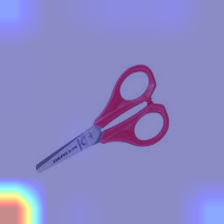


👤 HUMAN CORRECTION EXAMPLE
✅ Correction saved: hazardous → hazardous


KeyError: 'predicted'

In [ ]:
import sys, os, torch, json
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms
from typing import Dict, Optional
from datetime import datetime
from collections import Counter

PROJECT_ROOT = "/content/drive/MyDrive/WASTE_AI_REBUILD"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

CKPT_DIR   = os.path.join(PROJECT_ROOT, "checkpoints")
DEVICE     = "cuda" if torch.cuda.is_available() else "cpu"

TEMPERATURE = 2.0
MC_SAMPLES  = 15
LABELS      = ["dry", "wet", "hazardous", "non_hazardous"]

DISPOSAL_GUIDE = {
    "dry":           "♻️  DRY / RECYCLABLE bin",
    "wet":           "🌱 WET / ORGANIC bin",
    "hazardous":     "⚠️  HAZARDOUS WASTE — Certified facility only",
    "non_hazardous": "🗑️  GENERAL / LANDFILL bin",
}


# ═══════════════════════════════════════════════════════════════════════════════
# WASTE CLASSIFIER
# ═══════════════════════════════════════════════════════════════════════════════

class WasteClassifier:
    """
    Full pipeline:
      1. Temperature-scaled MC Dropout inference
      2. GradCAM heatmap (on MODERATE + LOW confidence predictions)
      3. VerbalReasoner explanation
      4. Human feedback recording
      5. Continual learner integration
    """

    def __init__(self,
                 vision_path:    str  = None,
                 fusion_path:    str  = None,
                 texture_caches: list = None,
                 temperature:    float = 2.0):

        self.device      = torch.device(DEVICE)
        self.temperature = temperature

        if vision_path is None:
            vision_path = os.path.join(CKPT_DIR, "vision_continual.pt")
        if fusion_path is None:
            fusion_path = os.path.join(CKPT_DIR, "fusion_continual.pt")
        if texture_caches is None:
            texture_caches = [
                os.path.join(PROJECT_ROOT, "texture_cache.pt"),
                os.path.join(PROJECT_ROOT, "texture_cache_new_haz.pt"),
                os.path.join(PROJECT_ROOT, "texture_cache_test_manual.pt"),
            ]

        self._load_models(vision_path, fusion_path)
        self._load_texture_caches(texture_caches)
        self._init_xai()

        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        ])

        print(f"✅ WasteClassifier ready on {self.device}")
        print(f"   Temperature : {self.temperature}")
        print(f"   MC samples  : {MC_SAMPLES}")

    # ── Model loading ────────────────────────────────────────────────────────

    def _load_models(self, vision_path: str, fusion_path: str):
        from vision_model import WasteVisionModel
        from multimodal_fusion import MultimodalWasteClassifier
        from uncertainty_engine import UncertaintyEngine

        self.vision  = WasteVisionModel().to(self.device)
        self.fusion  = MultimodalWasteClassifier(
            img_feat_dim=self.vision.feat_dim
        ).to(self.device)
        self.unc_eng = UncertaintyEngine()

        self.vision.load_state_dict(
            torch.load(vision_path, map_location=self.device)
        )
        self.fusion.load_state_dict(
            torch.load(fusion_path, map_location=self.device)
        )

        self.vision.eval()
        self.fusion.train()   # MC Dropout ON

    # ── Texture cache ────────────────────────────────────────────────────────

    def _load_texture_caches(self, cache_paths: list):
        from dataset import load_texture_cache
        self.texture_cache = {}
        for path in cache_paths:
            if os.path.exists(path):
                load_texture_cache(path)
                data = torch.load(path, map_location="cpu")
                for k, v in data.items():
                    self.texture_cache[os.path.abspath(k)] = v
        print(f"   Texture cache: {len(self.texture_cache)} entries")

    def _get_texture(self, img_path: str, img_pil: Image.Image) -> torch.Tensor:
        key = os.path.abspath(img_path)
        if key in self.texture_cache:
            return self.texture_cache[key]
        # Cache miss → compute on the fly with correct params
        from dataset import get_canonical_texture_features
        return get_canonical_texture_features(img_pil)

    # ── XAI init ─────────────────────────────────────────────────────────────

    def _init_xai(self):
        from xai_engine import XAIEngine
        try:
            # IMPORTANT: pass vision (has backbone.0.7), NOT fusion
            self.xai = XAIEngine(self.vision, self.fusion, backbone="efficientnet")
            print(f"   GradCAM     : {'✅ ready' if self.xai.gradcam else '⚠️ verbal only'}")
        except Exception as e:
            print(f"   GradCAM     : ⚠️ unavailable ({e})")
            self.xai = None

    # ── Core prediction ──────────────────────────────────────────────────────

    def predict(self, img_path: str, return_details: bool = False) -> Dict:
        img_pil    = Image.open(img_path).convert("RGB")
        img_tensor = self.transform(img_pil).unsqueeze(0).to(self.device)
        meta       = self._get_texture(img_path, img_pil).unsqueeze(0).to(self.device)

        with torch.no_grad():
            feats = self.vision.get_features(img_tensor)

        # ── Raw prediction (no temperature) ──────────────────────────────────
        with torch.no_grad():
            raw_out   = self.fusion(feats, meta)
            raw_probs = F.softmax(raw_out["logits"], dim=1)
            raw_conf  = raw_probs.max().item()
            raw_pred  = LABELS[raw_probs.argmax().item()]

        # ── Apply temperature only when needed ───────────────────────────────
        need_temp = (
            raw_conf < 0.85 or
            (raw_pred in ["non_hazardous", "dry", "wet"] and raw_conf < 0.80)
        )

        if need_temp:
            mc_preds = []
            with torch.no_grad():
                for _ in range(MC_SAMPLES):
                    out   = self.fusion(feats, meta)
                    probs = F.softmax(out["logits"] / self.temperature, dim=1)
                    mc_preds.append(probs)
            mc_stack   = torch.stack(mc_preds)
            mean_probs = mc_stack.mean(0)
            epistemic  = mc_stack.var(0).sum().item()
        else:
            mean_probs = raw_probs
            epistemic  = 0.0

        confidence = mean_probs.max().item()
        pred       = LABELS[mean_probs.argmax().item()]
        entropy    = -(mean_probs * torch.log(mean_probs + 1e-8)).sum().item()

        # ── Top-2 gap ────────────────────────────────────────────────────────_
        sorted_probs, sorted_idx = torch.sort(mean_probs[0], descending=True)
        top1_prob   = sorted_probs[0].item()
        top2_prob   = sorted_probs[1].item()
        top1_class  = LABELS[sorted_idx[0].item()]
        top2_class  = LABELS[sorted_idx[1].item()]
        top2_gap    = top1_prob - top2_prob
        class_probs = {LABELS[i]: mean_probs[0, i].item() for i in range(4)}

        # ── Uncertainty engine ────────────────────────────────────────────────
        unc = self.unc_eng.evaluate({
            "mean_cls":    mean_probs,
            "entropy_cls": torch.tensor([entropy]),
            "epistemic":   torch.tensor([epistemic]),
        })

        result = {
            "pred":         pred,
            "confidence":   confidence,
            "action":       unc.action,
            "tier":         unc.tier.value,
            "disposal":     DISPOSAL_GUIDE.get(pred, ""),
            "heuristic":    None,
            "image_path":   img_path,
            "raw_conf":     raw_conf,
            "explanation":  None,
            "use_xai":      unc.use_xai,
        }

        # ── Gap heuristic (uncertain non-haz predictions) ─────────────────────
        if (
            top2_gap < 0.08 and
                top1_class != "hazardous" and
                0.40 < top1_prob < 0.55 and
                result["action"] != "HUMAN_REVIEW"):
            result["action"]    = "HUMAN_REVIEW"
            result["tier"]      = "LOW_CONFIDENCE"
            result["heuristic"] = f"SMALL_GAP ({top1_class} vs {top2_class})"
            result["use_xai"]   = True

        # ── XAI (GradCAM + verbal) ────────────────────────────────────────────
        if result["use_xai"] and self.xai is not None:
            meta_np   = meta.squeeze(0).cpu().numpy()
            meta_dict = {
                "texture_contrast":    float(meta_np[0]),
                "texture_homogeneity": float(meta_np[1]),
                "texture_entropy":     float(meta_np[3]),
                "surface_variance":    float(meta_np[4]),
            }
            try:
                result["explanation"] = self.xai.explain(
                    image_tensor = img_tensor.squeeze(0),  # stays on device
                    label        = pred,
                    class_idx    = LABELS.index(pred),
                    confidence   = confidence,
                    class_probs  = class_probs,
                    entropy      = entropy,
                    epistemic    = epistemic,
                    metadata     = meta_dict,
                    action       = result["action"],
                    meta_tensor  = meta,
                )
            except Exception as e:
                print(f"   [XAI] Failed: {e}")

        if return_details:
            result.update({
                "top2_class":  top2_class,
                "top2_prob":   top2_prob,
                "top2_gap":    top2_gap,
                "entropy":     entropy,
                "epistemic":   epistemic,
                "class_probs": class_probs,
            })

        return result

    # ── Formatting ──────────────────────────────────────────────────────────_

    def format_result(self, result: Dict) -> str:
        lines = [
            f"Prediction : {result['pred'].upper()}",
            f"Confidence : {result['confidence']*100:.1f}%",
            f"Action     : {result['action']}",
            f"",
            f"{result['disposal']}",
        ]
        if result.get("heuristic"):
            lines += ["", f"⚠️  Heuristic: {result['heuristic']}"]

        expl = result.get("explanation")
        if expl:
            verbal = expl.get("verbal", {})
            lines += [
                "",
                "── XAI Explanation ──────────────────────",
                f"Classification : {verbal.get('classification', '')}",
                f"Uncertainty    : {verbal.get('uncertainty_note', '')}",
                "",
                "Visual evidence:",
            ]
            for e in verbal.get("visual_evidence", []):
                lines.append(f"  • {e}")
            lines += [
                "",
                "Texture evidence:",
            ]
            for t in verbal.get("texture_evidence", []):
                lines.append(f"  • {t}")
            lines += [
                "",
                f"GradCAM heatmap: {'✅ available' if expl.get('heatmap') is not None else '❌ unavailable'}",
            ]

        return "\n".join(lines)

    # ── Human feedback integration ──────────────────────────────────────────_

    def apply_corrections(self, feedback_system, continual_learner):
        """
        Push human corrections from feedback_system into the continual
        learner replay buffer (with 3x weight).

        Call after accumulating corrections, then call:
            continual_learner.update(loader)
        """
        corrections = feedback_system.get_correction_samples()
        if not corrections:
            print("No corrections to apply.")
            return 0

        applied = 0
        for c in corrections:
            img_path       = c["image_path"]
            correct_label  = LABELS.index(c["correct"])
            original_label = LABELS.index(c["predicted"])

            try:
                img_pil    = Image.open(img_path).convert("RGB")
                img_tensor = self.transform(img_pil).to(self.device)
                meta       = self._get_texture(img_path, img_pil).to(self.device)

                continual_learner.add_human_correction(
                    img_tensor     = img_tensor,
                    meta_tensor    = meta,
                    original_label = original_label,
                    correct_label  = correct_label,
                )
                applied += 1
            except Exception as e:
                print(f"   ⚠️  Skipped {os.path.basename(img_path)}: {e}")

        print(f"✅ {applied}/{len(corrections)} corrections pushed to replay buffer")
        print(f"   Call continual_learner.update(loader) to apply them")
        return applied


# ═══════════════════════════════════════════════════════════════════════════════
# HUMAN FEEDBACK SYSTEM
# ═══════════════════════════════════════════════════════════════════════════════

class HumanFeedbackSystem:
    """Records corrections and feeds them back to the continual learner."""

    def __init__(self, feedback_path: str = None):
        if feedback_path is None:
            feedback_path = os.path.join(PROJECT_ROOT, "human_feedback.json")
        self.feedback_path = feedback_path
        self.corrections   = []
        self._load()

    def _load(self):
        if os.path.exists(self.feedback_path):
            try:
                with open(self.feedback_path) as f:
                    self.corrections = json.load(f)
                print(f"   📋 Loaded {len(self.corrections)} existing corrections")
            except:
                self.corrections = []

    def add_correction(
        self,
        image_path:      str,
        predicted_label: str,
        correct_label:   str,
        confidence:      float,
        reason:          str = "manual_correction",
        notes:           str = "") -> Dict:
        entry = {
            "timestamp":    datetime.now().isoformat(),
            "image_path":   str(image_path),
            "predicted":    predicted_label,
            "correct":      correct_label,
            "confidence":   round(confidence, 4),
            "reason":       reason,
            "notes":        notes,
        }
        self.corrections.append(entry)
        self._save()
        print(f"✅ Correction saved: {predicted_label} → {correct_label}")
        return entry

    def _save(self):
        with open(self.feedback_path, "w") as f:
            json.dump(self.corrections, f, indent=2)

    def get_stats(self) -> Dict:
        if not self.corrections:
            return {"total": 0}
        return {
            "total":        len(self.corrections),
            "by_predicted": dict(Counter(c["predicted"] for c in self.corrections)),
            "by_correct":   dict(Counter(c["correct"]   for c in self.corrections)),
            "avg_conf":     round(
                sum(c["confidence"] for c in self.corrections) / len(self.corrections), 3
            ),
        }

    def print_summary(self):
        s = self.get_stats()
        print(f"\n{'='*50}")
        print("📋 HUMAN FEEDBACK SUMMARY")
        print(f"{'='*50}")
        print(f"Total : {s['total']}")
        if s["total"] > 0:
            print(f"\nBy predicted:")
            for k, v in s.get("by_predicted", {}).items():
                print(f"  {k}: {v}")
            print(f"\nBy correct:")
            for k, v in s.get("by_correct", {}).items():
                print(f"  {k}: {v}")
            print(f"\nAvg confidence: {s.get('avg_conf', 0):.3f}")
        print("="*50)


# ═══════════════════════════════════════════════════════════════════════════════
# TEST HELPER
# ═══════════════════════════════════════════════════════════════════════════════

def run_full_test(
    classifier: WasteClassifier,
    test_dir:   str,
    folder_map: Dict[str, str],
    verbose:    bool = True) -> Dict:
    """
    Run classifier over all folders in folder_map.
    Returns per-class counts and misclassified list.
    """
    stats = {
        "haz_correct": 0, "haz_flagged": 0, "haz_missed": 0, "haz_total": 0,
        "nonhaz_correct": 0, "nonhaz_fp": 0, "nonhaz_wrong": 0, "nonhaz_total": 0,
        "misclassified": [],
    }

    for folder, true_class in folder_map.items():
        folder_path = os.path.join(test_dir, folder)
        if not os.path.exists(folder_path):
            continue

        is_haz = (true_class == "hazardous")

        if verbose:
            print(f"\n📁 {folder.upper()} (true: {true_class})")
            print("-" * 60)

        for fname in sorted(os.listdir(folder_path)):
            if not fname.lower().endswith((".jpg", ".jpeg", ".png")):
                continue

            img_path = os.path.join(folder_path, fname)
            try:
                r = classifier.predict(img_path)
            except Exception as e:
                if verbose:
                    print(f"   ❌ ERROR {fname[:30]}: {e}")
                continue

            heur = f" [{r.get("heuristic")}]" if r.get("heuristic") else ""
            xai  = " 🔍XAI" if r.get("explanation") else ""

            if is_haz:
                stats["haz_total"] += 1
                if r["action"] == "HUMAN_REVIEW":
                    stats["haz_flagged"] += 1
                    outcome = "🔄 FLAGGED"
                elif r["pred"] == "hazardous":
                    stats["haz_correct"] += 1
                    outcome = "✅ CORRECT"
                else:
                    stats["haz_missed"] += 1
                    stats["misclassified"].append({
                        "path": img_path, "folder": folder,
                        "true": true_class, "pred": r["pred"],
                        "conf": r["confidence"],
                    })
                    outcome = "❌ MISSED"
            else:
                stats["nonhaz_total"] += 1
                if r["action"] == "HUMAN_REVIEW":
                    stats["nonhaz_fp"] += 1
                    outcome = "⚠️  FALSE POS"
                elif r["pred"] == true_class:
                    stats["nonhaz_correct"] += 1
                    outcome = "✅ CORRECT"
                else:
                    stats["nonhaz_wrong"] += 1
                    outcome = "❌ WRONG"

            if verbose:
                print(f"   {fname[:32]:<35} {r['pred']:<14} "
                      f"conf={r['confidence']:.2f}{heur}{xai}  {outcome}")

    return stats


def print_summary(stats: Dict):
    ht = stats["haz_total"]
    nt = stats["nonhaz_total"]
    hc = stats["haz_correct"]
    hf = stats["haz_flagged"]
    hm = stats["haz_missed"]
    nc = stats["nonhaz_correct"]
    nf = stats["nonhaz_fp"]
    nw = stats["nonhaz_wrong"]

    catch_rate = (hc + hf) / ht * 100 if ht > 0 else 0
    fp_rate    = nf / nt * 100         if nt > 0 else 0

    print(f"\n{'='*60}")
    print("📊 FINAL RESULTS")
    print(f"{'='*60}")
    print(f"""
  HAZARDOUS ({ht} images):
    ✅ Correct  : {hc:3}/{ht}  ({hc/ht*100:.1f}%)
    🔄 Flagged  : {hf:3}/{ht}  ({hf/ht*100:.1f}%)
    ❌ Missed   : {hm:3}/{ht}  ({hm/ht*100:.1f}%)
    🎯 Catch rate (correct+flagged): {catch_rate:.1f}%

  NON-HAZARDOUS ({nt} images):
    ✅ Correct  : {nc:3}/{nt}  ({nc/nt*100:.1f}%)
    ❌ Wrong    : {nw:3}/{nt}  ({nw/nt*100:.1f}%)
    ⚠️  False pos: {nf:3}/{nt}  ({fp_rate:.1f}%)
""")

    if stats["misclassified"]:
        print("❌ MISSED HAZARDOUS (not flagged):")
        for m in stats["misclassified"]:
            print(f"   {os.path.basename(m['path'])[:40]}")
            print(f"      Pred: {m['pred']} | Conf: {m['conf']:.2f}")


# ═══════════════════════════════════════════════════════════════════════════════
# INITIALISE
# ═══════════════════════════════════════════════════════════════════════════════

print("="*60)
print("🗑️  WASTE AI — COMPLETE SYSTEM")
print("="*60)

classifier = WasteClassifier()
feedback   = HumanFeedbackSystem()

# ═══════════════════════════════════════════════════════════════════════════════
# RUN FULL TEST
# ═══════════════════════════════════════════════════════════════════════════════

TEST_DIR   = os.path.join(PROJECT_ROOT, "datasets/test_manual")

FOLDER_MAP = {
    # Hazardous
    "scissors":         "hazardous",
    "knives":           "hazardous",
    "broken_glass":     "hazardous",
    "broken_glass_test":"hazardous",
    "battery":          "hazardous",
    "syringes":         "hazardous",
    "glass":            "hazardous",
    # Dry
    "cardboard":        "dry",
    "paper":            "dry",
    "metal":            "dry",
    # Wet
    "org-waste":        "wet",
    # Non-hazardous
    "plastic":          "non_hazardous",
    "shoes":            "non_hazardous",
    "cloth":            "non_hazardous",
}

stats = run_full_test(classifier, TEST_DIR, FOLDER_MAP, verbose=True)
print_summary(stats)

# ═══════════════════════════════════════════════════════════════════════════════
# SINGLE IMAGE EXAMPLE WITH FULL XAI
# ═══════════════════════════════════════════════════════════════════════════════

print(f"\n{'='*60}")
print("🔍 SINGLE IMAGE EXAMPLE WITH XAI")
print(f"{'='*60}")

test_img = os.path.join(TEST_DIR, "scissors/scissors1.jpg")
if os.path.exists(test_img):
    result = classifier.predict(test_img, return_details=True)
    print(classifier.format_result(result))

    if result.get("explanation"):
        import numpy as np
        import cv2
        pil_img  = Image.open(test_img).convert("RGB").resize((224, 224))
        img_np   = np.array(pil_img).astype(np.float32)
        heatmap  = result["explanation"]["heatmap"]
        h_uint8  = (heatmap * 255).astype(np.uint8)
        colored  = cv2.applyColorMap(h_uint8, cv2.COLORMAP_JET)
        colored  = cv2.cvtColor(colored, cv2.COLOR_BGR2RGB).astype(np.float32)
        blended  = np.clip((1 - 0.45) * img_np + 0.45 * colored, 0, 255).astype(np.uint8)
        overlay  = Image.fromarray(blended)
        print("Heatmap present:", result["explanation"].get("heatmap") is not None)
        print("Verbal:", result["explanation"].get("verbal", {}).get("classification"))

        from IPython.display import display
        print("\nGradCAM overlay:")
        display(overlay)

# ═══════════════════════════════════════════════════════════════════════════════
# HUMAN CORRECTION EXAMPLE
# ═══════════════════════════════════════════════════════════════════════════════

print(f"\n{'='*60}")
print("👤 HUMAN CORRECTION EXAMPLE")
print(f"{'='*60}")

# Record a correction
feedback.add_correction(
    image_path      = test_img,
    predicted_label = result["pred"],
    correct_label   = "hazardous",
    confidence      = result["confidence"],
    reason          = "manual_correction",
    notes           = "Scissors should always be hazardous",
)

feedback.print_summary()

# ── To apply corrections to the continual learner: ──────────────────────────
# from continual_learner import ContinualLearner
# cl = ContinualLearner(model=classifier.fusion, vision=classifier.vision, device=DEVICE)
# classifier.apply_corrections(feedback, cl)
# cl.update(your_loader)


13-05-2026 - TRYING IMPROVEMENTS TO THE GRADCAM

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


GRADCAM WITH ALL IMAGES

Scanning directory for all images...
✅ Randomly selected 10 images.
📸 Image 1/10: O_10380.jpg


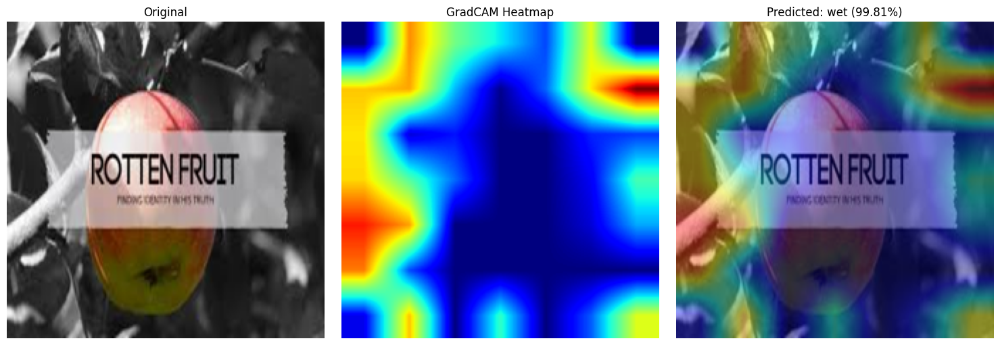


VERBAL EXPLANATION:

Classification: WET (99.8% confidence)

Visual Evidence:
  • Soft/deformed texture characteristic of organic matter.
  • Colour gradients consistent with biological decomposition.
  • Moisture indicators and organic fibrous patterns present.

Texture Analysis:
  • Complex irregular texture (entropy=0.87) — characteristic of organic/wet waste.
  • High surface variance (4.11) — mixed material or contamination detected.

Disposal: 🌱 WET / ORGANIC bin. Remove non-organic packaging.

Uncertainty: High-confidence classification (entropy=0.014), low ambiguity.

📸 Image 2/10: BEOFNIBECYYP_jpg.rf.9957ad380106717c6458c53de09ae086.jpg


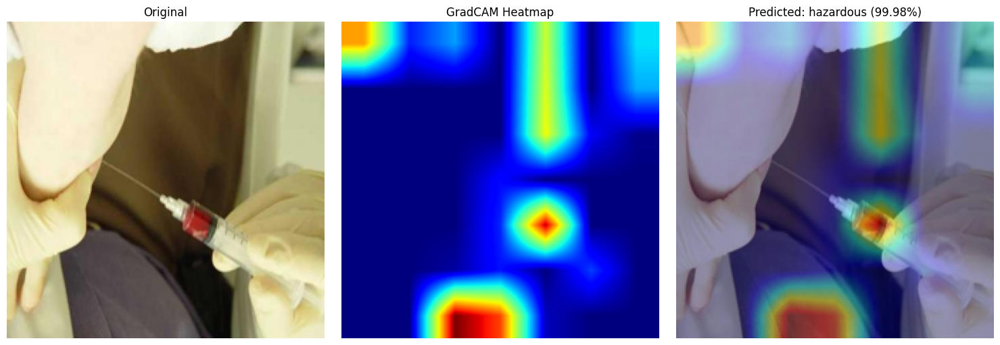


VERBAL EXPLANATION:

Classification: HAZARDOUS (100.0% confidence)

Visual Evidence:
  • Geometry matches battery, e-waste, or chemical container.
  • Metallic sheen and terminal-like features in activation zones.
  • Profile consistent with regulated waste (medical/chemical/electronic).

Texture Analysis:
  • Complex irregular texture (entropy=0.81) — characteristic of organic/wet waste.
  • High surface variance (5.71) — mixed material or contamination detected.

Disposal: ⚠️ Certified hazardous waste facility. Do NOT use regular bins.

Uncertainty: High-confidence classification (entropy=0.002), low ambiguity.

📸 Image 3/10: O0TSQ730URN4_jpg.rf.44e1d986bc1e3ad13455a79b3ba492ed.jpg


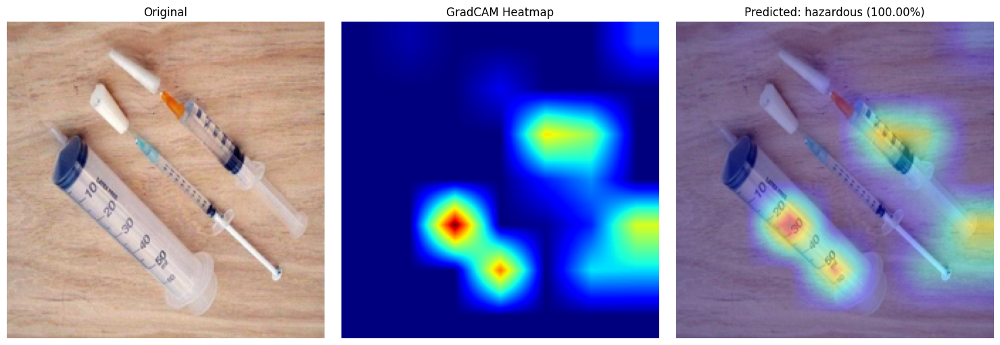


VERBAL EXPLANATION:

Classification: HAZARDOUS (100.0% confidence)

Visual Evidence:
  • Geometry matches battery, e-waste, or chemical container.
  • Metallic sheen and terminal-like features in activation zones.
  • Profile consistent with regulated waste (medical/chemical/electronic).

Texture Analysis:
  • Complex irregular texture (entropy=0.79) — characteristic of organic/wet waste.
  • High surface variance (0.63) — mixed material or contamination detected.

Disposal: ⚠️ Certified hazardous waste facility. Do NOT use regular bins.

Uncertainty: High-confidence classification (entropy=0.000), low ambiguity.

📸 Image 4/10: LWMGSEA02NQX_jpg.rf.75fd17996cd501a9c7b34106d1db7dc1.jpg


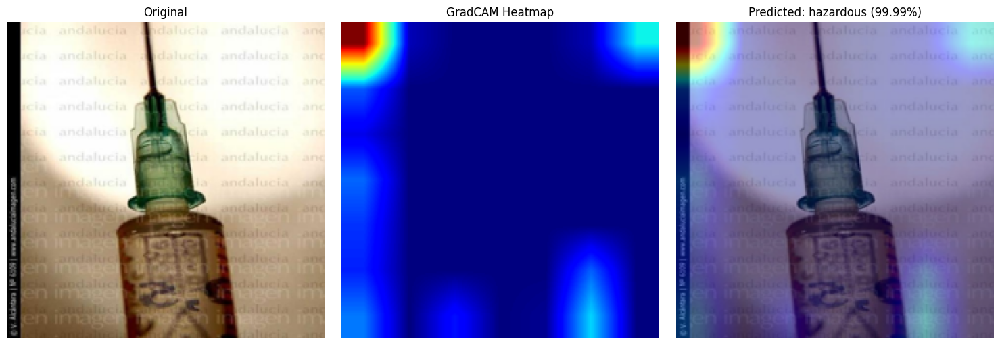


VERBAL EXPLANATION:

Classification: HAZARDOUS (100.0% confidence)

Visual Evidence:
  • Geometry matches battery, e-waste, or chemical container.
  • Metallic sheen and terminal-like features in activation zones.
  • Profile consistent with regulated waste (medical/chemical/electronic).

Texture Analysis:
  • Complex irregular texture (entropy=0.83) — characteristic of organic/wet waste.
  • High surface variance (5.51) — mixed material or contamination detected.

Disposal: ⚠️ Certified hazardous waste facility. Do NOT use regular bins.

Uncertainty: High-confidence classification (entropy=0.001), low ambiguity.

📸 Image 5/10: cardboard_369.jpg


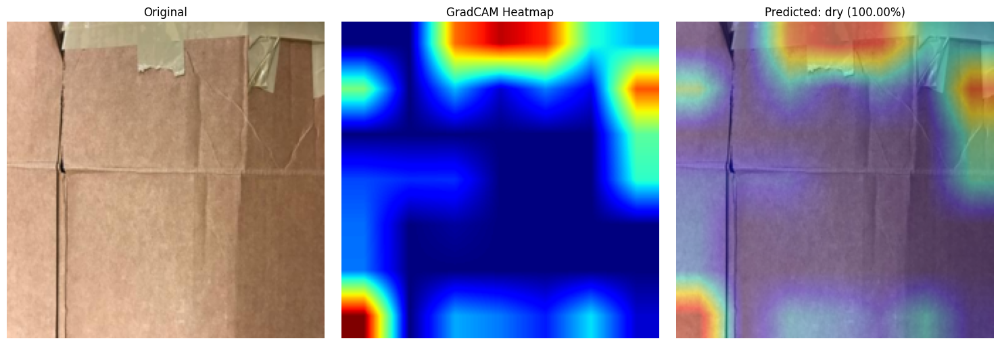


VERBAL EXPLANATION:

Classification: DRY (100.0% confidence)

Visual Evidence:
  • Rigid, non-porous surface consistent with recyclable material.
  • Texture matches plastic, metal, glass, or paper profiles.
  • No organic patterns or hazardous signatures detected.

Texture Analysis:
  • Complex irregular texture (entropy=0.79) — characteristic of organic/wet waste.
  • High surface variance (1.07) — mixed material or contamination detected.

Disposal: ♻ DRY / RECYCLABLE bin. Ensure item is clean.

Uncertainty: High-confidence classification (entropy=0.001), low ambiguity.

📸 Image 6/10: plastic_278.jpg


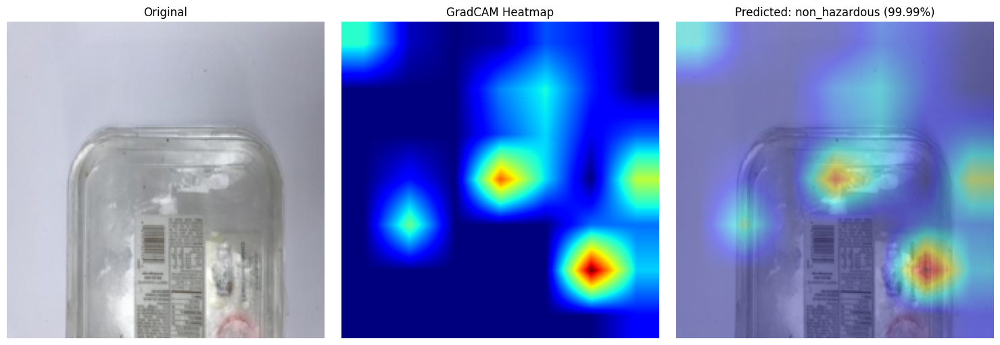


VERBAL EXPLANATION:

Classification: NON_HAZARDOUS (100.0% confidence)

Visual Evidence:
  • Inert surface — no hazardous chemical or biological properties.
  • Texture consistent with ceramics, rubber, dense foam.
  • Safe for standard landfill, not suitable for recycling.

Texture Analysis:
  • Complex irregular texture (entropy=0.68) — characteristic of organic/wet waste.
  • High surface variance (0.68) — mixed material or contamination detected.

Disposal: 🗑 GENERAL / LANDFILL bin. Safe but not recyclable.

Uncertainty: High-confidence classification (entropy=0.001), low ambiguity.

📸 Image 7/10: O_10230.jpg


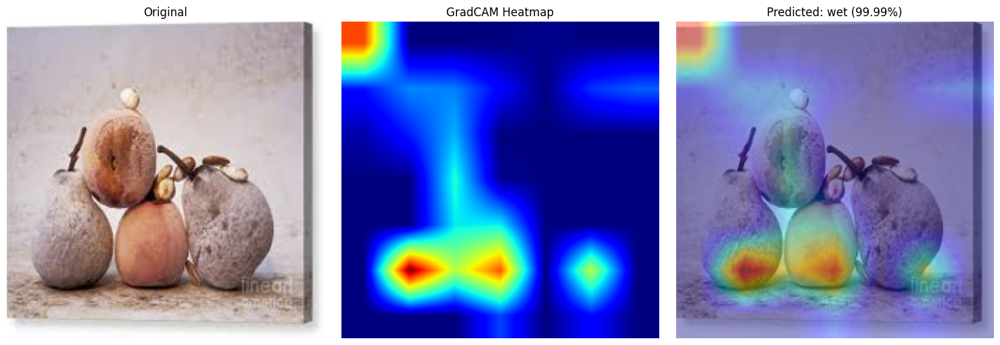


VERBAL EXPLANATION:

Classification: WET (100.0% confidence)

Visual Evidence:
  • Soft/deformed texture characteristic of organic matter.
  • Colour gradients consistent with biological decomposition.
  • Moisture indicators and organic fibrous patterns present.

Texture Analysis:
  • Complex irregular texture (entropy=0.82) — characteristic of organic/wet waste.
  • High surface variance (2.01) — mixed material or contamination detected.

Disposal: 🌱 WET / ORGANIC bin. Remove non-organic packaging.

Uncertainty: High-confidence classification (entropy=0.001), low ambiguity.

📸 Image 8/10: plastic_390.jpg


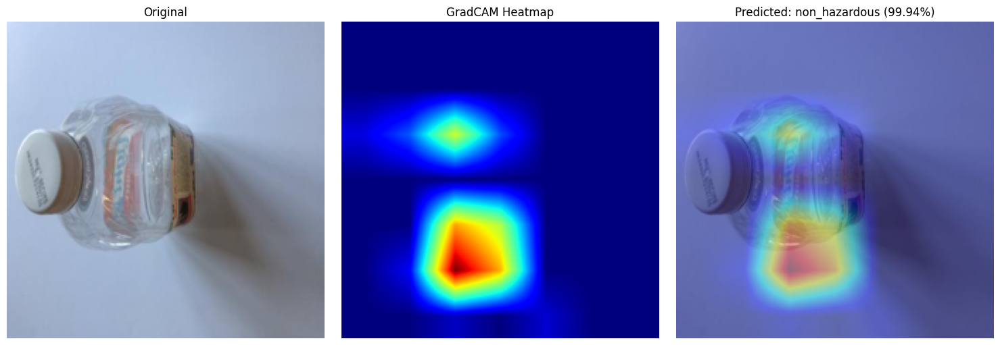


VERBAL EXPLANATION:

Classification: NON_HAZARDOUS (99.9% confidence)

Visual Evidence:
  • Inert surface — no hazardous chemical or biological properties.
  • Texture consistent with ceramics, rubber, dense foam.
  • Safe for standard landfill, not suitable for recycling.

Texture Analysis:
  • Complex irregular texture (entropy=0.65) — characteristic of organic/wet waste.
  • High surface variance (1.03) — mixed material or contamination detected.

Disposal: 🗑 GENERAL / LANDFILL bin. Safe but not recyclable.

Uncertainty: High-confidence classification (entropy=0.006), low ambiguity.

📸 Image 9/10: background-heap-old-dirty-clothes-recycling-top-view-secondary-utilization-concept-175986639.jpg


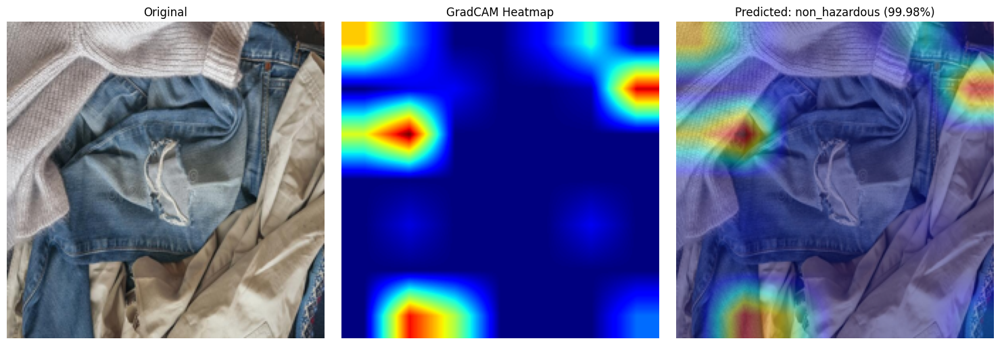


VERBAL EXPLANATION:

Classification: NON_HAZARDOUS (100.0% confidence)

Visual Evidence:
  • Inert surface — no hazardous chemical or biological properties.
  • Texture consistent with ceramics, rubber, dense foam.
  • Safe for standard landfill, not suitable for recycling.

Texture Analysis:
  • Complex irregular texture (entropy=1.01) — characteristic of organic/wet waste.
  • High surface variance (2.32) — mixed material or contamination detected.

Disposal: 🗑 GENERAL / LANDFILL bin. Safe but not recyclable.

Uncertainty: High-confidence classification (entropy=0.002), low ambiguity.

📸 Image 10/10: abandoned-clothes-background-looking-down-piles-colourful-old-clothes-discarded-ground-abandoned-clothes-background-174236667.jpg


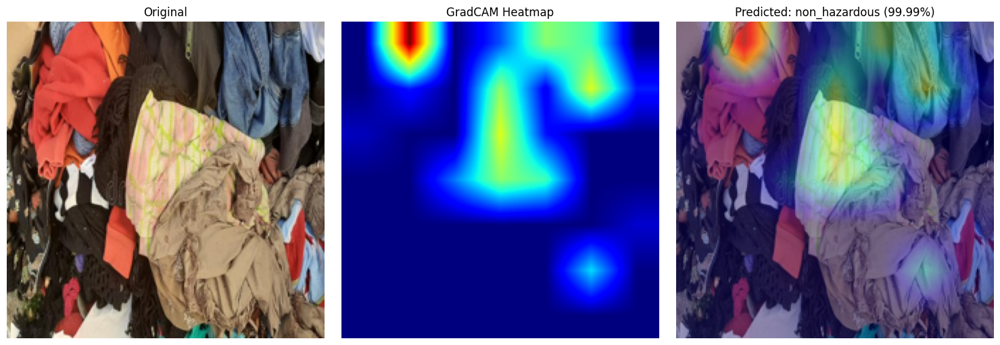


VERBAL EXPLANATION:

Classification: NON_HAZARDOUS (100.0% confidence)

Visual Evidence:
  • Inert surface — no hazardous chemical or biological properties.
  • Texture consistent with ceramics, rubber, dense foam.
  • Safe for standard landfill, not suitable for recycling.

Texture Analysis:
  • Complex irregular texture (entropy=1.03) — characteristic of organic/wet waste.
  • High surface variance (3.47) — mixed material or contamination detected.

Disposal: 🗑 GENERAL / LANDFILL bin. Safe but not recyclable.

Uncertainty: High-confidence classification (entropy=0.001), low ambiguity.



In [ ]:
import torch
import torchvision.transforms as T
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import sys
import os
import cv2
import random
import glob

# ─────────────────────────────
# CONFIG
# ─────────────────────────────
path = "/content/drive/MyDrive/WASTE_AI_REBUILD"
if path not in sys.path:
    sys.path.insert(0, path)
os.chdir(path)

from vision_model import WasteVisionModel
from multimodal_fusion import MultimodalWasteClassifier
from xai_engine import XAIEngine
from dataset import get_texture_feature, get_canonical_texture_features

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CLASS_NAMES = ["dry", "wet", "hazardous", "non_hazardous"]

VISION_PATH = "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/vision_best.pt"
FUSION_PATH = "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/fusion_best.pt"
TEST_DIR = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/test_manual"

# How many random images do you want?
NUM_RANDOM_IMAGES = 10

# ─────────────────────────────
# LOAD MODELS
# ─────────────────────────────
vision = WasteVisionModel().to(DEVICE)
fusion = MultimodalWasteClassifier(img_feat_dim=vision.feat_dim).to(DEVICE)

vision.load_state_dict(torch.load(VISION_PATH, map_location=DEVICE))
fusion.load_state_dict(torch.load(FUSION_PATH, map_location=DEVICE))

vision.eval()
fusion.eval()

# XAIEngine only takes the vision model
xai_engine = XAIEngine(vision, fusion, backbone="efficientnet")

transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# ─────────────────────────────
# GRADCAM FUNCTION
# ─────────────────────────────
def run_gradcam_on_image(img_path):
    """Run GradCAM on a single image and display results."""

    img_pil = Image.open(img_path).convert("RGB")
    img_tensor = transform(img_pil).unsqueeze(0).to(DEVICE)

    # Get texture features
    try:
        meta = get_texture_feature(img_path).unsqueeze(0).to(DEVICE)
    except (KeyError, RuntimeError):
        meta = get_canonical_texture_features(img_pil).unsqueeze(0).to(DEVICE)

    # Predict
    with torch.no_grad():
        features = vision.get_features(img_tensor)
        outputs = fusion(features, meta)
        probabilities = torch.softmax(outputs["logits"], dim=1)
        _, predicted_idx = torch.max(probabilities, 1)
        pred_name = CLASS_NAMES[predicted_idx.item()]
        confidence = probabilities[0, predicted_idx.item()].item()

    class_probs = {name: probabilities[0, i].item() for i, name in enumerate(CLASS_NAMES)}
    target_class_idx = predicted_idx.item()

    # Metadata for explanation
    meta_np = meta.squeeze(0).cpu().numpy()
    metadata_dict = {
        "texture_contrast": float(meta_np[0]), "texture_homogeneity": float(meta_np[1]),
        "texture_energy": float(meta_np[2]), "texture_entropy": float(meta_np[3]),
        "surface_variance": float(meta_np[4]),
    }

    # Get XAI Explanation
    explanation = xai_engine.explain(
        image_tensor=img_tensor.squeeze(0), label=pred_name, class_idx=target_class_idx,
        confidence=confidence, class_probs=class_probs,
        entropy=-sum(p * np.log(p + 1e-8) for p in class_probs.values()),
        epistemic=0.0, metadata=metadata_dict,
        action="AUTO_SORT" if confidence >= 0.8 else "HUMAN_REVIEW",
    )

    heatmap_raw = explanation.get("heatmap")
    if heatmap_raw is None:
        heatmap_raw = np.zeros((224, 224))

    verbal = explanation.get("verbal", {})

    # ── Blending logic ──
    orig_img_display = img_pil.resize((224, 224))
    orig_img_np = np.array(orig_img_display).astype(np.float32) / 255.0

    heatmap_resized = cv2.resize(heatmap_raw, (orig_img_np.shape[1], orig_img_np.shape[0]))
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

    alpha = 0.4
    overlay_blended = np.uint8(255 * np.clip(alpha * heatmap_colored + (1 - alpha) * orig_img_np, 0, 1))

    # ── Display ──
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(orig_img_display); axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(heatmap_raw, cmap="jet"); axes[1].set_title("GradCAM Heatmap"); axes[1].axis("off")
    axes[2].imshow(overlay_blended); axes[2].set_title(f"Predicted: {pred_name} ({confidence:.2%})"); axes[2].axis("off")
    plt.tight_layout()
    plt.show()

    # ── Print Text ──
    print("\n" + "="*60)
    print("VERBAL EXPLANATION:")
    print("="*60)
    print(f"\nClassification: {verbal.get('classification', 'N/A')}")
    print("\nVisual Evidence:")
    for e in verbal.get("visual_evidence", []): print(f"  • {e}")
    print("\nTexture Analysis:")
    for e in verbal.get("texture_evidence", []): print(f"  • {e}")
    print(f"\nDisposal: {verbal.get('disposal', 'N/A')}")
    print(f"\nUncertainty: {verbal.get('uncertainty_note', 'N/A')}\n")

    return pred_name, confidence, explanation


# ─────────────────────────────
# PURE RANDOM SELECTION
# ─────────────────────────────
print("Scanning directory for all images...")
all_images = glob.glob(os.path.join(TEST_DIR, "**/*.jpg"), recursive=True)
all_images += glob.glob(os.path.join(TEST_DIR, "**/*.jpeg"), recursive=True)
all_images += glob.glob(os.path.join(TEST_DIR, "**/*.png"), recursive=True)
all_images = list(set(all_images)) # Remove duplicates

if len(all_images) < NUM_RANDOM_IMAGES:
    print(f"⚠️ Only found {len(all_images)} images. Running all of them.")
    selected_test_images = all_images
else:
    # Pick exactly N random images
    selected_test_images = random.sample(all_images, NUM_RANDOM_IMAGES)
    print(f"✅ Randomly selected {NUM_RANDOM_IMAGES} images.")

# ─────────────────────────────
# RUN LOOP
# ─────────────────────────────
for i, img_path in enumerate(selected_test_images):
    print(f"{'='*60}")
    print(f"📸 Image {i+1}/{len(selected_test_images)}: {os.path.basename(img_path)}")
    print(f"{'='*60}")
    try:
        run_gradcam_on_image(img_path)
    except Exception as e:
        print(f"❌ Error processing {img_path}: {e}")

GRADCAM WITH ONE IMAGE


📸 /content/drive/MyDrive/WASTE_AI_REBUILD/datasets/test_manual/twix.jpg


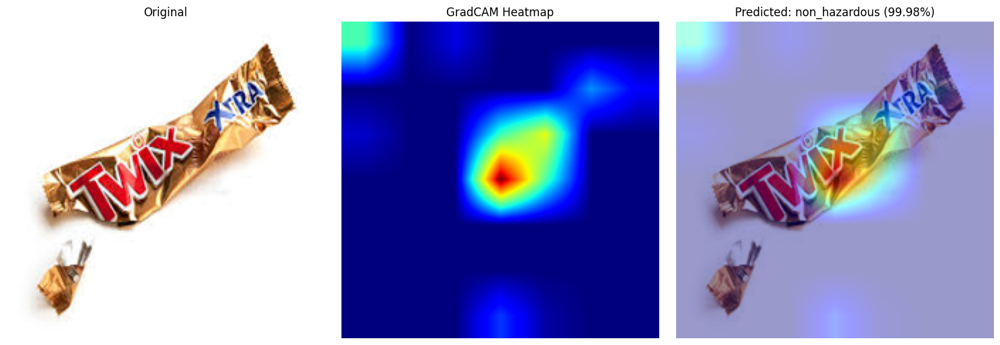


VERBAL EXPLANATION:

Classification: NON_HAZARDOUS (100.0% confidence)

Visual Evidence:
  • Inert surface — no hazardous chemical or biological properties.
  • Texture consistent with ceramics, rubber, dense foam.
  • Safe for standard landfill, not suitable for recycling.

Texture Analysis:
  • Complex irregular texture (entropy=0.37) — characteristic of organic/wet waste.
  • High surface variance (2.78) — mixed material or contamination detected.

Disposal: 🗑 GENERAL / LANDFILL bin. Safe but not recyclable.

Uncertainty: High-confidence classification (entropy=0.002), low ambiguity.


In [ ]:
import torch
import torchvision.transforms as T
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import sys
import os
import cv2

# ─────────────────────────────
# CONFIG
# ─────────────────────────────
path = "/content/drive/MyDrive/WASTE_AI_REBUILD"
if path not in sys.path:
    sys.path.insert(0, path)
os.chdir(path)

from vision_model import WasteVisionModel
from multimodal_fusion import MultimodalWasteClassifier
from xai_engine import XAIEngine  # ✅ Use the unified XAI engine
from dataset import get_texture_feature, get_canonical_texture_features

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CLASS_NAMES = ["dry", "wet", "hazardous", "non_hazardous"]

VISION_PATH = "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/vision_best.pt"
FUSION_PATH = "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/fusion_best.pt"

# ─────────────────────────────
# LOAD MODELS
# ─────────────────────────────
vision = WasteVisionModel().to(DEVICE)
fusion = MultimodalWasteClassifier(img_feat_dim=vision.feat_dim).to(DEVICE)

vision.load_state_dict(torch.load(VISION_PATH, map_location=DEVICE))
fusion.load_state_dict(torch.load(FUSION_PATH, map_location=DEVICE))

vision.eval()
fusion.eval()

# ─────────────────────────────
# SETUP XAI ENGINE (FIXED)
# ─────────────────────────────
# ✅ XAIEngine only needs the vision model (contains GradCAM internally)
xai_engine = XAIEngine(vision, fusion, backbone="efficientnet")

# ─────────────────────────────
# PREPROCESSING — MUST MATCH TRAINING
# ─────────────────────────────
transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]),
])


def run_gradcam_on_image(img_path, target_class=None):
    """Run GradCAM on a single image and display results."""

    # Load and preprocess
    img_pil = Image.open(img_path).convert("RGB")
    img_tensor = transform(img_pil).unsqueeze(0).to(DEVICE)

    # Get texture features (with fallback)
    meta = None
    try:
        meta = get_texture_feature(img_path).unsqueeze(0).to(DEVICE)
    except (KeyError, RuntimeError):
        meta = get_canonical_texture_features(img_pil).unsqueeze(0).to(DEVICE)

    # Perform prediction using fusion model
    with torch.no_grad():
        features = vision.get_features(img_tensor)
        outputs = fusion(features, meta)
        probabilities = torch.softmax(outputs["logits"], dim=1)
        _, predicted_idx = torch.max(probabilities, 1)
        pred_name = CLASS_NAMES[predicted_idx.item()]
        confidence = probabilities[0, predicted_idx.item()].item()

    # Build class_probs dict for XAI
    class_probs = {name: probabilities[0, i].item()
                   for i, name in enumerate(CLASS_NAMES)}

    # Determine target class index for GradCAM
    target_class_idx = predicted_idx.item()
    if target_class is not None:
        if target_class in CLASS_NAMES:
            target_class_idx = CLASS_NAMES.index(target_class)
        else:
            print(f"Warning: '{target_class}' not in CLASS_NAMES. Using predicted class.")

    # Build metadata dict for verbal explanation
    meta_np = meta.squeeze(0).cpu().numpy()
    metadata_dict = {
        "texture_contrast": float(meta_np[0]),
        "texture_homogeneity": float(meta_np[1]),
        "texture_energy": float(meta_np[2]),
        "texture_entropy": float(meta_np[3]),
        "surface_variance": float(meta_np[4]),
    }

    # ✅ Use XAIEngine.explain() - proper interface
    explanation = xai_engine.explain(
        image_tensor=img_tensor.squeeze(0),
        label=pred_name,
        class_idx=target_class_idx,
        confidence=confidence,
        class_probs=class_probs,
        entropy=-sum(p * np.log(p + 1e-8) for p in class_probs.values()),
        epistemic=0.0,  # Would need MC Dropout for true epistemic
        metadata=metadata_dict,
        action="AUTO_SORT" if confidence >= 0.8 else "HUMAN_REVIEW",
    )

    # Extract heatmap
    heatmap_raw = explanation.get("heatmap")
    if heatmap_raw is None:
        print("Warning: GradCAM failed to generate heatmap")
        heatmap_raw = np.zeros((224, 224))

    # Extract verbal explanation
    verbal = explanation.get("verbal", {})

    # ── Blending logic ──
    orig_img_display = img_pil.resize((224, 224))
    orig_img_np = np.array(orig_img_display).astype(np.float32) / 255.0

    heatmap_resized = cv2.resize(heatmap_raw, (orig_img_np.shape[1], orig_img_np.shape[0]))
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

    alpha = 0.4
    overlay_blended = alpha * heatmap_colored + (1 - alpha) * orig_img_np
    overlay_blended = np.uint8(255 * np.clip(overlay_blended, 0, 1))

    # ── Display ──
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(orig_img_display)
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(heatmap_raw, cmap="jet")
    axes[1].set_title("GradCAM Heatmap")
    axes[1].axis("off")

    axes[2].imshow(overlay_blended)
    axes[2].set_title(f"Predicted: {pred_name} ({confidence:.2%})")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

    # ── Print verbal explanation ──
    print("\n" + "="*60)
    print("VERBAL EXPLANATION:")
    print("="*60)
    print(f"\nClassification: {verbal.get('classification', 'N/A')}")

    print("\nVisual Evidence:")
    for e in verbal.get("visual_evidence", []):
        print(f"  • {e}")

    print("\nTexture Analysis:")
    for e in verbal.get("texture_evidence", []):
        print(f"  • {e}")

    print(f"\nDisposal: {verbal.get('disposal', 'N/A')}")
    print(f"\nUncertainty: {verbal.get('uncertainty_note', 'N/A')}")

    return pred_name, confidence, explanation


# ─────────────────────────────
# RUN ON TEST IMAGES
# ─────────────────────────────
import glob

test_images = glob.glob("/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/test_manual/**/*.jpg", recursive=True)
test_images += glob.glob("/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/test_manual/**/*.png", recursive=True)

if test_images:
    img_path = test_images[0]
    print(f"\n📸 {img_path}")
    run_gradcam_on_image(img_path)
else:
    print("No test images found.")

GRADIO

In [ ]:
import gradio as gr
import numpy as np
import cv2
from PIL import Image
import tempfile, os

def classify_image(uploaded_image):
    if uploaded_image is None:
        return "No image uploaded.", None, None

    # Save uploaded image to temp file
    with tempfile.NamedTemporaryFile(suffix=".jpg", delete=False) as f:
        temp_path = f.name
        Image.fromarray(uploaded_image).save(temp_path)

    try:
        result = classifier.predict(temp_path, return_details=True)
    except Exception as e:
        return f"Error: {e}", None, None
    finally:
        os.unlink(temp_path)

    # ── Text output ───────────────────────────────────────────────────────────
    pred       = result["pred"].upper()
    conf       = result["confidence"] * 100
    action     = result["action"]
    tier       = result["tier"]
    disposal   = result["disposal"]
    entropy    = result.get("entropy", 0)
    epistemic  = result.get("epistemic", 0)
    class_probs= result.get("class_probs", {})
    heuristic  = result.get("heuristic", None)

    bars = ""
    for label, prob in class_probs.items():
        bar = "█" * int(prob * 30)
        bars += f"\n  {label:<20}: {prob*100:5.1f}%  {bar}"

    text = f"""
{'='*55}
  PREDICTION   : {pred}
  CONFIDENCE   : {conf:.1f}%
  ACTION       : {action}
  TIER         : {tier}
  DISPOSAL     : {disposal}
{'='*55}

CLASS PROBABILITIES:{bars}

UNCERTAINTY METRICS:
  Entropy      : {entropy:.4f}
  Epistemic    : {epistemic:.4f}
"""
    if heuristic:
        text += f"\n⚠️  Heuristic fired: {heuristic}"

    expl = result.get("explanation")
    if expl:
        verbal = expl.get("verbal", {})
        text += f"""
{'─'*45}
XAI EXPLANATION
{'─'*45}
Classification : {verbal.get('classification', '')}
Uncertainty    : {verbal.get('uncertainty_note', '')}
Disposal       : {verbal.get('disposal', '')}

Visual Evidence:"""
        for e in verbal.get("visual_evidence", []):
            text += f"\n  • {e}"
        text += "\n\nTexture Evidence:"
        for t in verbal.get("texture_evidence", []):
            text += f"\n  • {t}"

    # ── GradCAM overlay ───────────────────────────────────────────────────────
    overlay_img = None
    if expl and expl.get("heatmap") is not None:
        heatmap  = expl["heatmap"]
        img_pil  = Image.fromarray(uploaded_image).resize((224, 224))
        img_np   = np.array(img_pil).astype(np.float32)
        h_uint8  = (heatmap * 255).astype(np.uint8)
        colored  = cv2.applyColorMap(h_uint8, cv2.COLORMAP_JET)
        colored  = cv2.cvtColor(colored, cv2.COLOR_BGR2RGB).astype(np.float32)
        blended  = np.clip(0.55 * img_np + 0.45 * colored, 0, 255).astype(np.uint8)
        overlay_img = Image.fromarray(blended)

    # ── Confidence bar chart ──────────────────────────────────────────────────
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(6, 3))
    labels  = list(class_probs.keys())
    values  = [class_probs[l] * 100 for l in labels]
    colors  = ["#e74c3c" if l == "hazardous" else
               "#2ecc71" if l == "dry" else
               "#3498db" if l == "wet" else
               "#95a5a6" for l in labels]
    bars_plot = ax.barh(labels, values, color=colors)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Probability (%)")
    ax.set_title(f"Predicted: {pred} ({conf:.1f}%)", fontweight="bold")
    for bar, val in zip(bars_plot, values):
        ax.text(val + 1, bar.get_y() + bar.get_height()/2,
                f"{val:.1f}%", va="center", fontsize=9)
    plt.tight_layout()

    chart_path = "/tmp/conf_chart.png"
    plt.savefig(chart_path, dpi=100)
    plt.close()
    chart_img = Image.open(chart_path)

    return text, overlay_img, chart_img


# ── Gradio UI ─────────────────────────────────────────────────────────────────
with gr.Blocks(title="WasteAI Classifier") as demo:
    gr.Markdown("# 🗑️ WasteAI — Waste Classification System")
    gr.Markdown("Upload an image to classify waste and get disposal guidance.")

    with gr.Row():
        with gr.Column(scale=1):
            img_input = gr.Image(label="Upload Image", type="numpy")
            submit_btn = gr.Button("Classify", variant="primary")

        with gr.Column(scale=2):
            text_output   = gr.Textbox(label="Classification Result",
                                       lines=30, max_lines=50)

    with gr.Row():
        gradcam_output = gr.Image(label="GradCAM Heatmap Overlay")
        chart_output   = gr.Image(label="Class Probability Chart")

    submit_btn.click(
        fn=classify_image,
        inputs=[img_input],
        outputs=[text_output, gradcam_output, chart_output]
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d28c9bd985010c9ff1.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# Modified Gradio UI with Human-in-the-Loop Feedback

In [ ]:
import gradio as gr
import numpy as np
import cv2
from PIL import Image
import tempfile, os
import json
from datetime import datetime
import hashlib

# ─────────────────────────────────────────────────────────
# JSON STORAGE CONFIG
# ─────────────────────────────────────────────────────────
FEEDBACK_FILE = "human_feedback.json"
HISTORY_FILE = "prediction_history.json"
CONFIDENCE_THRESHOLD = 0.6
CLASS_NAMES = ["wet", "dry", "hazardous", "non_hazardous"]

def load_json(filepath, default=None):
    if default is None:
        default = []
    if os.path.exists(filepath):
        try:
            with open(filepath, 'r', encoding='utf-8') as f:
                return json.load(f)
        except:
            return default
    return default

def save_json(filepath, data):
    with open(filepath, 'w', encoding='utf-8') as f:
        json.dump(data, f, indent=2, ensure_ascii=False)

# ─────────────────────────────────────────────────────────
# STATE STORAGE (for linking feedback to prediction)
# ─────────────────────────────────────────────────────────
current_prediction = {
    "image_hash": None,
    "pred": None,
    "confidence": None,
    "class_probs": None,
    "timestamp": None,
    "needs_review": False
}

# ─────────────────────────────────────────────────────────
# YOUR EXACT classify_image FUNCTION (modified return only)
# ─────────────────────────────────────────────────────────
def classify_image(uploaded_image):
    if uploaded_image is None:
        return "No image uploaded.", None, None, gr.update(visible=False), gr.update(value=None)

    # Generate image hash for tracking
    img_pil = Image.fromarray(uploaded_image) if isinstance(uploaded_image, np.ndarray) else uploaded_image
    image_hash = hashlib.md5(img_pil.tobytes()).hexdigest()[:12]

    # Save uploaded image to temp file
    with tempfile.NamedTemporaryFile(suffix=".jpg", delete=False) as f:
        temp_path = f.name
        img_pil.save(temp_path)

    try:
        result = classifier.predict(temp_path, return_details=True)
    except Exception as e:
        os.unlink(temp_path)
        return f"Error: {e}", None, None, gr.update(visible=False), gr.update(value=None)
    finally:
        if os.path.exists(temp_path):
            os.unlink(temp_path)

    # ── Text output ───────────────────────────────────────────────────────────
    pred       = result["pred"].upper()
    conf       = result["confidence"] * 100
    action     = result["action"]
    tier       = result["tier"]
    disposal   = result["disposal"]
    entropy    = result.get("entropy", 0)
    epistemic  = result.get("epistemic", 0)
    class_probs= result.get("class_probs", {})
    heuristic  = result.get("heuristic", None)

    bars = ""
    for label, prob in class_probs.items():
        bar = "█" * int(prob * 30)
        bars += f"\n  {label:<20}: {prob*100:5.1f}%  {bar}"

    # Check if human review needed
    needs_review = result["confidence"] < CONFIDENCE_THRESHOLD
    review_status = ""
    if needs_review:
        review_status = f"\n{'!'*55}\n  ⚠️  HUMAN REVIEW REQUIRED (Confidence < {CONFIDENCE_THRESHOLD*100:.0f}%)\n  Please select the correct classification below.\n{'!'*55}"

    text = f"""
{'='*55}
  PREDICTION   : {pred}
  CONFIDENCE   : {conf:.1f}%
  ACTION       : {action}
  TIER         : {tier}
  DISPOSAL     : {disposal}
{'='*55}
{review_status}
CLASS PROBABILITIES:{bars}

UNCERTAINTY METRICS:
  Entropy      : {entropy:.4f}
  Epistemic    : {epistemic:.4f}
"""
    if heuristic:
        text += f"\n⚠️  Heuristic fired: {heuristic}"

    expl = result.get("explanation")
    if expl:
        verbal = expl.get("verbal", {})
        text += f"""
{'─'*45}
XAI EXPLANATION
{'─'*45}
Classification : {verbal.get('classification', '')}
Uncertainty    : {verbal.get('uncertainty_note', '')}
Disposal       : {verbal.get('disposal', '')}

Visual Evidence:"""
        for e in verbal.get("visual_evidence", []):
            text += f"\n  • {e}"
        text += "\n\nTexture Evidence:"
        for t in verbal.get("texture_evidence", []):
            text += f"\n  • {t}"

    # ── GradCAM overlay ───────────────────────────────────────────────────────
    overlay_img = None
    if expl and expl.get("heatmap") is not None:
        heatmap  = expl["heatmap"]
        img_pil  = Image.fromarray(uploaded_image).resize((224, 224))
        img_np   = np.array(img_pil).astype(np.float32)
        h_uint8  = (heatmap * 255).astype(np.uint8)
        colored  = cv2.applyColorMap(h_uint8, cv2.COLORMAP_JET)
        colored  = cv2.cvtColor(colored, cv2.COLOR_BGR2RGB).astype(np.float32)
        blended  = np.clip(0.55 * img_np + 0.45 * colored, 0, 255).astype(np.uint8)
        overlay_img = Image.fromarray(blended)

    # ── Confidence bar chart ──────────────────────────────────────────────────
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(6, 3))
    labels  = list(class_probs.keys())
    values  = [class_probs[l] * 100 for l in labels]
    colors  = ["#e74c3c" if l == "hazardous" else
               "#2ecc71" if l == "dry" else
               "#3498db" if l == "wet" else
               "#95a5a6" for l in labels]
    bars_plot = ax.barh(labels, values, color=colors)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Probability (%)")
    ax.set_title(f"Predicted: {pred} ({conf:.1f}%)", fontweight="bold")
    for bar, val in zip(bars_plot, values):
        ax.text(val + 1, bar.get_y() + bar.get_height()/2,
                f"{val:.1f}%", va="center", fontsize=9)
    plt.tight_layout()

    chart_path = "/tmp/conf_chart.png"
    plt.savefig(chart_path, dpi=100)
    plt.close()
    chart_img = Image.open(chart_path)

    # ── Save to history ───────────────────────────────────────────────────────
    timestamp = datetime.now().isoformat()
    history_entry = {
        "timestamp": timestamp,
        "image_hash": image_hash,
        "predicted_class": pred.lower(),
        "confidence": result["confidence"],
        "probabilities": {k: round(v, 4) for k, v in class_probs.items()},
        "needs_review": needs_review,
        "human_feedback": None
    }
    history = load_json(HISTORY_FILE)
    history.append(history_entry)
    save_json(HISTORY_FILE, history)

    # ── Store current prediction state for feedback ───────────────────────────
    current_prediction["image_hash"] = image_hash
    current_prediction["pred"] = pred.lower()
    current_prediction["confidence"] = result["confidence"]
    current_prediction["class_probs"] = class_probs
    current_prediction["timestamp"] = timestamp
    current_prediction["needs_review"] = needs_review

    # Show/hide feedback section
    feedback_visible = gr.update(visible=True) if needs_review else gr.update(visible=False)

    return text, overlay_img, chart_img, feedback_visible, gr.update(value=None)


# ─────────────────────────────────────────────────────────
# FEEDBACK SUBMISSION FUNCTION
# ─────────────────────────────────────────────────────────
def submit_feedback(radio_selection):
    if radio_selection is None:
        return "❌ Please select a classification first.", gr.update(visible=True), gr.update(value=None)

    if not current_prediction["needs_review"]:
        return "ℹ️ No feedback needed for this prediction.", gr.update(visible=False), gr.update(value=None)

    # Create feedback entry
    feedback_entry = {
        "timestamp": datetime.now().isoformat(),
        "image_hash": current_prediction["image_hash"],
        "model_prediction": current_prediction["pred"],
        "model_confidence": round(current_prediction["confidence"], 4),
        "model_probabilities": {k: round(v, 4) for k, v in current_prediction["class_probs"].items()},
        "human_label": radio_selection,
        "agrees_with_model": radio_selection == current_prediction["pred"]
    }

    # Save feedback
    feedback = load_json(FEEDBACK_FILE)
    feedback.append(feedback_entry)
    save_json(FEEDBACK_FILE, feedback)

    # Update last history entry with feedback
    history = load_json(HISTORY_FILE)
    if history:
        history[-1]["human_feedback"] = radio_selection
        save_json(HISTORY_FILE, history)

    # Reset state
    agreement = "✅ Agrees" if feedback_entry["agrees_with_model"] else "❌ Disagrees"
    result_msg = f"""
{'='*50}
✅ FEEDBACK RECORDED
{'='*50}
  Image Hash     : {current_prediction['image_hash']}
  Model Predicted: {current_prediction['pred']} ({current_prediction['confidence']*100:.1f}%)
  Human Labeled  : {radio_selection}
  {agreement}
{'='*50}
💾 Saved to: {FEEDBACK_FILE}
"""

    current_prediction["needs_review"] = False
    current_prediction["image_hash"] = None

    return result_msg, gr.update(visible=False), gr.update(value=None)


# ─────────────────────────────────────────────────────────
# HISTORY REFRESH FUNCTION
# ─────────────────────────────────────────────────────────
def refresh_history():
    history = load_json(HISTORY_FILE)
    if not history:
        return []

    rows = []
    for entry in history[-100:]:
        rows.append([
            entry.get("timestamp", "")[:19],
            entry.get("image_hash", ""),
            entry.get("predicted_class", ""),
            f"{entry.get('confidence', 0)*100:.1f}%",
            "⚠️ Yes" if entry.get("needs_review") else "No",
            entry.get("human_feedback", "—")
        ])
    return rows

def refresh_feedback():
    feedback = load_json(FEEDBACK_FILE)
    if not feedback:
        return []

    rows = []
    for entry in feedback[-100:]:
        rows.append([
            entry.get("timestamp", "")[:19],
            entry.get("image_hash", ""),
            entry.get("model_prediction", ""),
            f"{entry.get('model_confidence', 0)*100:.1f}%",
            entry.get("human_label", ""),
            "✅ Yes" if entry.get("agrees_with_model") else "❌ No"
        ])
    return rows


# ── Gradio UI ─────────────────────────────────────────────────────────────────
with gr.Blocks(title="WasteAI Classifier") as demo:
    gr.Markdown("# 🗑️ WasteAI — Waste Classification System")
    gr.Markdown("Upload an image to classify waste and get disposal guidance.")

    with gr.Row():
        with gr.Column(scale=1):
            img_input = gr.Image(label="Upload Image", type="numpy")
            submit_btn = gr.Button("Classify", variant="primary")

        with gr.Column(scale=2):
            text_output   = gr.Textbox(label="Classification Result",
                                       lines=30, max_lines=50)

    with gr.Row():
        gradcam_output = gr.Image(label="GradCAM Heatmap Overlay")
        chart_output   = gr.Image(label="Class Probability Chart")

    # ── HUMAN FEEDBACK SECTION (hidden by default) ──
    with gr.Row(visible=False) as feedback_row:
        with gr.Column():
            gr.Markdown("""
            ---
            ### ⚠️ Human Review Required
            Model confidence is below threshold. Please classify manually:
            """)
            with gr.Row():
                feedback_radio = gr.Radio(
                    choices=CLASS_NAMES,
                    label="Select Classification:",
                    type="value"
                )
                submit_feedback_btn = gr.Button("✅ Submit Feedback", variant="secondary")

            feedback_status = gr.Textbox(label="Feedback Status", lines=10, interactive=False)

    # ── HISTORY SECTION (collapsible) ──
    with gr.Accordion("📊 Prediction History & Feedback", open=False):
        with gr.Tab("Prediction History"):
            history_table = gr.Dataframe(
                headers=["Timestamp", "Image Hash", "Predicted", "Confidence", "Review?", "Human Feedback"],
                datatype=["str", "str", "str", "str", "str", "str"],
                interactive=False
            )
            refresh_hist_btn = gr.Button("🔄 Refresh")

        with gr.Tab("Human Feedback Log"):
            feedback_table = gr.Dataframe(
                headers=["Timestamp", "Image Hash", "Model Pred", "Confidence", "Human Label", "Agrees?"],
                datatype=["str", "str", "str", "str", "str", "str"],
                interactive=False
            )
            refresh_fb_btn = gr.Button("🔄 Refresh")

    # ── EVENT HANDLERS ──
    submit_btn.click(
        fn=classify_image,
        inputs=[img_input],
        outputs=[text_output, gradcam_output, chart_output, feedback_row, feedback_radio]
    )

    submit_feedback_btn.click(
        fn=submit_feedback,
        inputs=[feedback_radio],
        outputs=[feedback_status, feedback_row, feedback_radio]
    )

    refresh_hist_btn.click(
        fn=refresh_history,
        outputs=[history_table]
    )

    refresh_fb_btn.click(
        fn=refresh_feedback,
        outputs=[feedback_table]
    )

demo.launch(share=True, server_port=None)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://87553f7dd269a55602.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


RESULT

In [ ]:
import os

DATASET_PATH = "/content/drive/MyDrive/WASTE_AI_REBUILD/dataset.py"

with open(DATASET_PATH, "r") as f:
    code = f.read()

# The exact line causing the crash
old_line = '    meta = get_texture_feature(path)'

# The fixed line: catches the KeyError and computes directly
# Correcting indentation for the try-except block
new_line = """    try:
        meta = get_texture_feature(path)
    except KeyError:
        from PIL import Image
        meta = get_canonical_texture_features(Image.open(path).convert("RGB"))"""

if old_line in code:
    code = code.replace(old_line, new_line)
    with open(DATASET_PATH, "w") as f:
        f.write(code)
    print("✅ dataset.py patched successfully!")
    print("   It will now compute textures directly if the cache path is mismatched.")
else:
    print("⚠️ Line already patched or code structure changed.")

✅ dataset.py patched successfully!
   It will now compute textures directly if the cache path is mismatched.


✅ dataset.py has been re-written with correct indentation.
📊 Generating Accuracy Curves...
❌ history.json not found. Please re-run train.py to generate curves.

── Running Test Set Evaluation...
📊 Total samples: 23600
TRAIN: 16520 | VAL: 3540 | TEST: 3540


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



CLASSIFICATION REPORT
               precision    recall  f1-score   support

          dry       0.97      0.88      0.93       867
          wet       0.97      0.99      0.98       867
    hazardous       0.88      0.97      0.93       901
non_hazardous       0.95      0.92      0.93       905

     accuracy                           0.94      3540
    macro avg       0.94      0.94      0.94      3540
 weighted avg       0.94      0.94      0.94      3540



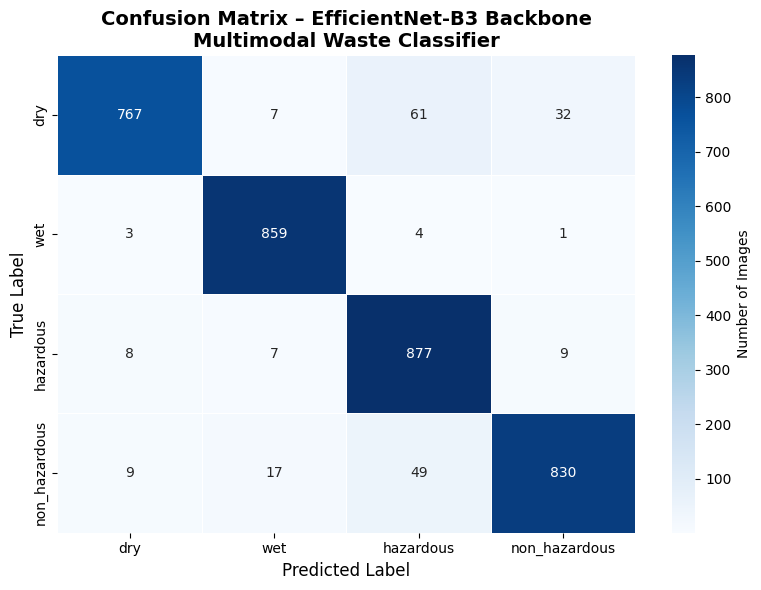

✅ Results generation complete!


In [ ]:
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import torch
import sys
import os
import importlib # Add this for module reloading
from PIL import Image
import cv2
from skimage.feature import graycomatrix, graycoprops

# Ensure correct path
sys.path.insert(0, "/content/drive/MyDrive/WASTE_AI_REBUILD")
os.chdir("/content/drive/MyDrive/WASTE_AI_REBUILD")

# --- Start Patch for dataset.py ---
DATASET_FILE_PATH = "/content/drive/MyDrive/WASTE_AI_REBUILD/dataset.py"

# Reconstruct the critical parts of dataset.py to ensure correct indentation
new_dataset_content = '''
import os, random
from pathlib import Path
import cv2, numpy as np, torch
from PIL import Image
from skimage.feature import graycomatrix, graycoprops
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

_GLCM_RESIZE = 128
_GLCM_LEVELS = 64

LABEL_MAP = {"dry": 0, "wet": 1, "hazardous": 2, "non_hazardous": 3}
CLASS_NAMES = ["dry", "wet", "hazardous", "non_hazardous"]


_TEXTURE_CACHE_GLOBAL_DICT = {}

def load_texture_cache(path):
    """Loads a texture cache file into the global dictionary."""
    global _TEXTURE_CACHE_GLOBAL_DICT
    if os.path.exists(path):
        cache = torch.load(path, map_location="cpu")
        _TEXTURE_CACHE_GLOBAL_DICT.update(cache)

def get_canonical_texture_features(img_pil):
    """Computes GLCM features for a given PIL image.
    This function uses fixed parameters (128x128, 64 levels)
    and serves as the canonical way to compute texture features
    when not available in cache or for explicit computation."""
    img = np.array(img_pil.convert("L"))
    img = cv2.resize(img, (_GLCM_RESIZE, _GLCM_RESIZE))
    img = (img / (256 // _GLCM_LEVELS)).astype(np.uint8)

    glcm = graycomatrix(
        img,
        distances=[1],
        angles=[0],
        levels=_GLCM_LEVELS,
        symmetric=True,
        normed=True
    )

    contrast    = graycoprops(glcm, 'contrast')[0, 0]
    homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
    energy      = graycoprops(glcm, 'energy')[0, 0]
    entropy     = -np.sum(glcm * np.log2(glcm + 1e-8))
    variance    = np.var(img) / _GLCM_LEVELS

    feat = torch.tensor([
        contrast / 1000.0, # Scale contrast to be in a similar range as others
        homogeneity,
        energy,
        entropy / 10.0,    # Scale entropy
        variance
    ], dtype=torch.float32)

    return feat

def get_texture_feature(path):
    """Retrieves texture features from the global cache,
    or computes them on-the-fly if not found (and adds to cache)."""
    key = os.path.abspath(path)
    try:
        return _TEXTURE_CACHE_GLOBAL_DICT[key]
    except KeyError:
        img_pil = Image.open(path).convert("RGB")
        feat = get_canonical_texture_features(img_pil)
        _TEXTURE_CACHE_GLOBAL_DICT[key] = feat
        return feat


class WasteDataset(Dataset):
    def __init__(self, image_paths, labels, transform, use_texture_features=True):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform
        self.use_texture_features = use_texture_features

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]

        img = Image.open(img_path).convert("RGB")
        img = self.transform(img)

        if self.use_texture_features:
            meta = get_texture_feature(img_path)
        else:
            meta = torch.zeros(5, dtype=torch.float32) # Placeholder if not using features

        return img, label, meta

def build_dataloaders(data_root, batch_size, val_split=0.15, test_split=0.15, random_seed=42):
    all_image_paths = []
    all_labels = []

    for class_idx, class_name in enumerate(CLASS_NAMES):
        class_dir = os.path.join(data_root, class_name)
        if os.path.exists(class_dir):
            for img_name in os.listdir(class_dir):
                if img_name.lower().endswith((".jpg", ".jpeg", ".png")):
                    all_image_paths.append(os.path.join(class_dir, img_name))
                    all_labels.append(class_idx)

    combined = list(zip(all_image_paths, all_labels))
    random.seed(random_seed)
    random.shuffle(combined)
    all_image_paths, all_labels = zip(*combined)

    num_total = len(all_image_paths)
    num_test = int(test_split * num_total)
    num_val = int(val_split * num_total)
    num_train = num_total - num_test - num_val

    train_paths, train_labels = list(all_image_paths[:num_train]), list(all_labels[:num_train])
    val_paths, val_labels = list(all_image_paths[num_train:num_train + num_val]), list(all_labels[num_train:num_train + num_val])
    test_paths, test_labels = list(all_image_paths[num_train + num_val:]), list(all_labels[num_train + num_val:])

    train_transform = get_transforms("train")
    eval_transform = get_transforms("eval")

    train_dataset = WasteDataset(train_paths, train_labels, train_transform)
    val_dataset = WasteDataset(val_paths, val_labels, eval_transform)
    test_dataset = WasteDataset(test_paths, test_labels, eval_transform)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

    print(f"📊 Total samples: {num_total}")
    print(f"TRAIN: {len(train_dataset)} | VAL: {len(val_dataset)} | TEST: {len(test_dataset)}")

    return train_loader, val_loader, test_loader

def get_transforms(split):
    if split == "train":
        return transforms.Compose([
            transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(15),
            transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])
    elif split == "eval":
        return transforms.Compose([
            transforms.Resize(256),
            transforms.CenterCrop(224),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])
    else:
        raise ValueError(f"Unknown split: {split}")
'''

with open(DATASET_FILE_PATH, "w") as f:
    f.write(new_dataset_content)
print("✅ dataset.py has been re-written with correct indentation.")
# --- End Patch for dataset.py ---

from vision_model import WasteVisionModel
from multimodal_fusion import MultimodalWasteClassifier
import dataset # Import the module itself
importlib.reload(dataset) # Reload it to ensure patches are applied
from dataset import build_dataloaders, load_texture_cache # Now import functions from reloaded module

# ── Config ──
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DATA_ROOT = "./datasets/final"
TEXTURE_CACHE = "./texture_cache.pt"
VISION_PATH = "./checkpoints/vision_best.pt"
FUSION_PATH = "./checkpoints/fusion_best.pt"
HISTORY_PATH = "./checkpoints/history.json"
CLASS_NAMES = ["dry", "wet", "hazardous", "non_hazardous"]

# ─────────────────────────────────────
# 1. Training and Validation Accuracy Curves
# ─────────────────────────────────────
print("📊 Generating Accuracy Curves...")
if os.path.exists(HISTORY_PATH):
    with open(HISTORY_PATH, "r") as f:
        history = json.load(f)

    epochs = range(1, len(history["train_acc"]) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, [acc * 100 for acc in history["train_acc"]], 'b-o', label='Training Accuracy', markersize=6)
    plt.plot(epochs, [acc * 100 for acc in history["val_acc"]], 'r-s', label='Validation Accuracy', markersize=6)

    plt.title('Training and Validation Accuracy Curves\n(EfficientNet-B3 Backbone + Multimodal Fusion)', fontsize=14, fontweight='bold')
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Accuracy (%)', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()
else:
    print("❌ history.json not found. Please re-run train.py to generate curves.")

# ─────────────────────────────────────
# 2. Confusion Matrix & Classification Report
# ─────────────────────────────────────
print("\n── Running Test Set Evaluation...")
load_texture_cache(TEXTURE_CACHE)

# Load test dataloader
_, _, test_dl = build_dataloaders(DATA_ROOT, batch_size=32)

# Load models
vision = WasteVisionModel().to(DEVICE)
fusion = MultimodalWasteClassifier(img_feat_dim=vision.feat_dim).to(DEVICE)

vision.load_state_dict(torch.load(VISION_PATH, map_location=DEVICE))
fusion.load_state_dict(torch.load(FUSION_PATH, map_location=DEVICE))

vision.eval()
fusion.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for imgs, labels, meta in test_dl:
        imgs = imgs.to(DEVICE)
        labels = labels.to(DEVICE)
        meta = meta.to(DEVICE)

        feats = vision.get_features(imgs)
        out = fusion(feats, meta)
        preds = out["logits"].argmax(1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

# Print Classification Report
print("\n" + "="*60)
print("CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

# Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES,
            linewidths=.5, cbar_kws={'label': 'Number of Images'})

plt.title('Confusion Matrix – EfficientNet-B3 Backbone\nMultimodal Waste Classifier', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

print("✅ Results generation complete!")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


📦 Loading texture cache...
📊 Building dataloaders...
📊 Total samples: 23600
TRAIN: 16520 | VAL: 3540 | TEST: 3540
🧠 Loading models...
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 102MB/s]


✅ Models loaded

🔍 Running inference on test set...


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


✅ Collected 3540 predictions
   y_true shape : (3540,)
   y_probs shape: (3540, 4)

📈 Computing metrics...


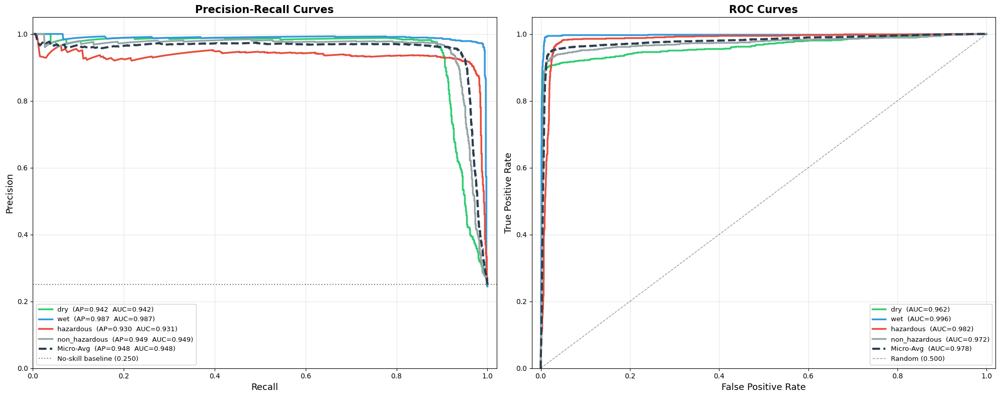

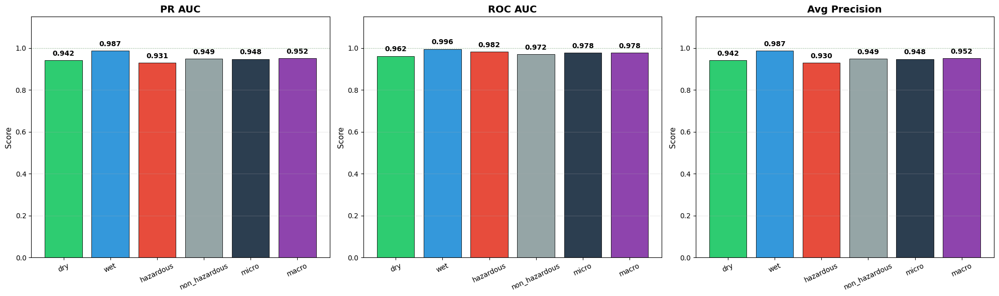

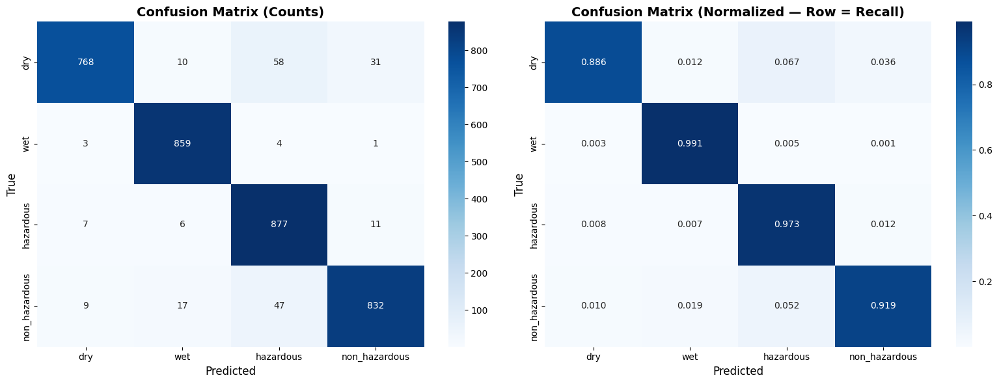

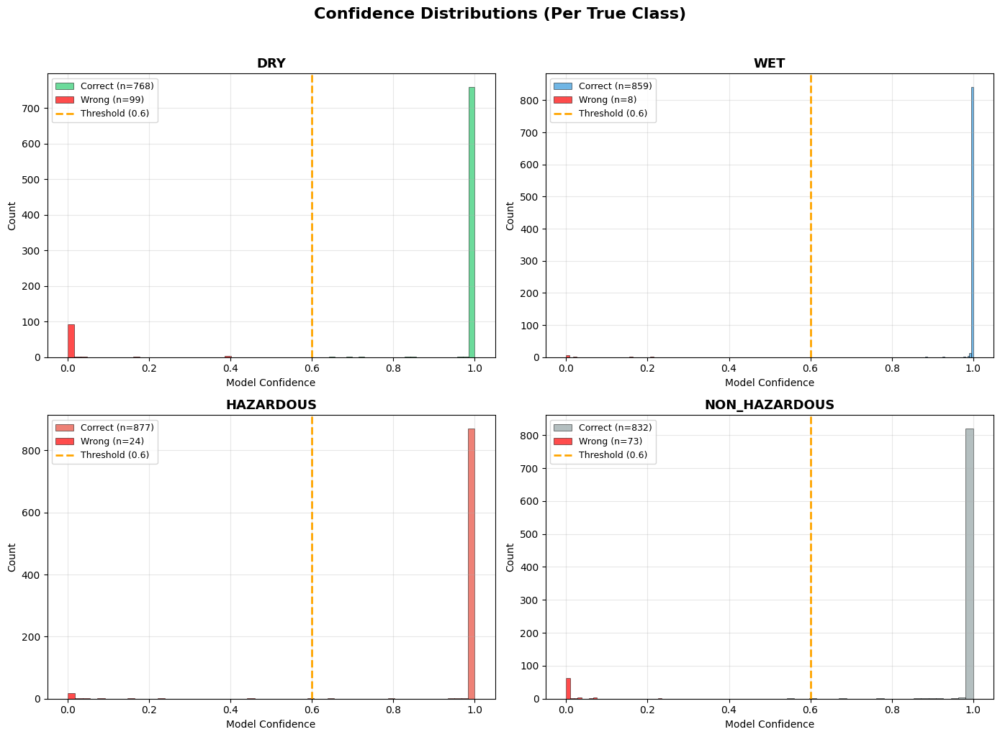


                         EVALUATION SUMMARY
Class                  PR AUC    ROC AUC     Avg Prec    Support
-------------------------------------------------------------------------------------
dry                    0.9418     0.9624       0.9418        867
wet                    0.9874     0.9957       0.9874        867
hazardous              0.9305     0.9821       0.9304        901
non_hazardous          0.9492     0.9716       0.9492        905
-------------------------------------------------------------------------------------
Micro-Avg              0.9481     0.9776       0.9481       3540
Macro-Avg              0.9522     0.9779       0.9522          —

📊 CLASSIFICATION REPORT:
-------------------------------------------------------------------------------------
               precision    recall  f1-score   support

          dry     0.9759    0.8858    0.9287       867
          wet     0.9630    0.9908    0.9767       867
    hazardous     0.8895    0.9734    0.9295      

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# CELL: Precision-Recall Curves, ROC Curves, AUC, and Summary Metrics
# ═══════════════════════════════════════════════════════════════════════════════

import sys
sys.path.insert(0, "/content/drive/MyDrive/WASTE_AI_REBUILD")

import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    roc_curve,
    auc,
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns

from vision_model import WasteVisionModel
from multimodal_fusion import MultimodalWasteClassifier
from dataset import build_dataloaders, load_texture_cache

# ─────────────────────────────────────────────────────────────────────────────
# CONFIG
# ─────────────────────────────────────────────────────────────────────────────
DEVICE        = "cuda" if torch.cuda.is_available() else "cpu"
DATA_ROOT     = "/content/drive/MyDrive/WASTE_AI_REBUILD/datasets/final"
TEXTURE_CACHE = "/content/drive/MyDrive/WASTE_AI_REBUILD/texture_cache.pt"
VISION_PATH   = "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/vision_best.pt"
FUSION_PATH   = "/content/drive/MyDrive/WASTE_AI_REBUILD/checkpoints/fusion_best.pt"
SAVE_DIR      = "/content/drive/MyDrive/WASTE_AI_REBUILD/eval_plots"

CLASS_NAMES = ["dry", "wet", "hazardous", "non_hazardous"]
N_CLASSES   = len(CLASS_NAMES)

os.makedirs(SAVE_DIR, exist_ok=True)

# ─────────────────────────────────────────────────────────────────────────────
# LOAD DATA & MODELS
# ─────────────────────────────────────────────────────────────────────────────
print("📦 Loading texture cache...")
load_texture_cache(TEXTURE_CACHE)

print("📊 Building dataloaders...")
_, _, test_dl = build_dataloaders(DATA_ROOT, batch_size=32)

print("🧠 Loading models...")
vision = WasteVisionModel().to(DEVICE)
fusion = MultimodalWasteClassifier(img_feat_dim=vision.feat_dim).to(DEVICE)

vision.load_state_dict(torch.load(VISION_PATH, map_location=DEVICE, weights_only=True))
fusion.load_state_dict(torch.load(FUSION_PATH, map_location=DEVICE, weights_only=True))

vision.eval()
fusion.eval()
print("✅ Models loaded\n")

# ─────────────────────────────────────────────────────────────────────────────
# RUN INFERENCE — COLLECT ALL PROBABILITIES
# ─────────────────────────────────────────────────────────────────────────────
print("🔍 Running inference on test set...")

all_labels = []
all_probs  = []

with torch.no_grad():
    for imgs, labels, meta in test_dl:
        imgs  = imgs.to(DEVICE)
        meta  = meta.to(DEVICE)

        feats = vision.get_features(imgs)
        out   = fusion(feats, meta)

        probs = torch.softmax(out["logits"], dim=1)

        all_labels.append(labels.cpu().numpy())
        all_probs.append(probs.cpu().numpy())

y_true  = np.concatenate(all_labels)
y_probs = np.concatenate(all_probs, axis=0)
y_pred  = y_probs.argmax(axis=1)

print(f"✅ Collected {len(y_true)} predictions")
print(f"   y_true shape : {y_true.shape}")
print(f"   y_probs shape: {y_probs.shape}\n")

# ─────────────────────────────────────────────────────────────────────────────
# BINARIZE LABELS (one-hot for multi-class metrics)
# ─────────────────────────────────────────────────────────────────────────────
y_true_bin = np.zeros((len(y_true), N_CLASSES))
for i in range(len(y_true)):
    y_true_bin[i, y_true[i]] = 1

# ─────────────────────────────────────────────────────────────────────────────
# COMPUTE PER-CLASS + MICRO/MACRO METRICS
# ─────────────────────────────────────────────────────────────────────────────
print("📈 Computing metrics...")

pr_precision = {}
pr_recall    = {}
pr_auc       = {}
avg_prec     = {}

roc_fpr  = {}
roc_tpr  = {}
roc_auc  = {}

for i, cls in enumerate(CLASS_NAMES):
    # ── Precision-Recall ──
    p, r, _ = precision_recall_curve(y_true_bin[:, i], y_probs[:, i])
    pr_precision[cls] = p
    pr_recall[cls]    = r
    pr_auc[cls]       = auc(r, p)
    avg_prec[cls]     = average_precision_score(y_true_bin[:, i], y_probs[:, i])

    # ── ROC ──
    f, t, _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
    roc_fpr[cls]  = f
    roc_tpr[cls]  = t
    roc_auc[cls]  = auc(f, t)

# Micro-average
pr_precision["micro"], pr_recall["micro"], _ = precision_recall_curve(
    y_true_bin.ravel(), y_probs.ravel()
)
pr_auc["micro"]   = auc(pr_recall["micro"], pr_precision["micro"])
avg_prec["micro"] = average_precision_score(y_true_bin, y_probs, average="micro")

roc_fpr["micro"], roc_tpr["micro"], _ = roc_curve(
    y_true_bin.ravel(), y_probs.ravel()
)
roc_auc["micro"] = auc(roc_fpr["micro"], roc_tpr["micro"])

# Macro-average
pr_auc["macro"]   = np.mean([pr_auc[c]   for c in CLASS_NAMES])
roc_auc["macro"]  = np.mean([roc_auc[c]  for c in CLASS_NAMES])
avg_prec["macro"] = np.mean([avg_prec[c] for c in CLASS_NAMES])

# ═══════════════════════════════════════════════════════════════════════════════
# PLOT 1: PRECISION-RECALL CURVES
# ═══════════════════════════════════════════════════════════════════════════════
COLORS = {
    "dry":           "#2ecc71",
    "wet":           "#3498db",
    "hazardous":     "#e74c3c",
    "non_hazardous": "#95a5a6",
    "micro":         "#2c3e50",
    "macro":         "#8e44ad"
}

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# ── Left: Per-class PR curves ──
ax = axes[0]
for cls in CLASS_NAMES:
    ax.plot(
        pr_recall[cls], pr_precision[cls],
        color=COLORS[cls], linewidth=2.5,
        label=f"{cls}  (AP={avg_prec[cls]:.3f}  AUC={pr_auc[cls]:.3f})"
    )

# Micro-average
ax.plot(
    pr_recall["micro"], pr_precision["micro"],
    color=COLORS["micro"], linewidth=3, linestyle="--",
    label=f"Micro-Avg  (AP={avg_prec['micro']:.3f}  AUC={pr_auc['micro']:.3f})"
)

# Baseline = positive class frequency
baseline = y_true_bin.sum() / y_true_bin.size
ax.axhline(baseline, color="gray", linestyle=":", linewidth=1.5,
           label=f"No-skill baseline ({baseline:.3f})")

ax.set_xlabel("Recall", fontsize=13)
ax.set_ylabel("Precision", fontsize=13)
ax.set_title("Precision-Recall Curves", fontsize=15, fontweight="bold")
ax.legend(loc="lower left", fontsize=9.5, framealpha=0.9)
ax.grid(True, alpha=0.3)
ax.set_xlim([0, 1.02])
ax.set_ylim([0, 1.05])

# ── Right: Per-class ROC curves ──
ax = axes[1]
for cls in CLASS_NAMES:
    ax.plot(
        roc_fpr[cls], roc_tpr[cls],
        color=COLORS[cls], linewidth=2.5,
        label=f"{cls}  (AUC={roc_auc[cls]:.3f})"
    )

# Micro-average
ax.plot(
    roc_fpr["micro"], roc_tpr["micro"],
    color=COLORS["micro"], linewidth=3, linestyle="--",
    label=f"Micro-Avg  (AUC={roc_auc['micro']:.3f})"
)

# Diagonal
ax.plot([0, 1], [0, 1], "k--", linewidth=1, alpha=0.4, label="Random (0.500)")

ax.set_xlabel("False Positive Rate", fontsize=13)
ax.set_ylabel("True Positive Rate", fontsize=13)
ax.set_title("ROC Curves", fontsize=15, fontweight="bold")
ax.legend(loc="lower right", fontsize=9.5, framealpha=0.9)
ax.grid(True, alpha=0.3)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([0, 1.05])

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/pr_roc_curves.png", dpi=200, bbox_inches="tight")
plt.show()


# ═══════════════════════════════════════════════════════════════════════════════
# PLOT 2: PER-CLASS CONFIDENCE DISTRIBUTIONS (bonus)
# ═══════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, cls in enumerate(CLASS_NAMES):
    ax = axes[i]

    # Correct predictions for this class
    mask_correct = (y_true == i) & (y_pred == i)
    mask_wrong   = (y_true == i) & (y_pred != i)

    correct_confs = y_probs[mask_correct, i]
    wrong_confs   = y_probs[mask_wrong, i]

    if len(correct_confs) > 0:
        ax.hist(correct_confs, bins=25, alpha=0.7, color=COLORS[cls],
                label=f"Correct (n={len(correct_confs)})", edgecolor="black", linewidth=0.5)
    if len(wrong_confs) > 0:
        ax.hist(wrong_confs, bins=25, alpha=0.7, color="red",
                label=f"Wrong (n={len(wrong_confs)})", edgecolor="black", linewidth=0.5)

    ax.axvline(0.6, color="orange", linestyle="--", linewidth=2, label="Threshold (0.6)")
    ax.set_title(f"{cls.upper()}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Model Confidence", fontsize=10)
    ax.set_ylabel("Count", fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle("Confidence Distributions (Per True Class)", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/confidence_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

# ═══════════════════════════════════════════════════════════════════════════════
# PRINT SUMMARY TABLE
# ═══════════════════════════════════════════════════════════════════════════════
print("\n" + "=" * 85)
print(" " * 25 + "EVALUATION SUMMARY")
print("=" * 85)
print(f"{'Class':<18} {'PR AUC':>10} {'ROC AUC':>10} {'Avg Prec':>12} {'Support':>10}")
print("-" * 85)

for cls in CLASS_NAMES:
    support = (y_true == CLASS_NAMES.index(cls)).sum()
    print(f"{cls:<18} {pr_auc[cls]:>10.4f} {roc_auc[cls]:>10.4f} "
          f"{avg_prec[cls]:>12.4f} {support:>10}")

print("-" * 85)
print(f"{'Micro-Avg':<18} {pr_auc['micro']:>10.4f} {roc_auc['micro']:>10.4f} "
      f"{avg_prec['micro']:>12.4f} {len(y_true):>10}")
print(f"{'Macro-Avg':<18} {pr_auc['macro']:>10.4f} {roc_auc['macro']:>10.4f} "
      f"{avg_prec['macro']:>12.4f} {'—':>10}")
print("=" * 85)

# ── Classification report ──
print("\n📊 CLASSIFICATION REPORT:")
print("-" * 85)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

# ── Human review impact estimate ──
below_threshold = (y_probs.max(axis=1) < 0.6).sum()
print(f"📈 HUMAN REVIEW IMPACT (threshold=0.6):")
print(f"   Predictions below threshold: {below_threshold} / {len(y_true)} ({below_threshold/len(y_true)*100:.1f}%)")
print(f"   Auto-classified:             {len(y_true) - below_threshold} / {len(y_true)} ({(len(y_true)-below_threshold)/len(y_true)*100:.1f}%)")

# Check accuracy on high-confidence vs low-confidence
mask_high = y_probs.max(axis=1) >= 0.6
mask_low  = ~mask_high

acc_high = (y_pred[mask_high] == y_true[mask_high]).mean() if mask_high.sum() > 0 else 0
acc_low  = (y_pred[mask_low]  == y_true[mask_low]).mean()  if mask_low.sum()  > 0 else 0

print(f"\n   Accuracy on high-confidence (≥60%): {acc_high*100:.1f}%")
print(f"   Accuracy on low-confidence  (<60%): {acc_low*100:.1f}%")
print("=" * 85)

# ── Save paths ──
print(f"\n💾 Plots saved to: {SAVE_DIR}/")
for f in sorted(os.listdir(SAVE_DIR)):
    fpath = os.path.join(SAVE_DIR, f)
    print(f"   • {f}  ({os.path.getsize(fpath):,} bytes)")

print("\n✅ Evaluation complete!")

ZIPPING THE FOLDER

In [ ]:
import os
import zipfile

SOURCE_DIR = "/content/drive/MyDrive/WASTE_AI_REBUILD"
OUTPUT_ZIP = "/content/WASTE_AI_REBUILD_COMPLETE.zip"

# Folders to ignore
SKIP_FOLDERS = ['datasets', '__pycache__', '.ipynb_checkpoints']

print("🚀 Creating COMPLETE ZIP (Including Notebook)...")

file_count = 0
with zipfile.ZipFile(OUTPUT_ZIP, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(SOURCE_DIR):

        # Skip the massive datasets folder
        dirs[:] = [d for d in dirs if d.lower() not in SKIP_FOLDERS]

        for file in files:
            # ⬇️ ADDED '.ipynb' HERE ⬇️
            if file.lower().endswith(('.py', '.pt', '.txt', '.md', '.json', '.ipynb')):
                file_path = os.path.join(root, file)
                arcname = os.path.relpath(file_path, SOURCE_DIR)
                zipf.write(file_path, arcname)
                file_count += 1

size_mb = os.path.getsize(OUTPUT_ZIP) / (1024 * 1024)

print("\n" + "="*50)
print(f"✅ COMPLETE ZIP READY!")
print(f"📊 Total files zipped: {file_count}")
print(f"📦 Final Zip Size: {size_mb:.2f} MB")
print("="*50)
print("👉 Download 'WASTE_AI_REBUILD_COMPLETE.zip' from the left sidebar.")

🚀 Creating COMPLETE ZIP (Including Notebook)...

✅ COMPLETE ZIP READY!
📊 Total files zipped: 34
📦 Final Zip Size: 219.94 MB
👉 Download 'WASTE_AI_REBUILD_COMPLETE.zip' from the left sidebar.
